In [ ]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

In [1]:
# ============================================================
# CELL 1: Inspect the Kaggle dataset (NO training here)
# ============================================================
import os, glob, collections
import pandas as pd

pd.set_option("display.max_columns", 100)
pd.set_option("display.width", 250)
pd.set_option("display.max_rows", 200)

INPUT_ROOT = "/kaggle/input"
IMG_EXTS = (".png", ".jpg", ".jpeg", ".tif", ".tiff", ".bmp")

# ---------- 1. Top-level datasets mounted ----------
print("=" * 80)
print("1. MOUNTED INPUTS")
print("=" * 80)
print(os.listdir(INPUT_ROOT) if os.path.exists(INPUT_ROOT) else "No /kaggle/input found")

# ---------- 2. Directory tree (depth-limited) + file counts per dir ----------
print("\n" + "=" * 80)
print("2. DIRECTORY TREE (file counts per folder, depth <= 5)")
print("=" * 80)
for root, dirs, files in os.walk(INPUT_ROOT):
    depth = root[len(INPUT_ROOT):].count(os.sep)
    if depth > 5:
        continue
    imgs = [f for f in files if f.lower().endswith(IMG_EXTS)]
    csvs = [f for f in files if f.lower().endswith(".csv")]
    others = [f for f in files if f not in imgs and f not in csvs]
    print(f"{'  ' * depth}{root}  | images={len(imgs)} csv={len(csvs)} other={len(others)}")
    for c in csvs:
        print(f"{'  ' * (depth + 1)}[CSV] {c}")
    for o in others[:5]:
        print(f"{'  ' * (depth + 1)}[other] {o}")

# ---------- 3. Collect all images and CSVs ----------
all_images = []
for ext in IMG_EXTS:
    all_images += glob.glob(f"{INPUT_ROOT}/**/*{ext}", recursive=True)
    all_images += glob.glob(f"{INPUT_ROOT}/**/*{ext.upper()}", recursive=True)
all_images = sorted(set(all_images))
all_csvs = sorted(set(glob.glob(f"{INPUT_ROOT}/**/*.csv", recursive=True) +
                      glob.glob(f"{INPUT_ROOT}/**/*.CSV", recursive=True)))

print("\n" + "=" * 80)
print("3. TOTALS")
print("=" * 80)
print(f"Total images found: {len(all_images)}")
print(f"Total CSV files   : {len(all_csvs)}")
for c in all_csvs:
    print("  ", c)

print("\nImage count per parent folder:")
print(pd.Series([os.path.dirname(p) for p in all_images]).value_counts().to_string())

print("\nImage extensions:")
print(pd.Series([os.path.splitext(p)[1].lower() for p in all_images]).value_counts().to_string())

print("\nFirst 5 image paths:")
for p in all_images[:5]:
    print("  ", p)

# ---------- 4. Inspect every CSV ----------
csv_data = {}
for c in all_csvs:
    print("\n" + "=" * 80)
    print(f"4. CSV: {c}")
    print("=" * 80)
    try:
        df = pd.read_csv(c)
    except Exception as e:
        print("Could not read:", e)
        continue
    csv_data[c] = df
    print("Shape:", df.shape)
    print("Columns:", list(df.columns))
    print("\nDtypes:")
    print(df.dtypes.value_counts().to_string())
    print("\nHead:")
    print(df.head())
    print("\nMissing values (total):", int(df.isna().sum().sum()))
    print("Duplicate rows:", int(df.duplicated().sum()))

# ---------- 5. Identify ID column and label columns per CSV ----------
def guess_id_col(df):
    for col in df.columns:
        if col.strip().lower() in ("id", "image", "image_id", "filename", "file", "name"):
            return col
    return df.columns[0]

def binary_cols(df, id_col):
    out = []
    for col in df.columns:
        if col == id_col:
            continue
        s = df[col].dropna()
        if pd.api.types.is_numeric_dtype(s) and set(s.unique()).issubset({0, 1}):
            out.append(col)
    return out

print("\n" + "=" * 80)
print("5. ID COLUMN / LABEL COLUMNS / CLASS FREQUENCIES")
print("=" * 80)
label_info = {}
for c, df in csv_data.items():
    id_col = guess_id_col(df)
    lab_cols = binary_cols(df, id_col)
    non_bin = [x for x in df.columns if x != id_col and x not in lab_cols]
    label_info[c] = (id_col, lab_cols)
    print(f"\n--- {os.path.basename(c)} ---")
    print(f"Guessed ID column   : {id_col}  (unique={df[id_col].nunique()} / rows={len(df)})")
    print(f"Binary (0/1) columns: {len(lab_cols)}")
    print(f"Non-binary, non-ID columns: {non_bin}")
    if lab_cols:
        freq = df[lab_cols].sum().astype(int).sort_values(ascending=False)
        freq_df = pd.DataFrame({"positives": freq, "pct": (freq / len(df) * 100).round(2)})
        print(freq_df.to_string())
        labels_per_img = df[lab_cols].sum(axis=1)
        print("\nLabels-per-image distribution (all binary cols):")
        print(labels_per_img.value_counts().sort_index().to_string())
        # Multi-label vs single-label check
        print(f"\nImages with >1 positive label: {(labels_per_img > 1).sum()} "
              f"({(labels_per_img > 1).mean() * 100:.1f}%)")
        print(f"Images with 0 positive labels: {(labels_per_img == 0).sum()}")
        # Disease_Risk consistency (only if column exists)
        dr_cols = [x for x in lab_cols if x.lower() == "disease_risk"]
        if dr_cols:
            dr = dr_cols[0]
            others = [x for x in lab_cols if x != dr]
            any_dis = (df[others].sum(axis=1) > 0).astype(int)
            print(f"\nDisease_Risk vs 'any other label positive' -> crosstab:")
            print(pd.crosstab(df[dr], any_dis, rownames=[dr], colnames=["any_other_label"]))

# ---------- 6. Image-to-label mapping check ----------
print("\n" + "=" * 80)
print("6. IMAGE <-> LABEL MAPPING CHECK")
print("=" * 80)
stem_to_paths = collections.defaultdict(list)
for p in all_images:
    stem_to_paths[os.path.splitext(os.path.basename(p))[0]].append(p)
print(f"Unique image stems: {len(stem_to_paths)} (total images {len(all_images)})")
dup_stems = {k: v for k, v in stem_to_paths.items() if len(v) > 1}
print(f"Stems appearing in more than one folder: {len(dup_stems)}")
for k in list(dup_stems)[:5]:
    print("  ", k, "->", dup_stems[k])

for c, df in csv_data.items():
    id_col, _ = label_info[c]
    ids = df[id_col].astype(str).str.strip()
    ids_stem = ids.apply(lambda x: os.path.splitext(x)[0])
    matched = ids_stem.isin(stem_to_paths.keys())
    print(f"\n{os.path.basename(c)}: {matched.sum()} / {len(df)} IDs match an image file by stem")
    print("  Sample IDs:", ids.head(5).tolist())
    if (~matched).sum() > 0:
        print("  Sample unmatched IDs:", ids[~matched].head(5).tolist())
    # which folder(s) hold this CSV's images
    folders = collections.Counter()
    for s in ids_stem[matched]:
        for p in stem_to_paths[s]:
            folders[os.path.dirname(p)] += 1
    print("  Folders containing matched images:", dict(folders))

# Images with no CSV row
all_csv_stems = set()
for c, df in csv_data.items():
    id_col, _ = label_info[c]
    all_csv_stems |= set(df[id_col].astype(str).str.strip().apply(lambda x: os.path.splitext(x)[0]))
orphans = [s for s in stem_to_paths if s not in all_csv_stems]
print(f"\nImages with no label row in any CSV: {len(orphans)}")
print("  Sample:", orphans[:10])

# ---------- 7. Cross-split leakage check (ID overlap between CSVs) ----------
print("\n" + "=" * 80)
print("7. ID OVERLAP BETWEEN CSVs (leakage check)")
print("=" * 80)
keys = list(csv_data.keys())
for i in range(len(keys)):
    for j in range(i + 1, len(keys)):
        a = set(csv_data[keys[i]][label_info[keys[i]][0]].astype(str))
        b = set(csv_data[keys[j]][label_info[keys[j]][0]].astype(str))
        print(f"{os.path.basename(keys[i])} vs {os.path.basename(keys[j])}: overlap = {len(a & b)}")

# ---------- 8. Image properties (sample) ----------
print("\n" + "=" * 80)
print("8. IMAGE PROPERTIES (random sample of up to 60)")
print("=" * 80)
try:
    from PIL import Image
    import random
    random.seed(0)
    sample = random.sample(all_images, min(60, len(all_images)))
    sizes, modes = collections.Counter(), collections.Counter()
    for p in sample:
        with Image.open(p) as im:
            sizes[im.size] += 1
            modes[im.mode] += 1
    print("Sizes (W,H):", dict(sizes))
    print("Modes:", dict(modes))
except Exception as e:
    print("Image check failed:", e)

# ---------- 9. GPU check ----------
print("\n" + "=" * 80)
print("9. ENVIRONMENT")
print("=" * 80)
try:
    import torch
    print("torch:", torch.__version__, "| CUDA available:", torch.cuda.is_available())
    if torch.cuda.is_available():
        print("GPU:", torch.cuda.get_device_name(0), "| count:", torch.cuda.device_count())
except Exception as e:
    print("torch not available:", e)
try:
    import tensorflow as tf
    print("tensorflow:", tf.__version__, "| GPUs:", tf.config.list_physical_devices("GPU"))
except Exception as e:
    print("tensorflow not available:", e)

print("\nCell 1 complete. Nothing was trained.")

1. MOUNTED INPUTS
['datasets']

2. DIRECTORY TREE (file counts per folder, depth <= 5)
/kaggle/input  | images=0 csv=0 other=0
  /kaggle/input/datasets  | images=0 csv=0 other=0
    /kaggle/input/datasets/andrewmvd  | images=0 csv=0 other=0
      /kaggle/input/datasets/andrewmvd/retinal-disease-classification  | images=0 csv=0 other=0
        /kaggle/input/datasets/andrewmvd/retinal-disease-classification/Test_Set  | images=0 csv=0 other=0
          /kaggle/input/datasets/andrewmvd/retinal-disease-classification/Test_Set/Test_Set  | images=0 csv=1 other=0
            [CSV] RFMiD_Testing_Labels.csv
        /kaggle/input/datasets/andrewmvd/retinal-disease-classification/Evaluation_Set  | images=0 csv=0 other=0
          /kaggle/input/datasets/andrewmvd/retinal-disease-classification/Evaluation_Set/Evaluation_Set  | images=0 csv=1 other=0
            [CSV] RFMiD_Validation_Labels.csv
        /kaggle/input/datasets/andrewmvd/retinal-disease-classification/Training_Set  | images=0 csv=0 oth

1. METADATA
Total rows: 3200 | label columns: 46 | disease columns: 45
Rows per split: {'train': 1920, 'val': 640, 'test': 640}
Duplicate (split, ID) keys: 0

2. FILE EXISTENCE
        sum  count
split             
test    640    640
train  1920   1920
val     640    640
train: files not in CSV = 0 | CSV IDs without file = 0
val: files not in CSV = 0 | CSV IDs without file = 0
test: files not in CSV = 0 | CSV IDs without file = 0

3. CAMERA GROUPS (derived from resolution, per paper Table 2)
Resolution counts:
 width  height
2048   1536       276
2144   1424      2427
4288   2848       497

Camera counts (paper Table 2: TOPCON 3D OCT-2000=2427, Kowa=467, TRC-NW300=306):
camera
TOPCON_3D_OCT2000    2427
Kowa_VX10a            497
TOPCON_TRC_NW300      276

Camera x split:
 split              test  train  val   All
camera                                   
Kowa_VX10a          128    277   92   497
TOPCON_3D_OCT2000   439   1493  495  2427
TOPCON_TRC_NW300     73    150   53   276
All     

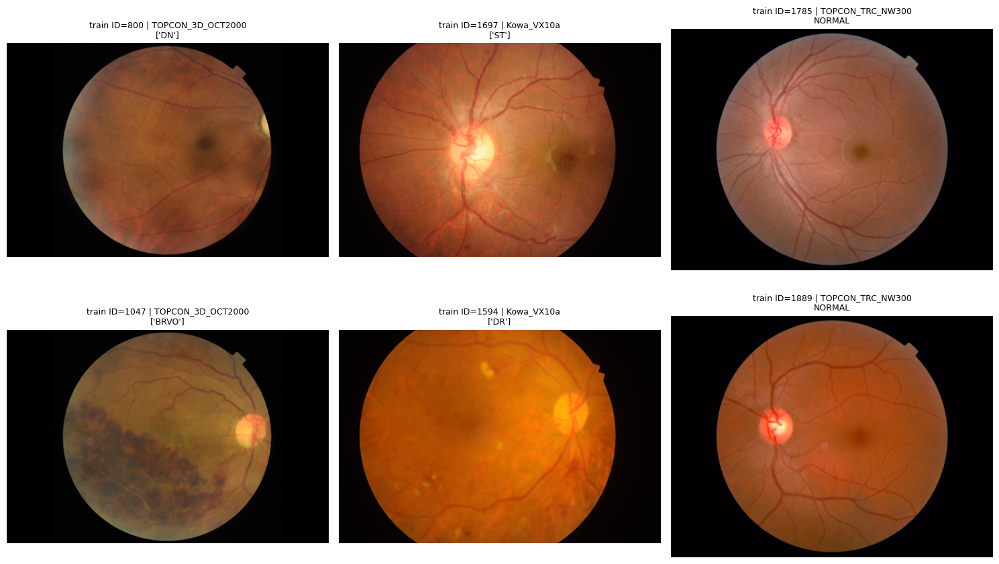


9. ENVIRONMENT FOR TRANSFER LEARNING
torch 2.10.0+cu128 | torchvision 0.25.0+cu128 | GPUs: 2
timm 1.0.26
internet -> huggingface.co: reachable
internet -> download.pytorch.org: reachable

Saved /kaggle/working/meta.csv and label_cols_interim.json
Cell 2 complete. Nothing was trained.


In [2]:
# ============================================================
# CELL 2: Build split-aware metadata + verification (NO training)
# ============================================================
import os, json, hashlib, itertools, socket
import numpy as np
import pandas as pd
from PIL import Image
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", 100)
pd.set_option("display.width", 250)
pd.set_option("display.max_rows", 200)

# Paths taken from the Cell 1 output (asserted below, not blindly trusted)
BASE = "/kaggle/input/datasets/andrewmvd/retinal-disease-classification"
SPLITS = {
    "train": dict(csv=f"{BASE}/Training_Set/Training_Set/RFMiD_Training_Labels.csv",
                  img_dir=f"{BASE}/Training_Set/Training_Set/Training"),
    "val":   dict(csv=f"{BASE}/Evaluation_Set/Evaluation_Set/RFMiD_Validation_Labels.csv",
                  img_dir=f"{BASE}/Evaluation_Set/Evaluation_Set/Validation"),
    "test":  dict(csv=f"{BASE}/Test_Set/Test_Set/RFMiD_Testing_Labels.csv",
                  img_dir=f"{BASE}/Test_Set/Test_Set/Test"),
}
for k, v in SPLITS.items():
    assert os.path.isfile(v["csv"]), f"Missing CSV for {k}: {v['csv']}"
    assert os.path.isdir(v["img_dir"]), f"Missing image dir for {k}: {v['img_dir']}"

# ---------- 1. Build metadata keyed by (split, ID) ----------
frames = []
for split, cfg in SPLITS.items():
    df = pd.read_csv(cfg["csv"])
    df["split"] = split
    df["path"] = df["ID"].astype(int).astype(str).map(lambda i: os.path.join(cfg["img_dir"], f"{i}.png"))
    frames.append(df)

base_cols = [c for c in frames[0].columns if c not in ("split", "path")]
for f in frames:
    assert [c for c in f.columns if c not in ("split", "path")] == base_cols, "CSV headers differ between splits"

meta = pd.concat(frames, ignore_index=True)
LABEL_COLS = [c for c in base_cols if c != "ID"]              # 46 = Disease_Risk + 45 diseases
DISEASE_COLS = [c for c in LABEL_COLS if c != "Disease_Risk"]  # 45
print("=" * 80); print("1. METADATA"); print("=" * 80)
print(f"Total rows: {len(meta)} | label columns: {len(LABEL_COLS)} | disease columns: {len(DISEASE_COLS)}")
print("Rows per split:", meta["split"].value_counts().to_dict())
print("Duplicate (split, ID) keys:", int(meta.duplicated(["split", "ID"]).sum()))

# ---------- 2. File existence + unexpected files ----------
print("\n" + "=" * 80); print("2. FILE EXISTENCE"); print("=" * 80)
meta["exists"] = meta["path"].map(os.path.isfile)
print(meta.groupby("split")["exists"].agg(["sum", "count"]))
for split, cfg in SPLITS.items():
    on_disk = {os.path.splitext(f)[0] for f in os.listdir(cfg["img_dir"]) if f.lower().endswith(".png")}
    in_csv = set(meta.loc[meta.split == split, "ID"].astype(int).astype(str))
    print(f"{split}: files not in CSV = {len(on_disk - in_csv)} | CSV IDs without file = {len(in_csv - on_disk)}")
assert meta["exists"].all(), "Some image files are missing, fix before continuing"

# ---------- 3. Image size (header only) -> camera group, file size ----------
print("\n" + "=" * 80); print("3. CAMERA GROUPS (derived from resolution, per paper Table 2)"); print("=" * 80)
sizes = [Image.open(p).size for p in meta["path"]]          # lazy: reads header only
meta["width"] = [s[0] for s in sizes]
meta["height"] = [s[1] for s in sizes]
meta["file_size"] = meta["path"].map(os.path.getsize)
CAM_MAP = {(2144, 1424): "TOPCON_3D_OCT2000", (4288, 2848): "Kowa_VX10a", (2048, 1536): "TOPCON_TRC_NW300"}
meta["camera"] = [CAM_MAP.get((w, h), "unknown") for w, h in zip(meta.width, meta.height)]
print("Resolution counts:\n", meta.groupby(["width", "height"]).size().to_string())
cam_counts = meta["camera"].value_counts()
print("\nCamera counts (paper Table 2: TOPCON 3D OCT-2000=2427, Kowa=467, TRC-NW300=306):")
print(cam_counts.to_string())
print("\nCamera x split:\n", pd.crosstab(meta["camera"], meta["split"], margins=True))
ct = pd.crosstab(meta["camera"], meta["Disease_Risk"])
ct["normal_%"] = (ct[0] / ct.sum(axis=1) * 100).round(1)
print("\nCamera x Disease_Risk (0=normal, 1=abnormal)  -> shortcut-learning risk if normal_% differs a lot:\n", ct)
print(f"\nTotal image data on disk: {meta.file_size.sum() / 1e9:.2f} GB")

# ---------- 4. Reconcile with paper Table 3 (total images per class) ----------
print("\n" + "=" * 80); print("4. RECONCILIATION WITH PAPER TABLE 3"); print("=" * 80)
PAPER_TOTALS = {"NL": 669, "DR": 632, "ARMD": 169, "MH": 523, "DN": 230, "MYA": 167, "BRVO": 119, "TSLN": 304,
    "ERM": 26, "LS": 79, "MS": 27, "CSR": 61, "ODC": 445, "CRVO": 45, "TV": 10, "AH": 25, "ODP": 115, "ODE": 96,
    "ST": 11, "AION": 26, "PT": 17, "RT": 25, "RS": 71, "CRS": 54, "EDN": 24, "RPEC": 32, "MHL": 17, "RP": 10,
    "CWS": 8, "CB": 2, "ODPM": 2, "PRH": 5, "MNF": 3, "HR": 1, "CRAO": 4, "TD": 9, "CME": 7, "PTCR": 6, "CF": 6,
    "VH": 4, "MCA": 1, "VS": 4, "BRAO": 4, "PLQ": 2, "HPED": 1, "CL": 2}
actual = meta[DISEASE_COLS].sum().astype(int).to_dict()
actual["NL"] = int((meta["Disease_Risk"] == 0).sum())
mismatch = {k: (PAPER_TOTALS[k], actual.get(k)) for k in PAPER_TOTALS if PAPER_TOTALS[k] != actual.get(k)}
print("Classes in paper but not in CSV:", [k for k in PAPER_TOTALS if k not in actual])
print("Classes in CSV but not in paper:", [k for k in DISEASE_COLS if k not in PAPER_TOTALS])
print("Mismatches (paper, actual):", mismatch if mismatch else "NONE - all 46 totals match Table 3")

# ---------- 5. True multi-label structure (excluding Disease_Risk) ----------
print("\n" + "=" * 80); print("5. MULTI-LABEL STRUCTURE (45 disease columns only)"); print("=" * 80)
meta["n_diseases"] = meta[DISEASE_COLS].sum(axis=1)
print(pd.crosstab(meta["n_diseases"], meta["split"]))
for s in SPLITS:
    sub = meta[meta.split == s]
    ab = sub[sub.n_diseases > 0]
    print(f"{s}: abnormal={len(ab)} | multi-disease among abnormal = {(ab.n_diseases > 1).sum()} ({(ab.n_diseases > 1).mean() * 100:.1f}%)")
assert ((meta["n_diseases"] > 0) == (meta["Disease_Risk"] == 1)).all(), "Disease_Risk not consistent with disease columns"
print("Disease_Risk == any(disease) holds for ALL rows.")

Y = meta.loc[meta.split == "train", DISEASE_COLS].values
co = Y.T @ Y
pairs = sorted([(DISEASE_COLS[i], DISEASE_COLS[j], int(co[i, j]))
                for i, j in itertools.combinations(range(len(DISEASE_COLS)), 2) if co[i, j] > 0],
               key=lambda x: -x[2])
print("\nTop 15 co-occurring disease pairs (train):")
for a, b, n in pairs[:15]:
    print(f"  {a:>5} + {b:<5} : {n}")

# ---------- 6. Per-class counts by split + tiers + evaluability ----------
print("\n" + "=" * 80); print("6. PER-CLASS COUNTS BY SPLIT"); print("=" * 80)
cnt = pd.DataFrame({s: meta[meta.split == s][LABEL_COLS].sum().astype(int) for s in SPLITS})
cnt["total"] = cnt.sum(axis=1)
cnt = cnt.sort_values("train", ascending=False)
cnt["flag"] = np.where((cnt["val"] == 0) | (cnt["test"] == 0) | (cnt["train"] == 0), "<-- 0 positives in a split", "")
print(cnt.to_string())
tr = cnt.loc[DISEASE_COLS, "train"]
tiers = {"0 train positives": tr[tr == 0], "1-4 train positives": tr[(tr >= 1) & (tr <= 4)],
         "5-19 train positives": tr[(tr >= 5) & (tr <= 19)], ">=20 train positives": tr[tr >= 20]}
print("\nTiers by training positives (45 disease classes):")
for name, s in tiers.items():
    print(f"  {name:<22} n={len(s):>2}: {list(s.index)}")
for s in SPLITS:
    ev = int((cnt.loc[DISEASE_COLS, s] > 0).sum())
    print(f"Disease classes evaluable in {s} (>=1 positive): {ev} / {len(DISEASE_COLS)}")

# ---------- 7. Exact-duplicate check across ALL images (size filter, then md5) ----------
print("\n" + "=" * 80); print("7. EXACT DUPLICATE FILES (across and within splits)"); print("=" * 80)
vc = meta["file_size"].value_counts()
cand = meta[meta["file_size"].isin(vc[vc > 1].index)]
print(f"Images sharing a byte-size with another image (need hashing): {len(cand)}")
def md5(path):
    h = hashlib.md5()
    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(1 << 20), b""):
            h.update(chunk)
    return h.hexdigest()
meta["md5"] = None
meta.loc[cand.index, "md5"] = [md5(p) for p in cand["path"]]
dups = meta.dropna(subset=["md5"]).groupby("md5").filter(lambda g: len(g) > 1)
print(f"Exact duplicate images found: {len(dups)}")
if len(dups):
    print(dups.sort_values("md5")[["md5", "split", "ID", "path"]].head(30).to_string())
    print("Cross-split duplicate groups:", int((dups.groupby("md5")["split"].nunique() > 1).sum()))
print("NOTE: near-duplicates and same-patient (left/right eye) leakage cannot be checked; no patient ID exists.")

# ---------- 8. Visual sanity check: 2 random train images per camera ----------
print("\n" + "=" * 80); print("8. VISUAL SANITY CHECK"); print("=" * 80)
rng = np.random.RandomState(0)
picks = []
for cam in CAM_MAP.values():
    sub = meta[(meta.split == "train") & (meta.camera == cam)]
    picks += list(rng.choice(sub.index, size=min(2, len(sub)), replace=False))
fig, axes = plt.subplots(2, 3, figsize=(15, 9))
for ax, idx in zip(axes.T.flatten(), picks):
    r = meta.loc[idx]
    im = Image.open(r["path"]).convert("RGB"); im.thumbnail((512, 512))
    pos = [c for c in DISEASE_COLS if r[c] == 1]
    ax.imshow(im); ax.axis("off")
    ax.set_title(f"{r['split']} ID={int(r['ID'])} | {r['camera']}\n{pos if pos else 'NORMAL'}", fontsize=9)
plt.tight_layout(); plt.show()

# ---------- 9. Environment: timm + internet (for pretrained weights) ----------
print("\n" + "=" * 80); print("9. ENVIRONMENT FOR TRANSFER LEARNING"); print("=" * 80)
import torch, torchvision
print("torch", torch.__version__, "| torchvision", torchvision.__version__, "| GPUs:", torch.cuda.device_count())
try:
    import timm; print("timm", timm.__version__)
except Exception as e:
    print("timm NOT installed:", e)
for host in ("huggingface.co", "download.pytorch.org"):
    try:
        socket.create_connection((host, 443), timeout=4).close(); print(f"internet -> {host}: reachable")
    except Exception as e:
        print(f"internet -> {host}: NOT reachable ({type(e).__name__})")

# ---------- 10. Save metadata for later cells ----------
os.makedirs("/kaggle/working", exist_ok=True)
meta.drop(columns=["exists"]).to_csv("/kaggle/working/meta.csv", index=False)
with open("/kaggle/working/label_cols_interim.json", "w") as f:
    json.dump({"label_cols": LABEL_COLS, "disease_cols": DISEASE_COLS}, f, indent=2)
print("\nSaved /kaggle/working/meta.csv and label_cols_interim.json")
print("Cell 2 complete. Nothing was trained.")

Cache dir: /kaggle/temp/cache_512 | free disk (GB): 1201.6

1. CACHE
Building cache with 4 workers ...
  train: 400/1920  (24s)
  train: 800/1920  (48s)
  train: 1200/1920  (70s)
  train: 1600/1920  (110s)
  train: 1920/1920  (154s)
  val: 400/640  (178s)
  val: 640/640  (206s)
  test: 400/640  (229s)
  test: 640/640  (263s)
Done in 264s. Saved /kaggle/working/meta_cached.csv
train: shape=(1920, 512, 512, 3) dtype=uint8
val: shape=(640, 512, 512, 3) dtype=uint8
test: shape=(640, 512, 512, 3) dtype=uint8

2. CROP QC (fundus_frac ~0.78 = full circle in square; lower = clipped circle or dark image)
                  crop_w               crop_h               crop_frac               fundus_frac              
                     min  median   max    min  median   max       min median    max         min median    max
camera                                                                                                       
Kowa_VX10a          2952  3432.0  4032   2848  2848.0  2848     0.6

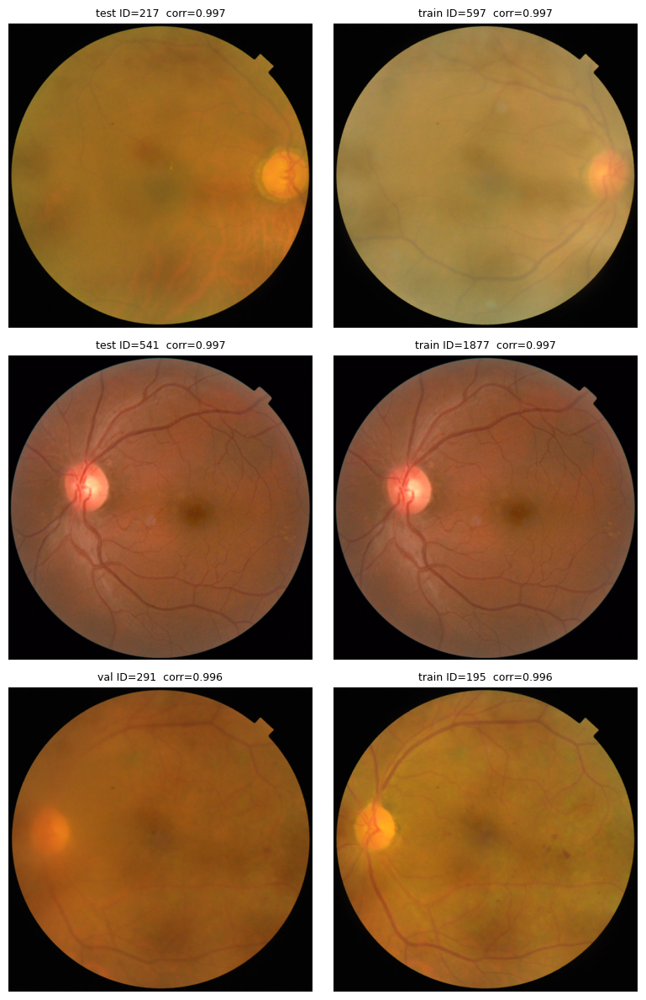


7. VISUAL QC OF CACHED IMAGES


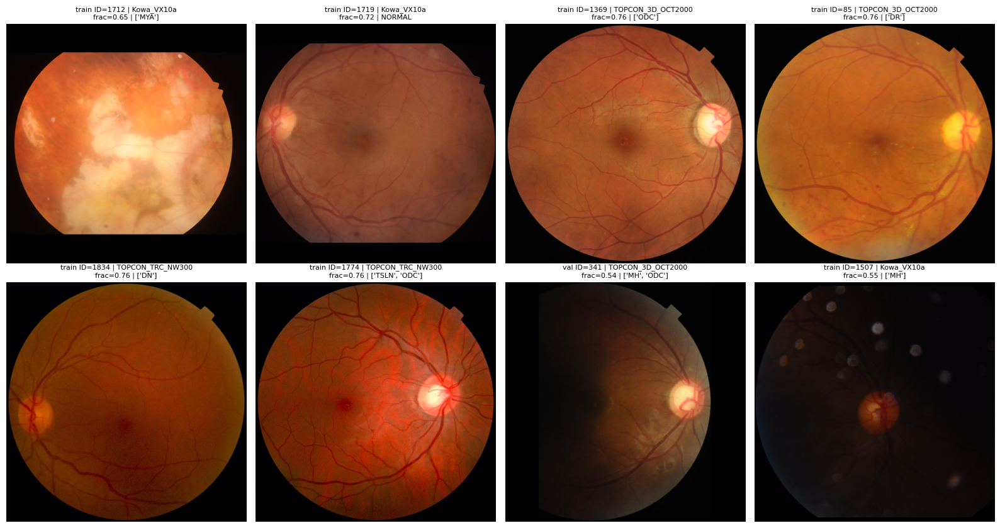


Saved /kaggle/working/cache_config.json
Cell 3 complete. Nothing was trained.


In [3]:
# ============================================================
# CELL 3: Crop black borders -> pad to square -> resize 512 -> cache (NO model training)
# ============================================================
import os, json, time, shutil
import numpy as np
import pandas as pd
from PIL import Image
from concurrent.futures import ProcessPoolExecutor
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import roc_auc_score

pd.set_option("display.max_columns", 100)
pd.set_option("display.width", 250)

S = 512            # cached resolution
BG_THR = 15        # max-channel value <= this counts as black background
REDUCE = 8         # bbox is found on a 1/8-scale copy for speed
REBUILD = False    # set True to force re-creating the cache
SPLIT_ORDER = ["train", "val", "test"]

CACHE_DIR = "/kaggle/temp/cache_512"
try:
    os.makedirs(CACHE_DIR, exist_ok=True)
except Exception:
    CACHE_DIR = "/kaggle/working/cache_512"
    os.makedirs(CACHE_DIR, exist_ok=True)
print("Cache dir:", CACHE_DIR, "| free disk (GB): %.1f" % (shutil.disk_usage(CACHE_DIR).free / 1e9))
npy_path = lambda s: f"{CACHE_DIR}/{s}_{S}.npy"
META_OUT = "/kaggle/working/meta_cached.csv"

meta = pd.read_csv("/kaggle/working/meta.csv")
cfg = json.load(open("/kaggle/working/label_cols_interim.json"))
LABEL_COLS, DISEASE_COLS = cfg["label_cols"], cfg["disease_cols"]
assert len(meta) == 3200 and meta["path"].map(os.path.isfile).all()

# ---------- worker ----------
def process_one(path):
    im = Image.open(path).convert("RGB")
    w, h = im.size
    small = np.asarray(im.reduce(REDUCE))
    m = small.max(axis=2) > BG_THR
    cols = np.where(m.sum(axis=0) >= 3)[0]
    rows = np.where(m.sum(axis=1) >= 3)[0]
    if len(cols) == 0 or len(rows) == 0:
        x0, y0, x1, y1, ok = 0, 0, w, h, 0
    else:
        x0 = max(0, (cols[0] - 1) * REDUCE);  x1 = min(w, (cols[-1] + 2) * REDUCE)
        y0 = max(0, (rows[0] - 1) * REDUCE);  y1 = min(h, (rows[-1] + 2) * REDUCE)
        ok = 1
    crop = im.crop((x0, y0, x1, y1))
    cw, ch = crop.size
    sc = S / max(cw, ch)
    nw, nh = max(1, round(cw * sc)), max(1, round(ch * sc))
    crop = crop.resize((nw, nh), Image.LANCZOS, reducing_gap=3.0)
    canvas = Image.new("RGB", (S, S), (0, 0, 0))
    canvas.paste(crop, ((S - nw) // 2, (S - nh) // 2))
    arr = np.asarray(canvas)
    fm = arr.max(axis=2) > BG_THR
    if fm.any():
        px = arr[fm].astype(np.float32); mu, sd = px.mean(0), px.std(0)
    else:
        mu, sd = np.zeros(3), np.zeros(3)
    st = dict(crop_x0=x0, crop_y0=y0, crop_w=cw, crop_h=ch, bbox_ok=ok, fundus_frac=float(fm.mean()),
              mean_r=float(mu[0]), mean_g=float(mu[1]), mean_b=float(mu[2]),
              std_r=float(sd[0]), std_g=float(sd[1]), std_b=float(sd[2]))
    return arr, st

# ---------- 1. build or load cache ----------
print("\n" + "=" * 80); print("1. CACHE"); print("=" * 80)
have = all(os.path.isfile(npy_path(s)) for s in SPLIT_ORDER) and os.path.isfile(META_OUT)
if have and not REBUILD:
    meta = pd.read_csv(META_OUT)
    print("Existing cache found -> loaded (set REBUILD=True to redo).")
else:
    n_workers = min(4, os.cpu_count() or 1)
    print(f"Building cache with {n_workers} workers ...")
    t0, rows = time.time(), []
    with ProcessPoolExecutor(max_workers=n_workers) as ex:
        for split in SPLIT_ORDER:
            sub = meta[meta.split == split]
            mm = np.lib.format.open_memmap(npy_path(split), mode="w+", dtype=np.uint8, shape=(len(sub), S, S, 3))
            for k, (arr, st) in enumerate(ex.map(process_one, sub["path"].tolist(), chunksize=4)):
                mm[k] = arr
                st["meta_index"], st["cache_idx"] = sub.index[k], k
                rows.append(st)
                if (k + 1) % 400 == 0 or k + 1 == len(sub):
                    print(f"  {split}: {k + 1}/{len(sub)}  ({time.time() - t0:.0f}s)")
            mm.flush(); del mm
    stats = pd.DataFrame(rows).set_index("meta_index")
    meta = meta.join(stats)
    meta.to_csv(META_OUT, index=False)
    print(f"Done in {time.time() - t0:.0f}s. Saved {META_OUT}")
for s in SPLIT_ORDER:
    a = np.load(npy_path(s), mmap_mode="r")
    print(f"{s}: shape={a.shape} dtype={a.dtype}")
    assert a.shape[0] == (meta.split == s).sum()

# ---------- 2. crop QC ----------
print("\n" + "=" * 80); print("2. CROP QC (fundus_frac ~0.78 = full circle in square; lower = clipped circle or dark image)"); print("=" * 80)
meta["crop_frac"] = meta["crop_w"] * meta["crop_h"] / (meta["width"] * meta["height"])
print(meta.groupby("camera")[["crop_w", "crop_h", "crop_frac", "fundus_frac"]].agg(["min", "median", "max"]).round(3).to_string())
bad = meta[(meta.fundus_frac < 0.55) | (meta.fundus_frac > 0.85) | (meta.bbox_ok == 0) | (meta.crop_frac < 0.3)]
print(f"\nImages flagged for manual review: {len(bad)}  (review flags, not automatic failures)")
print(bad.sort_values("fundus_frac")[["split", "ID", "camera", "width", "height", "crop_w", "crop_h", "fundus_frac", "crop_frac", "bbox_ok"]].head(15).to_string())

# ---------- 3. integrity: deterministic re-decode of 3 random images must equal the cache ----------
print("\n" + "=" * 80); print("3. CACHE INTEGRITY"); print("=" * 80)
rng = np.random.RandomState(1)
for i in rng.choice(len(meta), 3, replace=False):
    r = meta.iloc[i]
    arr, _ = process_one(r["path"])
    cached = np.load(npy_path(r["split"]), mmap_mode="r")[int(r["cache_idx"])]
    print(f"{r['split']} ID={int(r['ID'])}: cache == fresh decode -> {np.array_equal(arr, cached)}")
assert (meta.fundus_frac > 0).all(), "some cached image is blank"
print("No blank images.")

# ---------- 4. colour statistics per camera (fundus pixels only) ----------
print("\n" + "=" * 80); print("4. COLOUR STATS BY CAMERA"); print("=" * 80)
cs = ["mean_r", "mean_g", "mean_b", "std_r", "std_g", "std_b"]
print(meta.groupby("camera")[cs].mean().round(1).to_string())
print("\nMean RGB by camera x Disease_Risk:")
print(meta.groupby(["camera", "Disease_Risk"])[["mean_r", "mean_g", "mean_b"]].mean().round(1).to_string())

# ---------- 5. pathology-free shortcut baselines (fit on TRAIN, evaluated on VAL only; test untouched) ----------
print("\n" + "=" * 80); print("5. SHORTCUT BASELINES FOR Disease_Risk (val AUC; a deep model must clearly beat these)"); print("=" * 80)
tr, va = meta[meta.split == "train"], meta[meta.split == "val"]
CAMS = sorted(meta.camera.unique())
prior = tr.groupby("camera")["Disease_Risk"].mean()
print("Camera-only (train abnormal-rate per camera) -> val AUC: %.3f" % roc_auc_score(va.Disease_Risk, va.camera.map(prior)))
def feats(d):
    X = d[cs + ["fundus_frac"]].copy()
    for c in CAMS: X["cam_" + c] = (d.camera == c).astype(float)
    return X
clf = make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000)).fit(feats(tr), tr.Disease_Risk)
va = va.assign(p=clf.predict_proba(feats(va))[:, 1])
print("Camera + colour-stats logistic -> val AUC: %.3f" % roc_auc_score(va.Disease_Risk, va.p))
print("Same model, AUC WITHIN each camera (val):")
for c in CAMS:
    v = va[va.camera == c]
    if v.Disease_Risk.nunique() == 2:
        print(f"  {c:<20} n={len(v):>3}  normal={int((v.Disease_Risk == 0).sum()):>3}  AUC={roc_auc_score(v.Disease_Risk, v.p):.3f}")

# ---------- 6. near-duplicate check on cached images (64x64 gray, z-scored correlation) ----------
print("\n" + "=" * 80); print("6. NEAR-DUPLICATE CHECK (cross-split nearest neighbour vs within-train baseline)"); print("=" * 80)
def small_feats(split):
    a = np.load(npy_path(split), mmap_mode="r"); out = np.zeros((len(a), 64 * 64), np.float32)
    for i in range(0, len(a), 64):
        c = np.asarray(a[i:i + 64]).astype(np.float32)
        out[i:i + len(c)] = c.reshape(-1, 64, 8, 64, 8, 3).mean(axis=(2, 4, 5)).reshape(len(c), -1)
    out = (out - out.mean(1, keepdims=True)) / (out.std(1, keepdims=True) + 1e-6)
    return out
F = {s: small_feats(s) for s in SPLIT_ORDER}
M = {s: meta[meta.split == s].sort_values("cache_idx").reset_index(drop=True) for s in SPLIT_ORDER}
C = F["train"] @ F["train"].T / F["train"].shape[1]; np.fill_diagonal(C, -1)
nn_tr = C.max(1)
print("Within-train NN corr percentiles [50,90,99,max]:", np.round(np.percentile(nn_tr, [50, 90, 99, 100]), 4))
pairs = []
for q, ref in [("val", "train"), ("test", "train"), ("test", "val")]:
    Cq = F[q] @ F[ref].T / F[q].shape[1]
    nn, arg = Cq.max(1), Cq.argmax(1)
    print(f"{q:>4} -> {ref:<5} NN corr percentiles [50,90,99,max]:", np.round(np.percentile(nn, [50, 90, 99, 100]), 4),
          "| n above within-train max:", int((nn > nn_tr.max()).sum()))
    for i in np.argsort(-nn)[:5]:
        pairs.append((float(nn[i]), q, int(M[q].loc[i, "ID"]), ref, int(M[ref].loc[arg[i], "ID"]), q, i, ref, int(arg[i])))
pairs.sort(reverse=True)
print("\nTop cross-split pairs (corr, query split/ID, reference split/ID):")
for p in pairs[:8]:
    print(f"  {p[0]:.4f}  {p[1]} ID={p[2]}  <->  {p[3]} ID={p[4]}")
fig, axes = plt.subplots(3, 2, figsize=(8, 12))
for row, p in enumerate(pairs[:3]):
    for col, (s, i) in enumerate([(p[5], p[6]), (p[7], p[8])]):
        axes[row, col].imshow(np.load(npy_path(s), mmap_mode="r")[int(M[s].loc[i, "cache_idx"])]); axes[row, col].axis("off")
        axes[row, col].set_title(f"{s} ID={int(M[s].loc[i, 'ID'])}  corr={p[0]:.3f}", fontsize=9)
plt.tight_layout(); plt.show()

# ---------- 7. visual QC of cached crops ----------
print("\n" + "=" * 80); print("7. VISUAL QC OF CACHED IMAGES"); print("=" * 80)
rng = np.random.RandomState(0); picks = []
for cam in CAMS:
    sub = meta[(meta.split == "train") & (meta.camera == cam)]
    picks += list(rng.choice(sub.index, 2, replace=False))
picks += list(meta.sort_values("fundus_frac").index[:2])
fig, axes = plt.subplots(2, 4, figsize=(16, 8.5))
for ax, i in zip(axes.flatten(), picks):
    r = meta.loc[i]; ax.axis("off")
    ax.imshow(np.load(npy_path(r["split"]), mmap_mode="r")[int(r["cache_idx"])])
    pos = [c for c in DISEASE_COLS if r[c] == 1]
    ax.set_title(f"{r['split']} ID={int(r['ID'])} | {r['camera']}\nfrac={r['fundus_frac']:.2f} | {pos if pos else 'NORMAL'}", fontsize=8)
plt.tight_layout(); plt.show()

with open("/kaggle/working/cache_config.json", "w") as f:
    json.dump(dict(S=S, BG_THR=BG_THR, REDUCE=REDUCE, CACHE_DIR=CACHE_DIR, META=META_OUT,
                   npy={s: npy_path(s) for s in SPLIT_ORDER}), f, indent=2)
print("\nSaved /kaggle/working/cache_config.json")
print("Cell 3 complete. Nothing was trained.")

device: cuda

1. NEAREST-NEIGHBOUR VESSEL-STRUCTURE CORRELATION
query reference  pool   p50   p90   p99  p100  >0.3  >0.4  >0.5  >0.6 >0.8
train     train  1919 0.525 0.695 0.803 0.862 88.5% 73.4% 55.6% 31.1% 1.2%
  val       val   639 0.468 0.664 0.777 0.796 82.2% 63.0% 43.8% 20.2% 0.0%
 test      test   639 0.520 0.695 0.791 0.821 88.1% 75.2% 54.8% 32.2% 0.5%
  val     train  1920 0.510 0.688 0.804 0.902 88.6% 70.8% 52.0% 25.6% 1.1%
 test     train  1920 0.547 0.715 0.802 0.865 90.0% 80.9% 60.8% 36.4% 1.2%
 test       val   640 0.508 0.684 0.764 0.798 86.7% 71.4% 51.7% 26.9% 0.0%

All train-train pair correlations, percentiles [50, 99, 99.9, 99.99, 100]: [0.035 0.47  0.631 0.731 0.862]

2. POSITIVE CONTROLS (200 train images, synthetically shifted/rotated/rescaled/re-lit)
Reference: val->train NN corr p99 = 0.804, max = 0.902  (a true repeat must exceed these)
mild      self-corr p5/p50/p95 = 0.444/0.745/0.948 | top-1 retrieval = 87% | > val->train p99: 34% | > max: 14%
moderate  sel

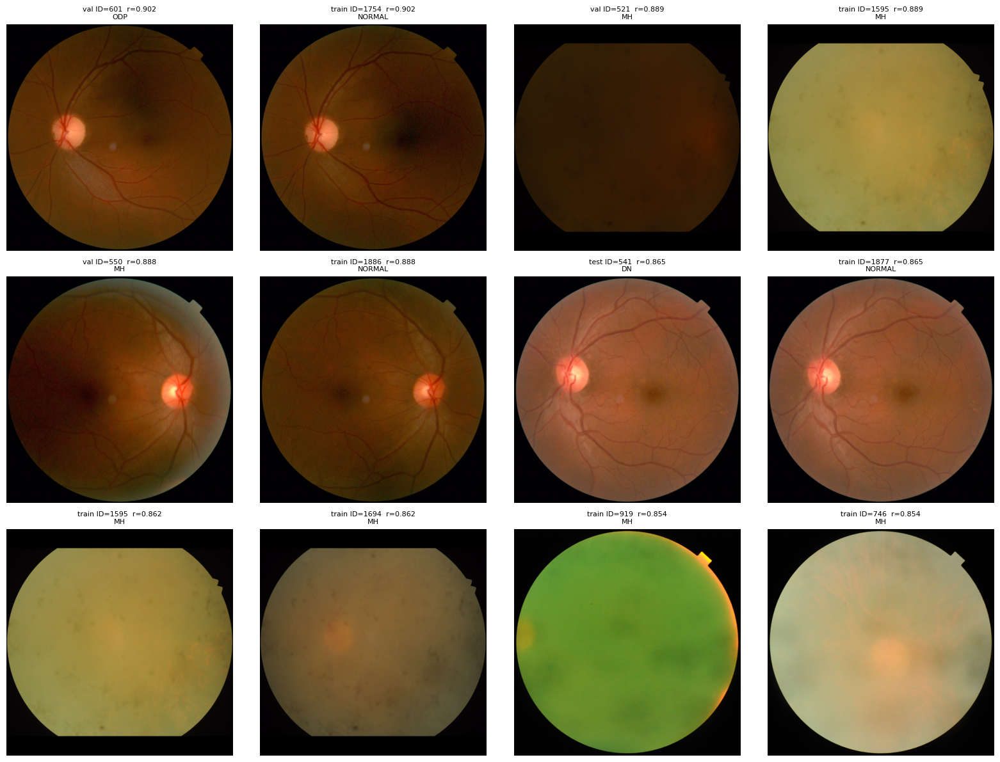


5. FLAGGED IMAGE: val ID 341
camera         TOPCON_3D_OCT2000
width                       2144
height                      1424
crop_w                      1008
crop_h                      1400
fundus_frac             0.537853
mean_r                 69.641998
mean_g                 42.476498
mean_b                 26.357565


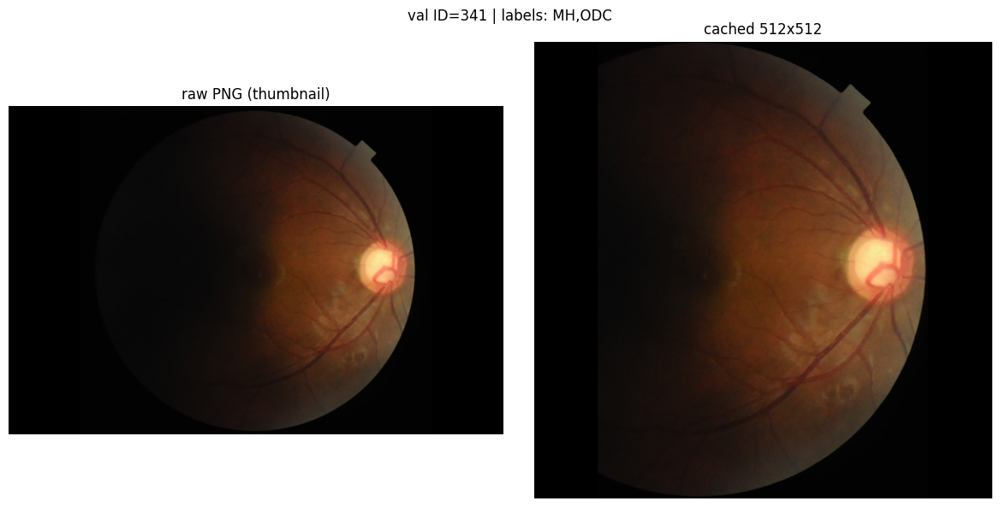


Cell 4 complete. Nothing was trained.


In [4]:
# ============================================================
# CELL 4: Leakage check v2 (vessel-structure similarity + positive controls) + flagged image
# NO model training
# ============================================================
import os, json
import numpy as np
import pandas as pd
import torch
import torchvision.transforms.functional as TF
from torchvision.transforms import InterpolationMode
from PIL import Image
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", 100); pd.set_option("display.width", 250)

cc = json.load(open("/kaggle/working/cache_config.json"))
S, NPY = cc["S"], cc["npy"]
for s, p in NPY.items():
    assert os.path.isfile(p), f"Cache file missing ({p}). Re-run Cell 3."
DISEASE_COLS = json.load(open("/kaggle/working/label_cols_interim.json"))["disease_cols"]
meta = pd.read_csv(cc["META"])
SPLITS = ["train", "val", "test"]
M = {s: meta[meta.split == s].sort_values("cache_idx").reset_index(drop=True) for s in SPLITS}
for s in SPLITS:
    assert (M[s]["cache_idx"].values == np.arange(len(M[s]))).all()   # row position == cache index
dev = "cuda" if torch.cuda.is_available() else "cpu"
print("device:", dev)

def labels_of(split, i):
    r = M[split].loc[i]
    pos = [c for c in DISEASE_COLS if r[c] == 1]
    return ",".join(pos) if pos else "NORMAL"

# ---------- features: green channel -> 128x128 -> band-pass (vessel scale) -> masked, z-scored ----------
G = 128; F_ = S // G
def load_green(split):
    a = np.load(NPY[split], mmap_mode="r")
    out = np.zeros((len(a), G, G), np.float32)
    for i in range(0, len(a), 128):
        c = np.asarray(a[i:i + 128])[..., 1].astype(np.float32)
        out[i:i + len(c)] = c.reshape(-1, G, F_, G, F_).mean(axis=(2, 4))
    return torch.from_numpy(out)
GREEN = {s: load_green(s) for s in SPLITS}

yy, xx = torch.meshgrid(torch.arange(G), torch.arange(G), indexing="ij")
MASK = (((yy - (G - 1) / 2) ** 2 + (xx - (G - 1) / 2) ** 2) <= (0.35 * G) ** 2).float().to(dev)
NPIX = MASK.sum().item()

def bandpass(g):
    g = g.to(dev).unsqueeze(1)
    d = (TF.gaussian_blur(g, [9, 9], [1.0, 1.0]) - TF.gaussian_blur(g, [25, 25], [4.0, 4.0])).squeeze(1)
    d = d * MASK
    d = (d - d.sum((1, 2), keepdim=True) / NPIX) * MASK
    d = d / ((d.pow(2).sum((1, 2), keepdim=True) / NPIX).sqrt() + 1e-6)
    return d.flatten(1)                       # dot product / NPIX == Pearson correlation inside the mask
FEAT = {s: bandpass(GREEN[s]) for s in SPLITS}
corr = lambda A, B: (A @ B.T) / NPIX

def nn_search(A, B, self_ref):
    C = corr(A, B)
    if self_ref: C.fill_diagonal_(-1.0)
    v, i = C.topk(1, dim=1)
    return C, v[:, 0].cpu().numpy(), i[:, 0].cpu().numpy()

# ---------- 1. nearest-neighbour correlation, within and across splits ----------
print("\n" + "=" * 80); print("1. NEAREST-NEIGHBOUR VESSEL-STRUCTURE CORRELATION"); print("=" * 80)
THRS = [0.3, 0.4, 0.5, 0.6, 0.8]
RES, rows, Ctt = {}, [], None
for q, r in [("train", "train"), ("val", "val"), ("test", "test"), ("val", "train"), ("test", "train"), ("test", "val")]:
    same = q == r
    C, v1, a1 = nn_search(FEAT[q], FEAT[r], same)
    RES[(q, r)] = (v1, a1)
    if (q, r) == ("train", "train"): Ctt = C
    row = {"query": q, "reference": r, "pool": len(FEAT[r]) - int(same)}
    row.update({f"p{p}": round(float(np.percentile(v1, p)), 3) for p in (50, 90, 99, 100)})
    row.update({f">{t}": f"{(v1 > t).mean() * 100:.1f}%" for t in THRS})
    rows.append(row)
print(pd.DataFrame(rows).to_string(index=False))
off = Ctt[~torch.eye(len(Ctt), dtype=torch.bool, device=Ctt.device)].cpu().numpy()
print("\nAll train-train pair correlations, percentiles [50, 99, 99.9, 99.99, 100]:",
      np.round(np.percentile(off, [50, 99, 99.9, 99.99, 100]), 3))

# ---------- 2. positive controls: can this metric find a re-photographed eye? ----------
print("\n" + "=" * 80); print("2. POSITIVE CONTROLS (200 train images, synthetically shifted/rotated/rescaled/re-lit)"); print("=" * 80)
def make_control(gs, level, seed):
    sh, rot, sc = {"mild": (2, 2.0, 0.02), "moderate": (5, 5.0, 0.05)}[level]
    r = np.random.RandomState(seed); out = []
    for g in gs:
        tx, ty = int(r.randint(-sh, sh + 1)), int(r.randint(-sh, sh + 1))
        t = TF.affine(g.unsqueeze(0), angle=float(r.uniform(-rot, rot)), translate=[tx, ty],
                      scale=float(1 + r.uniform(-sc, sc)), shear=[0.0, 0.0], interpolation=InterpolationMode.BILINEAR)
        out.append(t[0] * float(r.uniform(0.8, 1.2)))
    return torch.stack(out)
ctrl_idx = np.random.RandomState(0).choice(len(FEAT["train"]), 200, replace=False)
v_vt = RES[("val", "train")][0]
thr99, thrmax = float(np.percentile(v_vt, 99)), float(v_vt.max())
print(f"Reference: val->train NN corr p99 = {thr99:.3f}, max = {thrmax:.3f}  (a true repeat must exceed these)")
for level in ("mild", "moderate"):
    ctrl = bandpass(make_control(GREEN["train"][ctrl_idx], level, 1))
    Cc = corr(ctrl, FEAT["train"])
    tgt = torch.as_tensor(ctrl_idx, device=Cc.device)
    self_c = Cc[torch.arange(len(tgt), device=Cc.device), tgt].cpu().numpy()
    acc = float((Cc.argmax(1) == tgt).float().mean())
    p5, p50, p95 = np.percentile(self_c, [5, 50, 95])
    print(f"{level:<9} self-corr p5/p50/p95 = {p5:.3f}/{p50:.3f}/{p95:.3f} | top-1 retrieval = {acc:.0%} | "
          f"> val->train p99: {(self_c > thr99).mean():.0%} | > max: {(self_c > thrmax).mean():.0%}")

# ---------- 3. candidate cross-split near-duplicates ----------
print("\n" + "=" * 80); print("3. CANDIDATE CROSS-SPLIT NEAR-DUPLICATES (corr >= REPORT_THR)"); print("=" * 80)
REPORT_THR = 0.4
cands = []
for (q, r), (v1, a1) in RES.items():
    if q == r: continue
    for i in np.where(v1 >= REPORT_THR)[0]:
        j = int(a1[i])
        cands.append(dict(corr=round(float(v1[i]), 4), q_split=q, q_ID=int(M[q].loc[i, "ID"]), q_cam=M[q].loc[i, "camera"],
                          r_split=r, r_ID=int(M[r].loc[j, "ID"]), r_cam=M[r].loc[j, "camera"],
                          q_labels=labels_of(q, i), r_labels=labels_of(r, j)))
cols = ["corr", "q_split", "q_ID", "q_cam", "r_split", "r_ID", "r_cam", "q_labels", "r_labels"]
cdf = pd.DataFrame(cands, columns=cols).sort_values("corr", ascending=False)
cdf.to_csv("/kaggle/working/near_dup_candidates.csv", index=False)
print(f"Cross-split pairs with corr >= {REPORT_THR}: {len(cdf)}  (saved near_dup_candidates.csv)")
if len(cdf): print(cdf.head(25).to_string(index=False))

# ---------- 4. figure: top 4 cross-split pairs + top 2 within-train pairs ----------
print("\n" + "=" * 80); print("4. FIGURE: rows 1-2 = top 4 cross-split pairs, row 3 = top 2 within-train pairs"); print("=" * 80)
allx = []
for (q, r), (v1, a1) in RES.items():
    if q == r: continue
    for i in np.argsort(-v1)[:4]:
        allx.append((float(v1[i]), q, int(i), r, int(a1[i])))
allx.sort(reverse=True); show = allx[:4]
v1, a1 = RES[("train", "train")]; seen, wt = set(), []
for i in np.argsort(-v1):
    k = frozenset((int(i), int(a1[i])))
    if k in seen: continue
    seen.add(k); wt.append((float(v1[i]), "train", int(i), "train", int(a1[i])))
    if len(wt) == 2: break
show += wt
fig, axes = plt.subplots(3, 4, figsize=(16, 12))
for k, (c, q, i, r, j) in enumerate(show):
    for off_, (s, idx) in enumerate([(q, i), (r, j)]):
        ax = axes[k // 2, (k % 2) * 2 + off_]; ax.axis("off")
        ax.imshow(np.load(NPY[s], mmap_mode="r")[idx])
        ax.set_title(f"{s} ID={int(M[s].loc[idx, 'ID'])}  r={c:.3f}\n{labels_of(s, idx)}", fontsize=8)
plt.tight_layout(); plt.show()

# ---------- 5. review the flagged image (val ID 341) ----------
print("\n" + "=" * 80); print("5. FLAGGED IMAGE: val ID 341"); print("=" * 80)
r = meta[(meta.split == "val") & (meta.ID == 341)].iloc[0]
print(r[["camera", "width", "height", "crop_w", "crop_h", "fundus_frac", "mean_r", "mean_g", "mean_b"]].to_string())
raw = Image.open(r["path"]).convert("RGB"); raw.thumbnail((700, 700))
fig, axes = plt.subplots(1, 2, figsize=(12, 6))
axes[0].imshow(raw); axes[0].set_title("raw PNG (thumbnail)"); axes[0].axis("off")
axes[1].imshow(np.load(NPY["val"], mmap_mode="r")[int(r["cache_idx"])]); axes[1].set_title("cached 512x512"); axes[1].axis("off")
fig.suptitle(f"val ID=341 | labels: {labels_of('val', int(r['cache_idx']))}")
plt.tight_layout(); plt.show()

print("\nCell 4 complete. Nothing was trained.")

Loaded cache into RAM in 1s | train: X(1920, 512, 512, 3) Y(1920, 46) | val: X(640, 512, 512, 3) Y(640, 46) | test: X(640, 512, 512, 3) Y(640, 46)
RAM used by images: 2.52 GB

1. LABEL ALIGNMENT CHECKS
train: labels re-read from the original CSV match Y row-by-row  (N=1920)
val: labels re-read from the original CSV match Y row-by-row  (N=640)
test: labels re-read from the original CSV match Y row-by-row  (N=640)
Disease_Risk / DR totals per split match the earlier counts.
Cache row i <-> ID: verified by fresh re-decode in Cell 3 (3 random images).

2. REPEAT-FACTOR SAMPLING (train only)
   T  epoch_size vs_plain  abnormal_share_pct  max_repeat  imgs_repeated
0.00        1920    1.00x                79.1    1.000000              0
0.02        2134    1.11x                81.2    6.196773            273
0.05        2477    1.29x                83.8    8.000000            521
0.10        2974    1.55x                86.5    8.000000            915

Selected T=0.05, R_MAX=8.0
      train_p

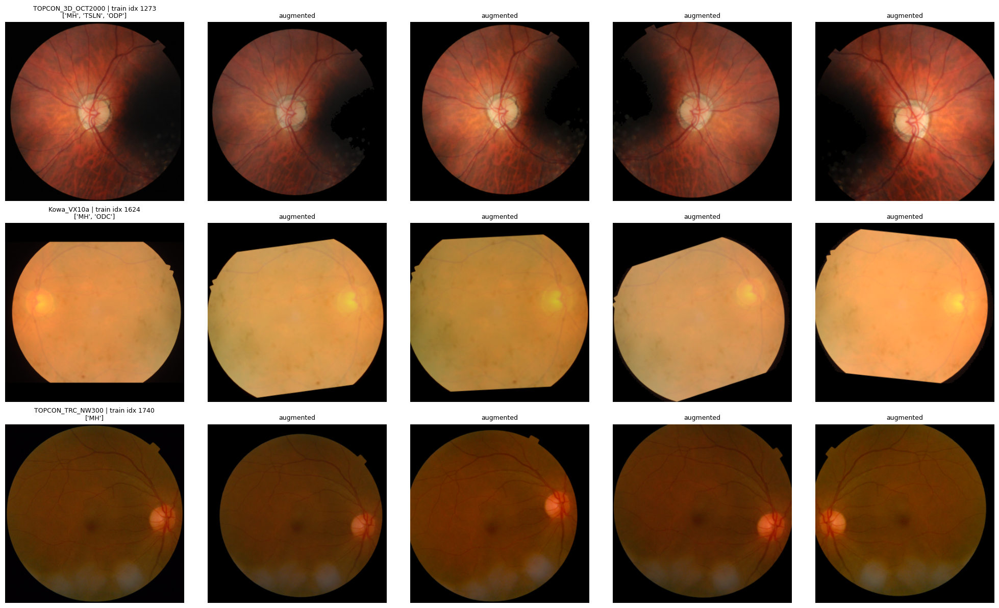


5. ONE SAMPLED BATCH: labels per image
  train idx  325 | r_i=1.1 | ['BRVO']
  train idx  243 | r_i=1.0 | ['MH']
  train idx 1513 | r_i=1.0 | ['DR']
  train idx 1220 | r_i=4.4 | ['ST']
  train idx  271 | r_i=1.1 | ['BRVO']
  train idx  675 | r_i=1.0 | ['ODC']
  train idx  560 | r_i=1.0 | ['DR']
  train idx  957 | r_i=1.0 | ['DN']
  train idx  929 | r_i=1.6 | ['CSR']
  train idx  598 | r_i=4.9 | ['ODC', 'CME']
  train idx 1683 | r_i=1.0 | NORMAL
  train idx  614 | r_i=1.0 | ['DR']

Saved /kaggle/working/label_map.json and pipeline_config.json
Cell 5 complete. No model was trained.


In [5]:
# ============================================================
# CELL 5: Training data pipeline (in-RAM cache, GPU augmentation, repeat-factor sampling)
# NO model, NO training
# ============================================================
import os, json, time, math
import numpy as np, pandas as pd, torch
import torch.nn.functional as Fnn
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", 100); pd.set_option("display.width", 250); pd.set_option("display.max_rows", 200)

# ---------------- config ----------------
SEED = 42
IMG = 384                 # network input size (cache is 512; raise later if worthwhile, tuned on VAL only)
BATCH = 32
T_RFS, R_MAX = 0.05, 8.0  # repeat-factor sampling threshold and cap
IMAGENET_MEAN, IMAGENET_STD = (0.485, 0.456, 0.406), (0.229, 0.224, 0.225)   # fixed, not fitted on any split
ROT_DEG, SCALE_JIT, TRANS = 20.0, 0.10, 0.05      # TRANS = fraction of image width
BRIGHT, CONTRAST, GAMMA_MAX, GAIN = 0.20, 0.20, 1.25, 0.08
BG = 15 / 255.0

torch.manual_seed(SEED); np.random.seed(SEED)
assert torch.cuda.is_available(), "Enable a GPU accelerator"
dev = torch.device("cuda")

# ---------------- load metadata and cache ----------------
cc = json.load(open("/kaggle/working/cache_config.json"))
S, NPY = cc["S"], cc["npy"]
for s, p in NPY.items():
    assert os.path.isfile(p), f"Cache missing: {p} -> re-run Cell 3"
cfg = json.load(open("/kaggle/working/label_cols_interim.json"))
LABEL_COLS, DISEASE_COLS = cfg["label_cols"], cfg["disease_cols"]
assert len(LABEL_COLS) == 46 and len(DISEASE_COLS) == 45 and LABEL_COLS[0] == "Disease_Risk"
LBL_IDX = {c: i for i, c in enumerate(LABEL_COLS)}
DIS_IDX = [LBL_IDX[c] for c in DISEASE_COLS]

meta = pd.read_csv(cc["META"])
SPLITS = ["train", "val", "test"]
M = {s: meta[meta.split == s].sort_values("cache_idx").reset_index(drop=True) for s in SPLITS}
for s in SPLITS:
    assert (M[s]["cache_idx"].values == np.arange(len(M[s]))).all()

t0 = time.time()
X = {s: torch.from_numpy(np.load(NPY[s])) for s in SPLITS}          # uint8 [N,512,512,3], fully in RAM
Y = {s: torch.tensor(M[s][LABEL_COLS].values, dtype=torch.float32) for s in SPLITS}
CAM = {s: M[s]["camera"].values for s in SPLITS}
print(f"Loaded cache into RAM in {time.time() - t0:.0f}s | " +
      " | ".join(f"{s}: X{tuple(X[s].shape)} Y{tuple(Y[s].shape)}" for s in SPLITS))
print("RAM used by images: %.2f GB" % (sum(x.numel() for x in X.values()) / 1e9))

# ---------------- label alignment checks ----------------
print("\n" + "=" * 80); print("1. LABEL ALIGNMENT CHECKS"); print("=" * 80)
BASE = "/kaggle/input/datasets/andrewmvd/retinal-disease-classification"
RAW_CSV = {"train": f"{BASE}/Training_Set/Training_Set/RFMiD_Training_Labels.csv",
           "val":   f"{BASE}/Evaluation_Set/Evaluation_Set/RFMiD_Validation_Labels.csv",
           "test":  f"{BASE}/Test_Set/Test_Set/RFMiD_Testing_Labels.csv"}
for s in SPLITS:
    raw = pd.read_csv(RAW_CSV[s]).set_index("ID").loc[M[s]["ID"].values, LABEL_COLS].values
    assert (raw == Y[s].numpy()).all(), f"Label mismatch in {s}"
    assert set(np.unique(Y[s].numpy())) <= {0.0, 1.0}
    assert (M[s]["ID"].values == np.sort(M[s]["ID"].values)).all() or True
    print(f"{s}: labels re-read from the original CSV match Y row-by-row  (N={len(Y[s])})")
exp = {"train": (1519, 376), "val": (506, 132), "test": (506, 124)}       # from the Cell 2 output
for s, (dr_risk, dr) in exp.items():
    assert int(Y[s][:, 0].sum()) == dr_risk and int(Y[s][:, LBL_IDX["DR"]].sum()) == dr, s
print("Disease_Risk / DR totals per split match the earlier counts.")
print("Cache row i <-> ID: verified by fresh re-decode in Cell 3 (3 random images).")

# ---------------- GPU preprocessing / augmentation ----------------
MEAN = torch.tensor(IMAGENET_MEAN, device=dev).view(1, 3, 1, 1)
STD = torch.tensor(IMAGENET_STD, device=dev).view(1, 3, 1, 1)

def to_float(xb_u8):
    """uint8 [B,H,W,3] (CPU) -> float [B,3,IMG,IMG] in [0,1] on GPU (antialiased resize)."""
    x = xb_u8.to(dev).permute(0, 3, 1, 2).contiguous().float().div_(255.0)
    if x.shape[-1] != IMG:
        x = Fnn.interpolate(x, size=(IMG, IMG), mode="bilinear", antialias=True, align_corners=False)
    return x

@torch.no_grad()
def augment(x):
    B = x.shape[0]
    u = lambda *s: torch.rand(*s, device=dev) * 2 - 1
    ang = u(B) * math.radians(ROT_DEG)
    sc = 1 + u(B) * SCALE_JIT
    tx, ty = u(B) * TRANS * 2, u(B) * TRANS * 2                    # normalised coords span 2 -> *2
    fx = 1 - 2 * (torch.rand(B, device=dev) < 0.5).float()         # horizontal flip
    cs, sn = torch.cos(ang), torch.sin(ang)
    theta = torch.stack([torch.stack([cs * fx / sc, -sn / sc, tx], 1),
                         torch.stack([sn * fx / sc,  cs / sc, ty], 1)], 1)
    grid = Fnn.affine_grid(theta, list(x.shape), align_corners=False)
    x = Fnn.grid_sample(x, grid, mode="bilinear", padding_mode="zeros", align_corners=False)
    mask = (x.amax(1, keepdim=True) > BG).float()                  # fundus pixels only
    npx = mask.sum((1, 2, 3), keepdim=True).clamp_min(1.0)
    m = (x * mask).sum((1, 2, 3), keepdim=True) / (3 * npx)
    c = 1 + u(B).view(B, 1, 1, 1) * CONTRAST
    x = ((x - m) * c + m).clamp_min(0) * mask                      # contrast about fundus mean, background stays black
    x = x.clamp(0, 1) ** (GAMMA_MAX ** u(B).view(B, 1, 1, 1))      # gamma in [1/1.25, 1.25]
    x = x * (1 + u(B).view(B, 1, 1, 1) * BRIGHT) * (1 + u(B, 3, 1, 1) * GAIN)
    return x.clamp(0, 1)

norm = lambda x: (x - MEAN) / STD
denorm = lambda x: (x * STD + MEAN).clamp(0, 1)

# ---------------- repeat-factor sampling (TRAIN only) ----------------
Ytr = Y["train"]; N = len(Ytr)
pos = Ytr[:, DIS_IDX].sum(0)                                       # [45] train positives
def rfs_factors(T, rmax):
    f = pos / N
    rc = torch.where(pos > 0, (T / f.clamp_min(1e-12)).sqrt().clamp(1.0, rmax), torch.ones_like(f))
    ri = (Ytr[:, DIS_IDX] * rc.unsqueeze(0)).amax(1).clamp_min(1.0)   # normals -> 1
    return rc, ri

def epoch_indices(ri, rng):
    base = torch.floor(ri); frac = ri - base
    n = (base + (torch.rand(len(ri), generator=rng) < frac).float()).long()
    idx = torch.repeat_interleave(torch.arange(len(ri)), n)
    return idx[torch.randperm(len(idx), generator=rng)]

RC, RI = rfs_factors(T_RFS, R_MAX)

def train_batches(rng, ri=None, batch=BATCH):
    ri = RI if ri is None else ri
    idx = epoch_indices(ri, rng)
    for b in range(len(idx) // batch):
        ii = idx[b * batch:(b + 1) * batch]
        yield norm(augment(to_float(X["train"][ii]))), Ytr[ii].to(dev), ii

def eval_batches(split, batch=64):
    for i in range(0, len(X[split]), batch):
        j = min(i + batch, len(X[split]))
        yield norm(to_float(X[split][i:j])), Y[split][i:j].to(dev), torch.arange(i, j)

# ---------------- 2. effect of repeat-factor sampling ----------------
print("\n" + "=" * 80); print("2. REPEAT-FACTOR SAMPLING (train only)"); print("=" * 80)
rows = []
for T in (0.0, 0.02, 0.05, 0.10):
    _, ri = rfs_factors(T, R_MAX)
    rows.append(dict(T=T, epoch_size=round(float(ri.sum())), vs_plain=f"{float(ri.sum()) / N:.2f}x",
                     abnormal_share_pct=round(float((Ytr[:, 0] * ri).sum() / ri.sum() * 100), 1),
                     max_repeat=float(ri.max()), imgs_repeated=int((ri > 1).sum())))
print(pd.DataFrame(rows).to_string(index=False))
print(f"\nSelected T={T_RFS}, R_MAX={R_MAX}")
exp_pos = (Ytr[:, DIS_IDX] * RI.unsqueeze(1)).sum(0)
tbl = pd.DataFrame({"train_pos": pos.long().numpy(), "r_class": RC.numpy().round(2),
                    "exp_pos_per_epoch": exp_pos.numpy().round(1),
                    "prev_before_%": (pos / N * 100).numpy().round(2),
                    "prev_after_%": (exp_pos / RI.sum() * 100).numpy().round(2)},
                   index=DISEASE_COLS).sort_values("train_pos")
print(tbl.to_string())

rng = torch.Generator().manual_seed(SEED)
idx = epoch_indices(RI, rng)
print(f"\nOne sampled epoch: {len(idx)} draws | unique images {len(idx.unique())} | max repeats of one image {int(torch.bincount(idx).max())}")
real = Ytr[idx][:, DIS_IDX].sum(0)
rare = [c for c in DISEASE_COLS if pos[DISEASE_COLS.index(c)] <= 5]
print("Realised vs expected positives/epoch for classes with <=5 train positives:")
print(pd.DataFrame({"realised": [int(real[DISEASE_COLS.index(c)]) for c in rare],
                    "expected": [float(exp_pos[DISEASE_COLS.index(c)]) for c in rare]}, index=rare).round(1).T.to_string())

# ---------------- 3. batch checks + throughput ----------------
print("\n" + "=" * 80); print("3. BATCH CHECKS AND THROUGHPUT"); print("=" * 80)
rng = torch.Generator().manual_seed(SEED + 1)
it = train_batches(rng)
xb, yb, ii = next(it)
print("train batch:", tuple(xb.shape), xb.dtype, "| y:", tuple(yb.shape), "| finite:", bool(torch.isfinite(xb).all()))
d = denorm(xb)
print(f"denormalised range [{d.min():.3f}, {d.max():.3f}] | mean per channel {[round(float(v), 3) for v in d.mean((0, 2, 3))]}")
corner = torch.cat([d[:, :, :8, :8], d[:, :, -8:, -8:]], 0)
print(f"corner-patch max after augmentation (should be ~0 = background stays black): {float(corner.max()):.4f}")
assert torch.equal(yb.cpu(), Ytr[ii]), "label/index mismatch"
xv, yv, iv = next(eval_batches("val"))
print("val batch:", tuple(xv.shape), "| y:", tuple(yv.shape), "| deterministic:",
      bool(torch.equal(xv, next(eval_batches("val"))[0])))
torch.cuda.synchronize(); t0 = time.time(); nb = 0
for xb, yb, ii in it:
    nb += 1
    if nb == 20: break
torch.cuda.synchronize(); dt = (time.time() - t0) / nb
print(f"data pipeline: {dt * 1000:.0f} ms/batch of {BATCH} ({BATCH / dt:.0f} img/s, CPU gather + GPU aug)")

# ---------------- 4. augmentation figure ----------------
print("\n" + "=" * 80); print("4. AUGMENTATION EXAMPLES (col 1 = no augmentation, cols 2-5 = random views)"); print("=" * 80)
rs = np.random.RandomState(3)
fig, axes = plt.subplots(3, 5, figsize=(20, 12))
for r_, cam in enumerate(["TOPCON_3D_OCT2000", "Kowa_VX10a", "TOPCON_TRC_NW300"]):
    i = int(rs.choice(np.where(CAM["train"] == cam)[0]))
    x0 = to_float(X["train"][[i]]); xa = augment(to_float(X["train"][[i] * 4]))
    lab = [c for c in DISEASE_COLS if Ytr[i, LBL_IDX[c]] == 1]
    for c_, im in enumerate([x0[0]] + [xa[k] for k in range(4)]):
        ax = axes[r_, c_]; ax.axis("off"); ax.imshow(im.permute(1, 2, 0).cpu().numpy())
        ax.set_title((f"{cam} | train idx {i}\n{lab if lab else 'NORMAL'}" if c_ == 0 else "augmented"), fontsize=9)
plt.tight_layout(); plt.show()

# ---------------- 5. one RFS batch (rare classes should appear) ----------------
print("\n" + "=" * 80); print("5. ONE SAMPLED BATCH: labels per image"); print("=" * 80)
xb, yb, ii = next(train_batches(torch.Generator().manual_seed(SEED + 2)))
for k in range(12):
    lab = [c for c in DISEASE_COLS if yb[k, LBL_IDX[c]] == 1]
    print(f"  train idx {int(ii[k]):>4} | r_i={float(RI[ii[k]]):.1f} | {lab if lab else 'NORMAL'}")

# ---------------- 6. save config + label mapping ----------------
json.dump({"label_cols": LABEL_COLS, "index_to_label": dict(enumerate(LABEL_COLS)), "disease_cols": DISEASE_COLS},
          open("/kaggle/working/label_map.json", "w"), indent=2)
json.dump(dict(SEED=SEED, IMG=IMG, BATCH=BATCH, T_RFS=T_RFS, R_MAX=R_MAX, MEAN=IMAGENET_MEAN, STD=IMAGENET_STD,
               ROT_DEG=ROT_DEG, SCALE_JIT=SCALE_JIT, TRANS=TRANS, BRIGHT=BRIGHT, CONTRAST=CONTRAST,
               GAMMA_MAX=GAMMA_MAX, GAIN=GAIN, augmentation="hflip+affine+brightness/contrast/gamma/channel-gain"),
          open("/kaggle/working/pipeline_config.json", "w"), indent=2)
print("\nSaved /kaggle/working/label_map.json and pipeline_config.json")
print("Cell 5 complete. No model was trained.")

In [6]:
# ============================================================
# CELL 6: Model build + pretrained check + benchmark + overfit sanity test
# Uses TRAIN images only for a tiny wiring test. Nothing saved. Val/test untouched.
# ============================================================
import time, gc
import numpy as np, pandas as pd, torch, torch.nn as nn
import timm

need = ("X", "Y", "norm", "to_float", "RI", "LABEL_COLS", "IMG", "IMAGENET_MEAN", "IMAGENET_STD", "dev")
for n_ in need:
    assert n_ in globals(), f"'{n_}' missing -> re-run Cell 5 first (kernel state lost?)"

PRIMARY = "convnext_tiny.fb_in22k_ft_in1k"
ALT = "efficientnet_b3.ra2_in1k"
N_OUT = len(LABEL_COLS)               # 46 = Disease_Risk + 45 diseases (sigmoid outputs)
Ytr = Y["train"]
print("GPU:", torch.cuda.get_device_name(0), "| total mem %.1f GB" % (torch.cuda.get_device_properties(0).total_memory / 1e9))

# prior of each output under the sampled training distribution -> initial head bias
prior = ((Ytr * RI.unsqueeze(1)).sum(0) / RI.sum()).clamp(1e-4, 1 - 1e-4)
init_bias = torch.log(prior / (1 - prior))

def build_model(name, pretrained, drop_rate=0.2, drop_path=0.1):
    m = timm.create_model(name, pretrained=pretrained, num_classes=N_OUT,
                          drop_rate=drop_rate, drop_path_rate=drop_path)
    head = m.get_classifier()
    assert isinstance(head, nn.Linear) and head.out_features == N_OUT, "unexpected classifier head"
    with torch.no_grad():
        head.bias.copy_(init_bias)
    return m.to(dev).to(memory_format=torch.channels_last)

bce = nn.functional.binary_cross_entropy_with_logits

# ---------- 1. pretrained weights actually loaded? normalisation consistent? ----------
print("\n" + "=" * 80); print("1. PRETRAINED WEIGHTS CHECK: " + PRIMARY); print("=" * 80)
m_pre = build_model(PRIMARY, pretrained=True)      # raises if the download fails (no silent random init)
pcfg = m_pre.pretrained_cfg
print({k: pcfg.get(k) for k in ("architecture", "tag", "hf_hub_id", "input_size", "crop_pct")})
print("pretrained mean/std:", pcfg["mean"], pcfg["std"], "| our fixed mean/std:", IMAGENET_MEAN, IMAGENET_STD)
print("normalisation matches pretrained config:",
      bool(np.allclose(pcfg["mean"], IMAGENET_MEAN, atol=1e-3) and np.allclose(pcfg["std"], IMAGENET_STD, atol=1e-3)))
m_rnd = build_model(PRIMARY, pretrained=False)
sp, sr = m_pre.state_dict(), m_rnd.state_dict()
ck = [k for k, v in sp.items() if v.ndim == 4]
nd = sum(not torch.equal(sp[k], sr[k]) for k in ck)
print(f"conv tensors that differ from a random init: {nd}/{len(ck)}")
assert nd > 0.9 * len(ck), "pretrained weights do not appear to be loaded"
print("params (M): %.1f | output head: %s" % (sum(p.numel() for p in m_pre.parameters()) / 1e6, tuple(m_pre.get_classifier().weight.shape)))
del m_pre, m_rnd, sp, sr; gc.collect(); torch.cuda.empty_cache()

# ---------- 2. speed / memory benchmark (random tensors, random init: weights irrelevant here) ----------
print("\n" + "=" * 80); print("2. SPEED / MEMORY (batch 32, AMP fp16, channels_last, one optimiser step per iteration)"); print("=" * 80)
def bench(name, size, bs=32, steps=8):
    m = build_model(name, pretrained=False)
    opt = torch.optim.AdamW(m.parameters(), lr=1e-4)
    scaler = torch.amp.GradScaler("cuda")
    x = torch.randn(bs, 3, size, size, device=dev).contiguous(memory_format=torch.channels_last)
    y = (torch.rand(bs, N_OUT, device=dev) < 0.05).float()
    def step():
        with torch.autocast("cuda", dtype=torch.float16):
            out = m(x)
        loss = bce(out.float(), y)
        opt.zero_grad(set_to_none=True)
        scaler.scale(loss).backward(); scaler.step(opt); scaler.update()
    torch.cuda.reset_peak_memory_stats()
    for _ in range(3): step()
    torch.cuda.synchronize(); t0 = time.time()
    for _ in range(steps): step()
    torch.cuda.synchronize(); dt = (time.time() - t0) / steps
    mem = torch.cuda.max_memory_allocated() / 1e9
    npar = sum(p.numel() for p in m.parameters()) / 1e6
    del m, opt, scaler, x, y; gc.collect(); torch.cuda.empty_cache()
    return dt, mem, npar

batches_per_epoch = int(RI.sum().item()) // 32
rows = []
for name, size in [(PRIMARY, 384), (PRIMARY, 512), (ALT, 384)]:
    try:
        dt, mem, npar = bench(name, size)
        ep = batches_per_epoch * (dt + 0.037)     # + ~37 ms/batch of data pipeline measured in Cell 5
        rows.append(dict(model=name, img=size, params_M=round(npar, 1), sec_per_step=round(dt, 3),
                         peak_mem_GB=round(mem, 1), est_train_sec_per_epoch=round(ep),
                         est_30_epochs_min=round(ep * 30 / 60, 1)))
    except torch.cuda.OutOfMemoryError:
        gc.collect(); torch.cuda.empty_cache()
        rows.append(dict(model=name, img=size, params_M=None, sec_per_step=None, peak_mem_GB="OOM",
                         est_train_sec_per_epoch=None, est_30_epochs_min=None))
print(pd.DataFrame(rows).to_string(index=False))
print(f"(estimates use {batches_per_epoch} batches/epoch from the sampled epoch size; validation adds a little)")

# ---------- 3. overfit sanity test: 32 fixed train images, no augmentation ----------
print("\n" + "=" * 80); print("3. OVERFIT SANITY TEST (32 fixed train images incl. the most-repeated rare ones)"); print("=" * 80)
torch.manual_seed(42)
g = torch.Generator().manual_seed(42)
rare_idx = torch.argsort(RI, descending=True)[:12]
rest = torch.randperm(len(RI), generator=g)
rest = rest[~torch.isin(rest, rare_idx)][:20]
ii = torch.cat([rare_idx, rest])
xb = norm(to_float(X["train"][ii])).contiguous(memory_format=torch.channels_last)
yb = Ytr[ii].to(dev)
print(f"batch: {tuple(xb.shape)} | positive labels in batch: {int(yb.sum())} | images with >=1 disease: {int((yb[:, 0] == 1).sum())}")

model = build_model(PRIMARY, pretrained=True, drop_rate=0.0, drop_path=0.0)   # regularisation off: this is a wiring test
opt = torch.optim.AdamW(model.parameters(), lr=2e-4, weight_decay=0.0)
scaler = torch.amp.GradScaler("cuda")
with torch.no_grad(), torch.autocast("cuda", dtype=torch.float16):
    model.eval(); l0 = bce(model(xb).float(), yb).item()
ref = bce(init_bias.to(dev).expand_as(yb), yb).item()
print(f"initial loss {l0:.4f} | constant-prior predictor loss {ref:.4f} (a wired model should start near this)")
model.train(); t0 = time.time()
for s in range(1, 81):
    with torch.autocast("cuda", dtype=torch.float16):
        out = model(xb)
    loss = bce(out.float(), yb)
    opt.zero_grad(set_to_none=True)
    scaler.scale(loss).backward(); scaler.unscale_(opt)
    nn.utils.clip_grad_norm_(model.parameters(), 1.0)
    scaler.step(opt); scaler.update()
    if s in (1, 10, 20, 30, 40, 60, 80):
        print(f"  step {s:>2}: loss {loss.item():.4f}")
torch.cuda.synchronize(); print(f"80 steps in {time.time() - t0:.0f}s")

model.eval()
with torch.no_grad(), torch.autocast("cuda", dtype=torch.float16):
    p = torch.sigmoid(model(xb).float())
pred = (p > 0.5).float()
npos = yb.sum().item(); tp = (pred * yb).sum().item(); fp = (pred * (1 - yb)).sum().item()
print(f"positives recovered at 0.5: {tp:.0f}/{npos:.0f} | false positives: {fp:.0f} | "
      f"images exactly right: {(pred == yb).all(1).float().mean().item() * 100:.0f}%")
ok = (tp / max(npos, 1) >= 0.95) and (fp <= 0.05 * npos)
print("VERDICT:", "PASS - labels, loss and model are wired correctly" if ok else
      "CHECK - the model did not fit 32 images; do not start the full training run, send me this output")
del model, opt, scaler, xb, yb; gc.collect(); torch.cuda.empty_cache()
print("\nCell 6 complete. Nothing saved. Val/test data not used.")

GPU: Tesla T4 | total mem 15.6 GB

1. PRETRAINED WEIGHTS CHECK: convnext_tiny.fb_in22k_ft_in1k


model.safetensors:   0%|          | 0.00/114M [00:00<?, ?B/s]

{'architecture': 'convnext_tiny', 'tag': 'fb_in22k_ft_in1k', 'hf_hub_id': 'timm/convnext_tiny.fb_in22k_ft_in1k', 'input_size': (3, 224, 224), 'crop_pct': 0.875}
pretrained mean/std: (0.485, 0.456, 0.406) (0.229, 0.224, 0.225) | our fixed mean/std: (0.485, 0.456, 0.406) (0.229, 0.224, 0.225)
normalisation matches pretrained config: True
conv tensors that differ from a random init: 22/22
params (M): 27.9 | output head: (46, 768)

2. SPEED / MEMORY (batch 32, AMP fp16, channels_last, one optimiser step per iteration)
                         model  img  params_M  sec_per_step  peak_mem_GB  est_train_sec_per_epoch  est_30_epochs_min
convnext_tiny.fb_in22k_ft_in1k  384      27.9         0.432          7.0                       36               18.0
convnext_tiny.fb_in22k_ft_in1k  512      27.9         0.795         11.5                       64               32.0
      efficientnet_b3.ra2_in1k  384      10.8         0.432          8.8                       36               18.0
(estimates u

In [7]:
# ============================================================
# CELL 7: Metrics + training loop + 1-epoch SMOKE TEST (val only; test untouched)
# ============================================================
import os, json, time, math, gc
import numpy as np, pandas as pd, torch, torch.nn as nn
from sklearn.metrics import roc_auc_score, average_precision_score, f1_score

need = ("X", "Y", "norm", "to_float", "train_batches", "eval_batches", "RI", "LABEL_COLS", "DISEASE_COLS",
        "DIS_IDX", "IMG", "BATCH", "SEED", "build_model", "PRIMARY", "bce", "dev", "IMAGENET_MEAN", "IMAGENET_STD")
for n_ in need:
    assert n_ in globals(), f"'{n_}' missing -> re-run Cells 5 and 6 (kernel state lost?)"

torch.backends.cudnn.benchmark = True
CKPT_DIR = "/kaggle/working/checkpoints"; os.makedirs(CKPT_DIR, exist_ok=True)

# ---------- metric set defined from VAL label counts (model selection only) ----------
val_pos = Y["val"].numpy()[:, DIS_IDX].sum(0)
CORE_MIN_VAL_POS = 5
CORE = [c for c, n in zip(DISEASE_COLS, val_pos) if n >= CORE_MIN_VAL_POS]
print(f"Disease classes with >= {CORE_MIN_VAL_POS} val positives (used for the selection score): {len(CORE)}")
print(CORE)

@torch.no_grad()
def predict(model, split):
    """Returns raw logits [N,46] on CPU (deterministic: no augmentation)."""
    model.eval(); out = []
    for xb, _, _ in eval_batches(split):
        with torch.autocast("cuda", dtype=torch.float16):
            lo = model(xb.contiguous(memory_format=torch.channels_last))
        out.append(lo.float().cpu())
    return torch.cat(out)

def split_metrics(logits, split, core=CORE, thr=0.5):
    y = Y[split].numpy(); p = torch.sigmoid(logits).numpy()
    res = {"loss": float(bce(logits, Y[split]))}
    res["risk_auroc"] = float(roc_auc_score(y[:, 0], p[:, 0]))
    res["risk_ap"] = float(average_precision_score(y[:, 0], p[:, 0]))
    aucs, aps, f1s = {}, {}, {}
    for c in DISEASE_COLS:
        j = LABEL_COLS.index(c); yy = y[:, j]
        if 1 <= yy.sum() < len(yy):                       # class evaluable in this split
            aucs[c] = float(roc_auc_score(yy, p[:, j]))
            aps[c] = float(average_precision_score(yy, p[:, j]))
            f1s[c] = float(f1_score(yy, p[:, j] > thr, zero_division=0))
    cc_ = [c for c in core if c in aps]
    res.update(n_eval_classes=len(aps), n_core=len(cc_),
               macro_auroc_all=float(np.mean(list(aucs.values()))), mAP_all=float(np.mean(list(aps.values()))),
               macro_auroc_core=float(np.mean([aucs[c] for c in cc_])), mAP_core=float(np.mean([aps[c] for c in cc_])),
               macro_f1_core_at_0p5=float(np.mean([f1s[c] for c in cc_])))
    res["score"] = 0.5 * res["risk_auroc"] + 0.5 * res["mAP_core"]     # checkpoint-selection score (VAL only)
    return res, aucs, aps

def run_training(epochs, tag, lr_backbone=1e-4, lr_head=5e-4, wd=0.05, warmup_epochs=1,
                 drop_rate=0.2, drop_path=0.1, seed=SEED, save=True):
    torch.manual_seed(seed); np.random.seed(seed)
    model = build_model(PRIMARY, pretrained=True, drop_rate=drop_rate, drop_path=drop_path)
    head_ids = {id(p) for p in model.get_classifier().parameters()}
    groups = {}
    for _, p in model.named_parameters():
        groups.setdefault((id(p) in head_ids, p.ndim <= 1), []).append(p)
    opt = torch.optim.AdamW([dict(params=ps, lr=(lr_head if h else lr_backbone), base_lr=(lr_head if h else lr_backbone),
                                  weight_decay=0.0 if nd else wd) for (h, nd), ps in groups.items()])
    scaler = torch.amp.GradScaler("cuda")
    spe = int(RI.sum().item()) // BATCH; total, warm = epochs * spe, max(1, warmup_epochs * spe)
    cfg = dict(tag=tag, model=PRIMARY, img=IMG, batch=BATCH, epochs=epochs, lr_backbone=lr_backbone, lr_head=lr_head,
               weight_decay=wd, warmup_epochs=warmup_epochs, drop_rate=drop_rate, drop_path=drop_path, seed=seed,
               loss="BCEWithLogits (46 outputs) + repeat-factor sampling", amp="fp16", grad_clip=1.0,
               selection="0.5*Disease_Risk AUROC + 0.5*mAP over diseases with >=5 val positives (VAL only)")
    path = f"{CKPT_DIR}/{tag}_best.pt"
    rng = torch.Generator().manual_seed(seed)
    step, best, hist = 0, -1.0, []
    torch.cuda.reset_peak_memory_stats()
    for ep in range(1, epochs + 1):
        model.train(); t0 = time.time(); tl, nb = 0.0, 0
        for xb, yb, _ in train_batches(rng):
            f = (step + 1) / warm if step < warm else 0.5 * (1 + math.cos(math.pi * min(1.0, (step - warm) / max(1, total - warm))))
            for g in opt.param_groups: g["lr"] = g["base_lr"] * max(f, 0.01)
            with torch.autocast("cuda", dtype=torch.float16):
                out = model(xb.contiguous(memory_format=torch.channels_last))
            loss = bce(out.float(), yb)
            opt.zero_grad(set_to_none=True)
            scaler.scale(loss).backward(); scaler.unscale_(opt)
            nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            scaler.step(opt); scaler.update()
            tl += loss.item(); nb += 1; step += 1
        ttrain = time.time() - t0
        m, _, _ = split_metrics(predict(model, "val"), "val")
        m.update(epoch=ep, train_loss=tl / nb, sec=round(time.time() - t0)); hist.append(m)
        star = ""
        if m["score"] > best:
            best = m["score"]; star = " *best*"
            if save:
                torch.save(dict(state_dict=model.state_dict(), epoch=ep, val_metrics=m, config=cfg, label_cols=LABEL_COLS,
                                disease_cols=DISEASE_COLS, model_name=PRIMARY, img=IMG,
                                mean=IMAGENET_MEAN, std=IMAGENET_STD), path)
        print(f"ep {ep:>2}/{epochs} | train_loss {m['train_loss']:.4f} val_loss {m['loss']:.4f} | risk_AUROC {m['risk_auroc']:.3f} "
              f"| core mAP {m['mAP_core']:.3f} core AUROC {m['macro_auroc_core']:.3f} | core F1@0.5 {m['macro_f1_core_at_0p5']:.3f} "
              f"| score {m['score']:.3f} | {m['sec']}s (train {ttrain:.0f}s, batches {nb}){star}")
    print(f"peak GPU mem: {torch.cuda.max_memory_allocated() / 1e9:.1f} GB")
    del model, opt, scaler; gc.collect(); torch.cuda.empty_cache()
    return hist, cfg, path

# ---------- SMOKE TEST: 1 epoch, then checkpoint round-trip ----------
print("\n" + "=" * 80); print("SMOKE TEST (1 epoch; low metrics are expected, we only check wiring)"); print("=" * 80)
hist, cfg, path = run_training(epochs=1, tag="smoke")
ck = torch.load(path, map_location="cpu", weights_only=False)
m2 = build_model(PRIMARY, pretrained=False); m2.load_state_dict(ck["state_dict"])
r2, _, _ = split_metrics(predict(m2, "val"), "val")
print(f"\ncheckpoint keys: {list(ck.keys())}")
print(f"saved val score {ck['val_metrics']['score']:.5f} | score after reload {r2['score']:.5f} | "
      f"match: {abs(ck['val_metrics']['score'] - r2['score']) < 1e-3}")
assert np.isfinite(hist[0]["train_loss"]) and np.isfinite(hist[0]["loss"]), "non-finite loss"
del m2; gc.collect(); torch.cuda.empty_cache(); os.remove(path)
print("Smoke checkpoint removed. Cell 7 complete. Test set not used.")

Disease classes with >= 5 val positives (used for the selection score): 21
['DR', 'ARMD', 'MH', 'DN', 'MYA', 'BRVO', 'TSLN', 'ERM', 'LS', 'MS', 'CSR', 'ODC', 'CRVO', 'ODP', 'ODE', 'AION', 'RT', 'RS', 'CRS', 'EDN', 'RPEC']

SMOKE TEST (1 epoch; low metrics are expected, we only check wiring)


ep  1/1 | train_loss 0.1097 val_loss 0.0851 | risk_AUROC 0.939 | core mAP 0.230 core AUROC 0.765 | core F1@0.5 0.041 | score 0.585 | 59s (train 38s, batches 76) *best*
peak GPU mem: 7.2 GB

checkpoint keys: ['state_dict', 'epoch', 'val_metrics', 'config', 'label_cols', 'disease_cols', 'model_name', 'img', 'mean', 'std']
saved val score 0.58458 | score after reload 0.58458 | match: True
Smoke checkpoint removed. Cell 7 complete. Test set not used.


ep  1/30 | train_loss 0.1097 val_loss 0.0851 | risk_AUROC 0.939 | core mAP 0.230 core AUROC 0.765 | core F1@0.5 0.041 | score 0.585 | 41s (train 38s, batches 76) *best*
ep  2/30 | train_loss 0.0882 val_loss 0.0667 | risk_AUROC 0.947 | core mAP 0.407 core AUROC 0.869 | core F1@0.5 0.229 | score 0.677 | 40s (train 37s, batches 77) *best*
ep  3/30 | train_loss 0.0713 val_loss 0.0592 | risk_AUROC 0.951 | core mAP 0.496 core AUROC 0.910 | core F1@0.5 0.394 | score 0.723 | 40s (train 37s, batches 77) *best*
ep  4/30 | train_loss 0.0577 val_loss 0.0519 | risk_AUROC 0.952 | core mAP 0.584 core AUROC 0.934 | core F1@0.5 0.456 | score 0.768 | 40s (train 37s, batches 77) *best*
ep  5/30 | train_loss 0.0452 val_loss 0.0535 | risk_AUROC 0.949 | core mAP 0.607 core AUROC 0.944 | core F1@0.5 0.506 | score 0.778 | 40s (train 37s, batches 77) *best*
ep  6/30 | train_loss 0.0380 val_loss 0.0528 | risk_AUROC 0.954 | core mAP 0.611 core AUROC 0.945 | core F1@0.5 0.517 | score 0.783 | 41s (train 37s, batch

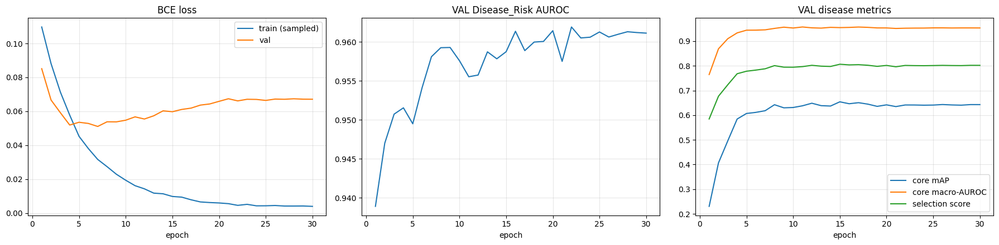


Reloaded best checkpoint (epoch 15): val score 0.8064

Per-class VAL metrics (classes with 0 val positives are omitted; <5 val positives = very noisy):
 cls  train_pos  val_pos  AUROC    AP
  DR        376      132  0.973 0.932
  MH        317      102  0.971 0.878
 ODC        282       72  0.921 0.648
TSLN        186       65  0.973 0.801
  DN        138       46  0.926 0.578
ARMD        100       38  0.977 0.650
 MYA        101       34  0.994 0.924
 ODP         65       26  0.856 0.351
BRVO         73       23  0.974 0.816
 ODE         58       21  0.984 0.833
  LS         47       17  0.993 0.849
  RS         43       14  0.998 0.943
 CSR         37       11  0.986 0.615
 CRS         32       11  0.920 0.559
CRVO         28        8  0.998 0.894
 ERM         14        7  0.878 0.206
RPEC         22        6  0.873 0.116
  RT         14        6  0.999 0.948
AION         17        5  0.999 0.853
  MS         15        5  0.889 0.097
 EDN         15        5  0.970 0.244
  AH       

In [8]:
# ============================================================
# CELL 8: FULL TRAINING (30 epochs, ConvNeXt-Tiny) - VAL only, test untouched
# ============================================================
import json, gc
import numpy as np, pandas as pd, torch
import matplotlib.pyplot as plt

for n_ in ("run_training", "split_metrics", "predict", "build_model", "PRIMARY", "CKPT_DIR", "CORE"):
    assert n_ in globals(), f"'{n_}' missing -> re-run Cell 7"

TAG, EPOCHS = "convnext_tiny_v1", 30
hist, cfg, ckpt_path = run_training(epochs=EPOCHS, tag=TAG)

# ---------- save history + config ----------
H = pd.DataFrame(hist)
H.to_csv(f"/kaggle/working/{TAG}_history.csv", index=False)
json.dump(cfg, open(f"/kaggle/working/{TAG}_train_config.json", "w"), indent=2)

b = H.loc[H["score"].idxmax()]
print("\n" + "=" * 80); print("BEST EPOCH (selected on VAL score)"); print("=" * 80)
print(b[["epoch", "train_loss", "loss", "risk_auroc", "risk_ap", "mAP_core", "macro_auroc_core",
         "macro_f1_core_at_0p5", "mAP_all", "macro_auroc_all", "n_eval_classes", "score"]].round(4).to_string())
print(f"Best epoch {int(b['epoch'])} of {EPOCHS}. If it is one of the last 2-3 epochs, training may not have converged.")

# ---------- curves ----------
fig, ax = plt.subplots(1, 3, figsize=(18, 4.5))
ax[0].plot(H.epoch, H.train_loss, label="train (sampled)"); ax[0].plot(H.epoch, H.loss, label="val"); ax[0].set_title("BCE loss"); ax[0].legend()
ax[1].plot(H.epoch, H.risk_auroc); ax[1].set_title("VAL Disease_Risk AUROC")
ax[2].plot(H.epoch, H.mAP_core, label="core mAP"); ax[2].plot(H.epoch, H.macro_auroc_core, label="core macro-AUROC")
ax[2].plot(H.epoch, H.score, label="selection score"); ax[2].set_title("VAL disease metrics"); ax[2].legend()
for a in ax: a.set_xlabel("epoch"); a.grid(alpha=.3)
plt.tight_layout(); plt.savefig(f"/kaggle/working/{TAG}_curves.png", dpi=120); plt.show()

# ---------- per-class VAL table for the best checkpoint ----------
ck = torch.load(ckpt_path, map_location="cpu", weights_only=False)
model = build_model(PRIMARY, pretrained=False); model.load_state_dict(ck["state_dict"])
res, aucs, aps = split_metrics(predict(model, "val"), "val")
print(f"\nReloaded best checkpoint (epoch {ck['epoch']}): val score {res['score']:.4f}")
tr_pos = Y["train"].numpy()[:, DIS_IDX].sum(0); va_pos = Y["val"].numpy()[:, DIS_IDX].sum(0)
rows = [dict(cls=c, train_pos=int(tr_pos[i]), val_pos=int(va_pos[i]), AUROC=aucs.get(c), AP=aps.get(c))
        for i, c in enumerate(DISEASE_COLS)]
T = pd.DataFrame(rows).sort_values(["val_pos", "train_pos"], ascending=False)
print("\nPer-class VAL metrics (classes with 0 val positives are omitted; <5 val positives = very noisy):")
print(T[T.val_pos > 0].round(3).to_string(index=False))
print("\nCheckpoint:", ckpt_path)
del model; gc.collect(); torch.cuda.empty_cache()
print("Cell 8 complete. Test set not used.")

In [9]:
# ============================================================
# CELL 9: Calibration + thresholds + per-camera shortcut check  (VAL only; test untouched)
# ============================================================
import json, gc
import numpy as np, pandas as pd, torch
from sklearn.metrics import roc_auc_score, average_precision_score, f1_score, roc_curve, brier_score_loss

for n_ in ("predict", "build_model", "PRIMARY", "CKPT_DIR", "LABEL_COLS", "DISEASE_COLS", "DIS_IDX", "CORE", "Y", "M", "bce"):
    assert n_ in globals(), f"'{n_}' missing -> re-run Cells 5-7"

TAG = "convnext_tiny_v1"
ck = torch.load(f"{CKPT_DIR}/{TAG}_best.pt", map_location="cpu", weights_only=False)
model = build_model(PRIMARY, pretrained=False); model.load_state_dict(ck["state_dict"])
lv = predict(model, "val")                       # logits [640, 46]
del model; gc.collect(); torch.cuda.empty_cache()
yv = Y["val"].numpy()
print(f"Loaded epoch {ck['epoch']} checkpoint | val logits {tuple(lv.shape)}")

def ece(p, y, bins=10):
    idx = np.clip(np.digitize(p, np.linspace(0, 1, bins + 1)) - 1, 0, bins - 1)
    return float(sum((idx == b).mean() * abs(p[idx == b].mean() - y[idx == b].mean()) for b in range(bins) if (idx == b).any()))

# ---------- 1. temperature scaling (single scalar, fitted on VAL logits of all 46 outputs) ----------
print("\n" + "=" * 80); print("1. TEMPERATURE SCALING"); print("=" * 80)
Ts = np.round(np.arange(0.5, 5.01, 0.05), 2)
losses = [float(bce(lv / t, Y["val"])) for t in Ts]
T = float(Ts[int(np.argmin(losses))])
if T in (Ts[0], Ts[-1]): print("WARNING: T at grid edge, widen the grid")
p_raw, pv = torch.sigmoid(lv).numpy(), torch.sigmoid(lv / T).numpy()
print(f"T = {T:.2f} | val BCE raw {float(bce(lv, Y['val'])):.4f} -> scaled {min(losses):.4f}")
core_j = [LABEL_COLS.index(c) for c in CORE]
flat = lambda p: p[:, core_j].ravel(); flat_y = yv[:, core_j].ravel()
for name, p in (("raw", p_raw), ("scaled", pv)):
    print(f"{name:>6}: Disease_Risk ECE {ece(p[:, 0], yv[:, 0]):.4f} Brier {brier_score_loss(yv[:, 0], p[:, 0]):.4f} | "
          f"pooled core-disease ECE {ece(flat(p), flat_y):.4f} Brier {brier_score_loss(flat_y, flat(p)):.4f}")
print("(Temperature scaling does not change any AUROC/AP; it only rescales probabilities.)")

# ---------- 2. Disease_Risk: head vs max-of-disease-probs ----------
print("\n" + "=" * 80); print("2. Disease_Risk SCORE OPTIONS (VAL)"); print("=" * 80)
risk_head, risk_max = pv[:, 0], pv[:, DIS_IDX].max(1)
print(f"prevalence of abnormal: {yv[:, 0].mean():.3f} (AP of a constant predictor = that value)")
for name, s in (("head", risk_head), ("max(disease probs)", risk_max)):
    print(f"{name:>20}: AUROC {roc_auc_score(yv[:, 0], s):.4f} | AP {average_precision_score(yv[:, 0], s):.4f}")

# ---------- 3. Disease_Risk operating points (head) ----------
print("\n" + "=" * 80); print("3. Disease_Risk OPERATING POINTS (chosen on VAL)"); print("=" * 80)
def op_metrics(y, s, t):
    pr = s >= t; tp = int((pr & (y == 1)).sum()); fp = int((pr & (y == 0)).sum())
    fn = int((~pr & (y == 1)).sum()); tn = int((~pr & (y == 0)).sum())
    return dict(thr=round(float(t), 4), acc=(tp + tn) / len(y), sens=tp / max(tp + fn, 1), spec=tn / max(tn + fp, 1),
                prec=tp / max(tp + fp, 1), f1=2 * tp / max(2 * tp + fp + fn, 1), TP=tp, FP=fp, FN=fn, TN=tn)
grid = np.unique(np.round(risk_head, 6))
f1s = [op_metrics(yv[:, 0], risk_head, t)["f1"] for t in grid]
t_f1 = float(grid[int(np.argmax(f1s))])
fpr, tpr, thr_roc = roc_curve(yv[:, 0], risk_head)
ok = np.where(tpr >= 0.95)[0]; t_sens95 = float(thr_roc[ok[0]])          # highest threshold that still gives sens >= 0.95
ops = pd.DataFrame({"max_F1": op_metrics(yv[:, 0], risk_head, t_f1),
                    "sens>=0.95 (screening)": op_metrics(yv[:, 0], risk_head, t_sens95)}).T
print(ops.round(3).to_string())
print(f"majority-class accuracy baseline: {max(yv[:, 0].mean(), 1 - yv[:, 0].mean()):.3f}")

# ---------- 4. Disease thresholds (calibrated probs) ----------
print("\n" + "=" * 80); print("4. DISEASE THRESHOLDS (chosen on VAL; core = classes with >=5 val positives)"); print("=" * 80)
G = np.round(np.arange(0.05, 0.9001, 0.025), 3)
def f1_of(c, t): j = LABEL_COLS.index(c); return f1_score(yv[:, j], pv[:, j] >= t, zero_division=0)
core_f1 = lambda tf: float(np.mean([f1_of(c, tf(c)) for c in CORE]))
f_by_t = [core_f1(lambda c, t=t: t) for t in G]
t_glob = float(G[int(np.argmax(f_by_t))])
PER_CLASS_MIN = 15
val_pos = {c: int(yv[:, LABEL_COLS.index(c)].sum()) for c in DISEASE_COLS}
per_cls = {c: float(G[int(np.argmax([f1_of(c, t) for t in G]))]) for c in CORE if val_pos[c] >= PER_CLASS_MIN}
thr_of = lambda c: per_cls.get(c, t_glob)
print(f"core macro-F1 (21 classes): @0.5 raw probs {np.mean([f1_score(yv[:, LABEL_COLS.index(c)], p_raw[:, LABEL_COLS.index(c)] >= 0.5, zero_division=0) for c in CORE]):.3f} | "
      f"@0.5 scaled {core_f1(lambda c: 0.5):.3f} | global t={t_glob:.3f}: {core_f1(lambda c: t_glob):.3f} | "
      f"global + per-class (>= {PER_CLASS_MIN} val pos, optimistic): {core_f1(thr_of):.3f}")
print("per-class thresholds:", per_cls)
rows = []
for c in CORE:
    j = LABEL_COLS.index(c); pr = pv[:, j] >= thr_of(c); y = yv[:, j]
    tp, fp, fn = int((pr & (y == 1)).sum()), int((pr & (y == 0)).sum()), int((~pr & (y == 1)).sum())
    rows.append(dict(cls=c, val_pos=val_pos[c], thr=thr_of(c), precision=tp / max(tp + fp, 1), recall=tp / max(tp + fn, 1),
                     F1=2 * tp / max(2 * tp + fp + fn, 1)))
print(pd.DataFrame(rows).round(3).to_string(index=False))

# ---------- 5. per-camera Disease_Risk (shortcut check) ----------
print("\n" + "=" * 80); print("5. Disease_Risk AUROC PER CAMERA (VAL)  [earlier pathology-free baseline in brackets]"); print("=" * 80)
cam = M["val"]["camera"].values; base = {"Kowa_VX10a": 0.605, "TOPCON_3D_OCT2000": 0.766, "TOPCON_TRC_NW300": 0.732}
for c in sorted(set(cam)):
    m = cam == c
    print(f"{c:<20} n={m.sum():>3} normal={int((yv[m, 0] == 0).sum()):>3} | AUROC {roc_auc_score(yv[m, 0], risk_head[m]):.3f}  [baseline {base[c]:.3f}]")

# ---------- 6. save ----------
json.dump(dict(tag=TAG, epoch=int(ck["epoch"]), temperature=T, risk_thr_maxF1=t_f1, risk_thr_sens95=t_sens95,
               disease_thr_global=t_glob, disease_thr_per_class=per_cls, per_class_min_val_pos=PER_CLASS_MIN,
               core_classes=CORE, note="all values fitted on VAL only"),
          open("/kaggle/working/calibration_thresholds.json", "w"), indent=2)
print("\nSaved /kaggle/working/calibration_thresholds.json")
print("Cell 9 complete. Test set not used.")

Loaded epoch 15 checkpoint | val logits (640, 46)

1. TEMPERATURE SCALING
T = 1.65 | val BCE raw 0.0598 -> scaled 0.0482
   raw: Disease_Risk ECE 0.0787 Brier 0.0822 | pooled core-disease ECE 0.0171 Brier 0.0229
scaled: Disease_Risk ECE 0.0680 Brier 0.0749 | pooled core-disease ECE 0.0073 Brier 0.0214
(Temperature scaling does not change any AUROC/AP; it only rescales probabilities.)

2. Disease_Risk SCORE OPTIONS (VAL)
prevalence of abnormal: 0.791 (AP of a constant predictor = that value)
                head: AUROC 0.9587 | AP 0.9899
  max(disease probs): AUROC 0.9435 | AP 0.9840

3. Disease_Risk OPERATING POINTS (chosen on VAL)
                          thr    acc   sens   spec   prec     f1     TP    FP    FN     TN
max_F1                  0.476  0.911  0.913  0.903  0.973  0.942  462.0  13.0  44.0  121.0
sens>=0.95 (screening)  0.108  0.891  0.951  0.664  0.914  0.932  481.0  45.0  25.0   89.0
majority-class accuracy baseline: 0.791

4. DISEASE THRESHOLDS (chosen on VAL; core = c

Frozen: epoch 15 | T=1.65 | risk thr maxF1=0.475, sens95=0.108 | disease global thr=0.25 | per-class: {'DR': 0.75, 'ARMD': 0.3, 'MH': 0.25, 'DN': 0.275, 'MYA': 0.45, 'BRVO': 0.575, 'TSLN': 0.4, 'LS': 0.55, 'ODC': 0.275, 'ODP': 0.275, 'ODE': 0.825}
test logits (640, 46) saved to /kaggle/working/test_results

1. Disease_Risk (abnormal vs normal) - TEST
test n=640 | abnormal=506 (0.791) | majority-class accuracy 0.791 | AP of constant predictor 0.791
AUROC 0.9835 | PR-AUC (AP) 0.9959
                     thr    acc   sens   spec   prec     f1     TP    FP    FN     TN
maxF1_thr          0.476  0.933  0.923  0.970  0.992  0.956  467.0   4.0  39.0  130.0
screen_sens95_thr  0.108  0.950  0.966  0.888  0.970  0.968  489.0  15.0  17.0  119.0

Per camera (TEST):
  Kowa_VX10a           n=128 normal= 50 abnormal= 78 | AUROC 0.992 | sens 0.87 spec 1.00 | sens 0.95 spec 0.98
  TOPCON_3D_OCT2000    n=439 normal= 32 abnormal=407 | AUROC 0.983 | sens 0.96 spec 0.91 | sens 0.99 spec 0.72
  TOPCON_TRC_N

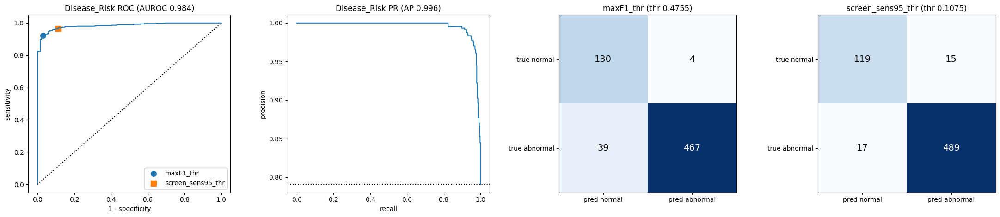

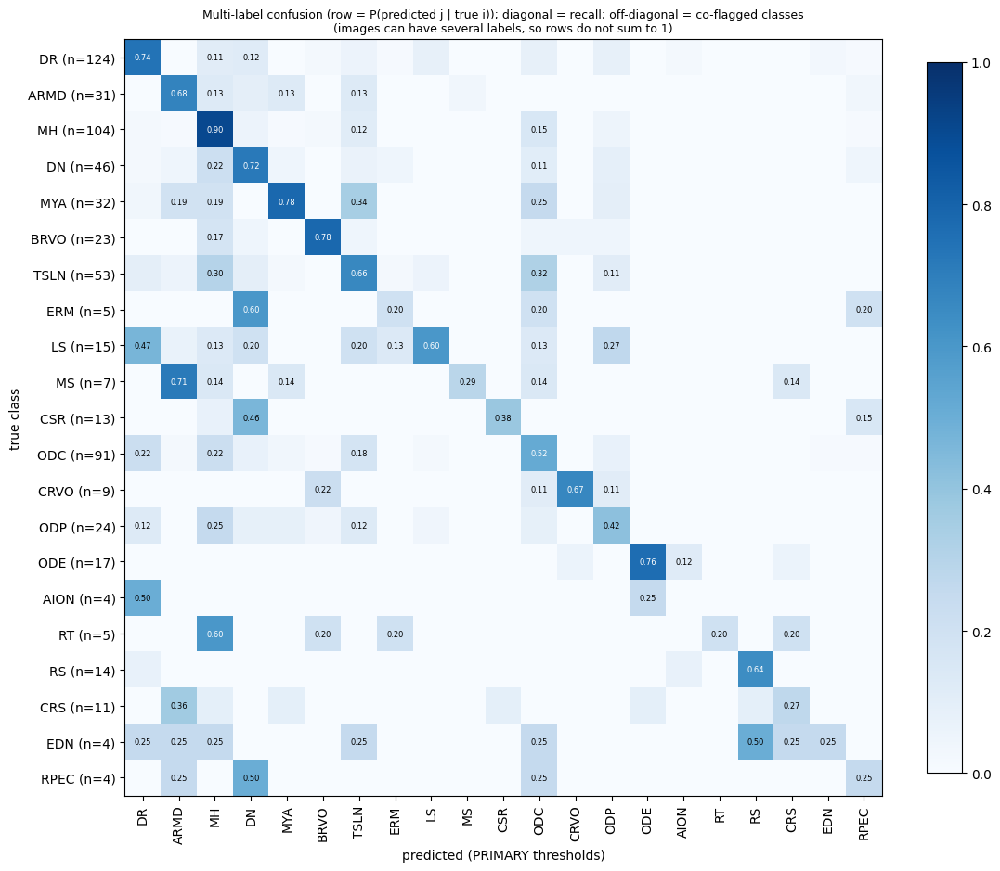


Saved to /kaggle/working/test_results: test_summary.json, per_class_test_metrics.csv, test_predictions.csv, test_logits.npy, figures
Cell 10 complete. Test set is now FROZEN: no threshold/model/hyperparameter changes based on it.


In [10]:
# ============================================================
# CELL 10: FINAL TEST EVALUATION (single pass; everything frozen from VAL)
# ============================================================
import os, json, gc
import numpy as np, pandas as pd, torch
import matplotlib.pyplot as plt
from sklearn.metrics import roc_auc_score, average_precision_score, roc_curve, precision_recall_curve

for n_ in ("predict", "build_model", "PRIMARY", "CKPT_DIR", "LABEL_COLS", "DISEASE_COLS", "DIS_IDX", "CORE", "Y", "M"):
    assert n_ in globals(), f"'{n_}' missing -> re-run Cells 5-7"
TAG = "convnext_tiny_v1"; OUT = "/kaggle/working/test_results"; os.makedirs(OUT, exist_ok=True)

# ---------- load frozen artefacts ----------
ck = torch.load(f"{CKPT_DIR}/{TAG}_best.pt", map_location="cpu", weights_only=False)
cal = json.load(open("/kaggle/working/calibration_thresholds.json"))
assert cal["epoch"] == ck["epoch"] and cal["core_classes"] == CORE, "calibration file does not match checkpoint"
T, t_glob, per_cls = cal["temperature"], cal["disease_thr_global"], cal["disease_thr_per_class"]
t_f1, t_s95 = cal["risk_thr_maxF1"], cal["risk_thr_sens95"]
print(f"Frozen: epoch {ck['epoch']} | T={T} | risk thr maxF1={t_f1:.3f}, sens95={t_s95:.3f} | disease global thr={t_glob} | per-class: {per_cls}")

model = build_model(PRIMARY, pretrained=False); model.load_state_dict(ck["state_dict"])
lt = predict(model, "test"); del model; gc.collect(); torch.cuda.empty_cache()
pt = torch.sigmoid(lt / T).numpy(); yt = Y["test"].numpy(); n = len(yt)
cam = M["test"]["camera"].values
np.save(f"{OUT}/test_logits.npy", lt.numpy()); np.save(f"{OUT}/test_probs_calibrated.npy", pt)
pd.concat([M["test"][["ID", "camera"]], pd.DataFrame(pt, columns=[f"p_{c}" for c in LABEL_COLS]),
           pd.DataFrame(yt, columns=[f"y_{c}" for c in LABEL_COLS])], axis=1).to_csv(f"{OUT}/test_predictions.csv", index=False)
print(f"test logits {tuple(lt.shape)} saved to {OUT}")

def cm2(y, pr):
    return (int((pr & (y == 1)).sum()), int((pr & (y == 0)).sum()), int((~pr & (y == 1)).sum()), int((~pr & (y == 0)).sum()))
def prf(tp, fp, fn):
    P = tp / (tp + fp) if tp + fp else np.nan; R = tp / (tp + fn) if tp + fn else np.nan
    F = 2 * tp / (2 * tp + fp + fn) if (2 * tp + fp + fn) else 0.0
    return P, R, F

# ---------- 1. Disease_Risk (screening) ----------
print("\n" + "=" * 80); print("1. Disease_Risk (abnormal vs normal) - TEST"); print("=" * 80)
yr, sr = yt[:, 0], pt[:, 0]
print(f"test n={n} | abnormal={int(yr.sum())} ({yr.mean():.3f}) | majority-class accuracy {max(yr.mean(), 1 - yr.mean()):.3f} | AP of constant predictor {yr.mean():.3f}")
print(f"AUROC {roc_auc_score(yr, sr):.4f} | PR-AUC (AP) {average_precision_score(yr, sr):.4f}")
risk_rows, risk_cms = {}, {}
for name, t in (("maxF1_thr", t_f1), ("screen_sens95_thr", t_s95)):
    pr = sr >= t; tp, fp, fn, tn = cm2(yr, pr); P, R, F = prf(tp, fp, fn)
    risk_rows[name] = dict(thr=round(t, 4), acc=(tp + tn) / n, sens=R, spec=tn / (tn + fp), prec=P, f1=F, TP=tp, FP=fp, FN=fn, TN=tn)
    risk_cms[name] = np.array([[tn, fp], [fn, tp]])
print(pd.DataFrame(risk_rows).T.round(3).to_string())
print("\nPer camera (TEST):")
for c in sorted(set(cam)):
    m = cam == c; r = {}
    for name, t in (("maxF1_thr", t_f1), ("sens95_thr", t_s95)):
        tp, fp, fn, tn = cm2(yr[m], sr[m] >= t); r[name] = f"sens {tp / max(tp + fn, 1):.2f} spec {tn / max(tn + fp, 1):.2f}"
    a = roc_auc_score(yr[m], sr[m]) if 0 < yr[m].sum() < m.sum() else float("nan")
    print(f"  {c:<20} n={m.sum():>3} normal={int((yr[m] == 0).sum()):>3} abnormal={int(yr[m].sum()):>3} | AUROC {a:.3f} | {r['maxF1_thr']} | {r['sens95_thr']}")

# ---------- 2. Diseases: thresholds policies + per-class table ----------
thr_vec = np.full(len(LABEL_COLS), 0.5)
for c in DISEASE_COLS: thr_vec[LABEL_COLS.index(c)] = per_cls.get(c, t_glob)
POL = {"thr 0.5": pt >= 0.5, "global thr": pt >= t_glob, "PRIMARY (global+per-class)": pt >= thr_vec}
PRED = POL["PRIMARY (global+per-class)"]
cj = [LABEL_COLS.index(c) for c in CORE]
def agg(pred, js):
    tp = (pred[:, js] & (yt[:, js] == 1)).sum(0); fp = (pred[:, js] & (yt[:, js] == 0)).sum(0); fn = (~pred[:, js] & (yt[:, js] == 1)).sum(0)
    P = np.where(tp + fp > 0, tp / np.maximum(tp + fp, 1), 0.0); R = np.where(tp + fn > 0, tp / np.maximum(tp + fn, 1), 0.0)
    F = np.where(2 * tp + fp + fn > 0, 2 * tp / np.maximum(2 * tp + fp + fn, 1), 0.0)
    mp, mr, mf = tp.sum() / max(tp.sum() + fp.sum(), 1), tp.sum() / max(tp.sum() + fn.sum(), 1), 2 * tp.sum() / max(2 * tp.sum() + fp.sum() + fn.sum(), 1)
    return dict(macro_P=P.mean(), macro_R=R.mean(), macro_F1=F.mean(), micro_P=mp, micro_R=mr, micro_F1=mf)
print("\n" + "=" * 80); print(f"2. DISEASES - aggregate metrics at frozen thresholds (CORE = {len(CORE)} classes chosen on VAL)"); print("=" * 80)
print(pd.DataFrame({k: agg(v, cj) for k, v in POL.items()}).T.round(3).to_string())
print("\nAll 45 disease columns, PRIMARY policy (micro is dominated by frequent classes):")
print({k: round(float(v), 3) for k, v in agg(PRED, DIS_IDX).items() if k.startswith("micro")})
exact = float((PRED[:, DIS_IDX] == (yt[:, DIS_IDX] == 1)).all(1).mean())
print(f"Subset (exact-match) accuracy over the 45 disease columns, PRIMARY: {exact:.3f}  (strict: a normal image counts only if NO disease is flagged)")

rows = []
tr_pos = Y["train"].numpy().sum(0)
for c in DISEASE_COLS:
    j = LABEL_COLS.index(c); y = yt[:, j]; npos = int(y.sum())
    ok = 0 < npos < n
    tp, fp, fn, tn = cm2(y, PRED[:, j]); P, R, F = prf(tp, fp, fn)
    rows.append(dict(cls=c, core=c in CORE, train_pos=int(tr_pos[j]), test_pos=npos, AUROC=roc_auc_score(y, pt[:, j]) if ok else np.nan,
                     AP=average_precision_score(y, pt[:, j]) if ok else np.nan, thr=thr_vec[j], prec=P, rec=R, F1=F if npos else np.nan,
                     acc=(tp + tn) / n, TP=tp, FP=fp, FN=fn, TN=tn))
PC = pd.DataFrame(rows).sort_values(["test_pos", "train_pos"], ascending=False)
PC.to_csv(f"{OUT}/per_class_test_metrics.csv", index=False)
print(f"\nPer-class TEST metrics ({int((PC.test_pos > 0).sum())} classes have >=1 test positive; rest are NOT evaluable). Rows with test_pos<5 are anecdotal:")
print(PC[PC.test_pos > 0].round(3).to_string(index=False))
print("Classes with 0 test positives (not evaluable):", list(PC[PC.test_pos == 0].cls))
ev = PC[PC.test_pos > 0]
print(f"\nMacro AUROC / PR-AUC | CORE({len(CORE)}): {PC[PC.core].AUROC.mean():.4f} / {PC[PC.core].AP.mean():.4f}"
      f" | all {len(ev)} test-evaluable: {ev.AUROC.mean():.4f} / {ev.AP.mean():.4f}")
print(f"[VAL reference: core macro-AUROC {ck['val_metrics']['macro_auroc_core']:.4f}, core mAP {ck['val_metrics']['mAP_core']:.4f}, risk AUROC {ck['val_metrics']['risk_auroc']:.4f}]")

# ---------- 3. bootstrap 95% CIs (resampling test images) ----------
print("\n" + "=" * 80); print("3. BOOTSTRAP 95% CIs (500 resamples of test images; classes absent in a resample are skipped)"); print("=" * 80)
rng = np.random.RandomState(0); B = 500; acc_ = {k: [] for k in ("risk_auroc", "risk_ap", "core_auroc", "core_mAP", "core_macroF1")}
for _ in range(B):
    idx = rng.randint(0, n, n); yb_, pb_ = yt[idx], pt[idx]
    if 0 < yb_[:, 0].sum() < n:
        acc_["risk_auroc"].append(roc_auc_score(yb_[:, 0], pb_[:, 0])); acc_["risk_ap"].append(average_precision_score(yb_[:, 0], pb_[:, 0]))
    au, ap, f1 = [], [], []
    for j in cj:
        y = yb_[:, j]
        if 0 < y.sum() < n:
            au.append(roc_auc_score(y, pb_[:, j])); ap.append(average_precision_score(y, pb_[:, j]))
            pr = PRED[idx, j]; tp, fp, fn = int((pr & (y == 1)).sum()), int((pr & (y == 0)).sum()), int((~pr & (y == 1)).sum())
            f1.append(prf(tp, fp, fn)[2])
    acc_["core_auroc"].append(np.mean(au)); acc_["core_mAP"].append(np.mean(ap)); acc_["core_macroF1"].append(np.mean(f1))
point = dict(risk_auroc=roc_auc_score(yr, sr), risk_ap=average_precision_score(yr, sr), core_auroc=PC[PC.core].AUROC.mean(),
             core_mAP=PC[PC.core].AP.mean(), core_macroF1=agg(PRED, cj)["macro_F1"])
CI = {k: (float(point[k]), float(np.percentile(v, 2.5)), float(np.percentile(v, 97.5))) for k, v in acc_.items()}
for k, (p_, lo, hi) in CI.items(): print(f"  {k:<13} {p_:.3f}  [{lo:.3f}, {hi:.3f}]")

# ---------- 4. figures ----------
fig, ax = plt.subplots(1, 4, figsize=(22, 4.8))
fpr, tpr, _ = roc_curve(yr, sr); ax[0].plot(fpr, tpr); ax[0].plot([0, 1], [0, 1], "k:")
for name, mk in (("maxF1_thr", "o"), ("screen_sens95_thr", "s")):
    r = risk_rows[name]; ax[0].scatter(1 - r["spec"], r["sens"], marker=mk, s=70, label=name)
ax[0].set_title(f"Disease_Risk ROC (AUROC {roc_auc_score(yr, sr):.3f})"); ax[0].set_xlabel("1 - specificity"); ax[0].set_ylabel("sensitivity"); ax[0].legend()
pr_, rc_, _ = precision_recall_curve(yr, sr); ax[1].plot(rc_, pr_); ax[1].axhline(yr.mean(), color="k", ls=":")
ax[1].set_title(f"Disease_Risk PR (AP {average_precision_score(yr, sr):.3f})"); ax[1].set_xlabel("recall"); ax[1].set_ylabel("precision")
for a, (name, cmx) in zip(ax[2:], risk_cms.items()):
    a.imshow(cmx, cmap="Blues"); a.set_xticks([0, 1]); a.set_yticks([0, 1]); a.set_xticklabels(["pred normal", "pred abnormal"]); a.set_yticklabels(["true normal", "true abnormal"])
    for i in range(2):
        for j in range(2): a.text(j, i, cmx[i, j], ha="center", va="center", fontsize=14, color="w" if cmx[i, j] > cmx.max() / 2 else "k")
    a.set_title(f"{name} (thr {risk_rows[name]['thr']})")
plt.tight_layout(); plt.savefig(f"{OUT}/fig_risk.png", dpi=120); plt.show()

ci_ = [LABEL_COLS.index(c) for c in CORE]
C = np.array([[((yt[:, i] == 1) & PRED[:, j]).sum() for j in ci_] for i in ci_], float) / np.maximum(yt[:, ci_].sum(0), 1)[:, None]
fig, a = plt.subplots(figsize=(11, 9.5)); im = a.imshow(C, cmap="Blues", vmin=0, vmax=1)
a.set_xticks(range(len(CORE))); a.set_yticks(range(len(CORE))); a.set_xticklabels(CORE, rotation=90); a.set_yticklabels([f"{c} (n={int(yt[:, LABEL_COLS.index(c)].sum())})" for c in CORE])
for i in range(len(CORE)):
    for j in range(len(CORE)):
        if C[i, j] >= 0.1: a.text(j, i, f"{C[i, j]:.2f}", ha="center", va="center", fontsize=6, color="w" if C[i, j] > 0.5 else "k")
a.set_xlabel("predicted (PRIMARY thresholds)"); a.set_ylabel("true class")
a.set_title("Multi-label confusion (row = P(predicted j | true i)); diagonal = recall; off-diagonal = co-flagged classes\n(images can have several labels, so rows do not sum to 1)", fontsize=9)
plt.colorbar(im, fraction=0.04); plt.tight_layout(); plt.savefig(f"{OUT}/fig_multilabel_confusion.png", dpi=120); plt.show()

# ---------- 5. save summary ----------
J = lambda o: float(o) if isinstance(o, (np.floating, float)) else o
json.dump(dict(tag=TAG, epoch=int(ck["epoch"]), temperature=T, n_test=int(n), risk_points=risk_rows,
               risk_auroc=float(point["risk_auroc"]), risk_ap=float(point["risk_ap"]),
               aggregate={k: {a: J(b) for a, b in agg(v, cj).items()} for k, v in POL.items()},
               subset_accuracy_45=exact, bootstrap_95ci={k: list(v) for k, v in CI.items()},
               core_macro_auroc=float(point["core_auroc"]), core_mAP=float(point["core_mAP"]),
               n_test_evaluable_classes=int(len(ev))),
          open(f"{OUT}/test_summary.json", "w"), indent=2, default=J)
print(f"\nSaved to {OUT}: test_summary.json, per_class_test_metrics.csv, test_predictions.csv, test_logits.npy, figures")
print("Cell 10 complete. Test set is now FROZEN: no threshold/model/hyperparameter changes based on it.")

TTA logits (4, 640, 46) | identity view vs saved Cell-10 logits: max abs diff 0.00000

1. CALIBRATION ON TEST (frozen T=1.65)
raw   : Disease_Risk ECE 0.0639 Brier 0.0607 | pooled core-disease ECE 0.0173 Brier 0.0223
scaled: Disease_Risk ECE 0.0650 Brier 0.0559 | pooled core-disease ECE 0.0059 Brier 0.0210

2. Disease_Risk SELECTIVE PREDICTION (threshold 0.475; confidence = |logit(p) - logit(thr)|)
 coverage   n   acc  errors  missed_abnormal  false_alarms  sens  spec
      1.0 640 0.933      43               39             4 0.923 0.970
      0.9 576 0.962      22               20             2 0.956 0.984
      0.8 512 0.980      10               10             0 0.976 1.000
      0.7 448 0.987       6                6             0 0.984 1.000
      0.6 384 1.000       0                0             0 1.000 1.000
      0.5 320 1.000       0                0             0 1.000 1.000
errors overall: 43/640 (missed abnormal 39, false alarms 4)

3. DOES UNCERTAINTY FLAG ERRORS? (Diseas

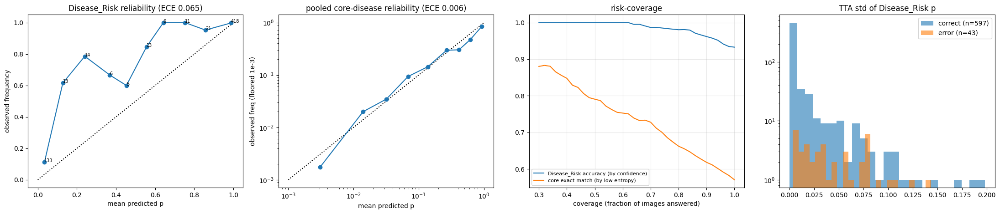


Saved to /kaggle/working/test_results: test_uncertainty.csv, uncertainty_summary.json, fig_uncertainty.png
Cell 11 complete. No thresholds, models or hyperparameters were changed.


In [11]:
# ============================================================
# CELL 11: Confidence / uncertainty analysis on TEST (analysis only; nothing is retuned)
# ============================================================
import os, json, math, gc
import numpy as np, pandas as pd, torch, torch.nn.functional as Fnn
import matplotlib.pyplot as plt
from sklearn.metrics import roc_auc_score, brier_score_loss
from scipy.stats import spearmanr

for n_ in ("build_model", "PRIMARY", "CKPT_DIR", "LABEL_COLS", "DISEASE_COLS", "DIS_IDX", "CORE", "Y", "M", "X", "to_float", "norm", "dev"):
    assert n_ in globals(), f"'{n_}' missing -> re-run Cells 5-7"
TAG, OUT = "convnext_tiny_v1", "/kaggle/working/test_results"
ck = torch.load(f"{CKPT_DIR}/{TAG}_best.pt", map_location="cpu", weights_only=False)
cal = json.load(open("/kaggle/working/calibration_thresholds.json"))
T, t_f1, t_glob, per_cls = cal["temperature"], cal["risk_thr_maxF1"], cal["disease_thr_global"], cal["disease_thr_per_class"]
yt = Y["test"].numpy(); n = len(yt); cam = M["test"]["camera"].values
cj = [LABEL_COLS.index(c) for c in CORE]
thr_vec = np.full(len(LABEL_COLS), 0.5)
for c in DISEASE_COLS: thr_vec[LABEL_COLS.index(c)] = per_cls.get(c, t_glob)

# ---------- 0. TTA logits (4 deterministic views) ----------
VIEWS = [(0., False), (0., True), (10., False), (-10., False)]
def make_view(x, ang, flip):
    if ang == 0 and not flip: return x
    a = math.radians(ang); c, s = math.cos(a), math.sin(a); fx = -1.0 if flip else 1.0
    theta = torch.tensor([[c * fx, -s, 0.0], [s * fx, c, 0.0]], device=x.device).unsqueeze(0).repeat(x.shape[0], 1, 1)
    grid = Fnn.affine_grid(theta, list(x.shape), align_corners=False)
    return Fnn.grid_sample(x, grid, mode="bilinear", padding_mode="zeros", align_corners=False)
model = build_model(PRIMARY, pretrained=False); model.load_state_dict(ck["state_dict"]); model.eval()
outs = []
with torch.no_grad():
    for i in range(0, n, 64):
        j = min(i + 64, n); x = to_float(X["test"][i:j]); per = []
        for ang, fl in VIEWS:
            with torch.autocast("cuda", dtype=torch.float16):
                per.append(model(norm(make_view(x, ang, fl)).contiguous(memory_format=torch.channels_last)).float().cpu())
        outs.append(torch.stack(per))
LV = torch.cat(outs, 1); del model; gc.collect(); torch.cuda.empty_cache()          # [V, N, 46]
saved = np.load(f"{OUT}/test_logits.npy")
print(f"TTA logits {tuple(LV.shape)} | identity view vs saved Cell-10 logits: max abs diff {np.abs(LV[0].numpy() - saved).max():.5f}")
PV = torch.sigmoid(LV / T).numpy(); p1 = PV[0]; ptta = PV.mean(0); sd = PV[:, :, 0].std(0)
p_raw = torch.sigmoid(LV[0]).numpy()

def ece(p, y, bins=10):
    idx = np.clip(np.digitize(p, np.linspace(0, 1, bins + 1)) - 1, 0, bins - 1)
    return float(sum((idx == b).mean() * abs(p[idx == b].mean() - y[idx == b].mean()) for b in range(bins) if (idx == b).any()))

# ---------- 1. calibration on TEST (T fitted on VAL) ----------
print("\n" + "=" * 80); print(f"1. CALIBRATION ON TEST (frozen T={T})"); print("=" * 80)
flat = lambda p: p[:, cj].ravel(); yflat = yt[:, cj].ravel()
for name, p in (("raw   ", p_raw), ("scaled", p1)):
    print(f"{name}: Disease_Risk ECE {ece(p[:, 0], yt[:, 0]):.4f} Brier {brier_score_loss(yt[:, 0], p[:, 0]):.4f} | "
          f"pooled core-disease ECE {ece(flat(p), yflat):.4f} Brier {brier_score_loss(yflat, flat(p)):.4f}")

# ---------- 2. selective prediction for Disease_Risk ----------
print("\n" + "=" * 80); print(f"2. Disease_Risk SELECTIVE PREDICTION (threshold {t_f1:.3f}; confidence = |logit(p) - logit(thr)|)"); print("=" * 80)
lg = lambda p: np.log(np.clip(p, 1e-6, 1 - 1e-6) / (1 - np.clip(p, 1e-6, 1 - 1e-6)))
pr = p1[:, 0] >= t_f1; ytr = yt[:, 0] == 1; err = pr != ytr
close = np.abs(lg(p1[:, 0]) - lg(t_f1)); order = np.argsort(-close)           # most confident first
def sel_row(cov):
    keep = order[:int(round(cov * n))]; y, p_ = ytr[keep], pr[keep]
    tp, fp, fn, tn = int((p_ & y).sum()), int((p_ & ~y).sum()), int((~p_ & y).sum()), int((~p_ & ~y).sum())
    return dict(coverage=cov, n=len(keep), acc=(tp + tn) / len(keep), errors=int(err[keep].sum()), missed_abnormal=fn,
                false_alarms=fp, sens=tp / max(tp + fn, 1), spec=tn / max(tn + fp, 1))
print(pd.DataFrame([sel_row(c) for c in (1.0, 0.9, 0.8, 0.7, 0.6, 0.5)]).round(3).to_string(index=False))
print(f"errors overall: {int(err.sum())}/{n} (missed abnormal {int((~pr & ytr).sum())}, false alarms {int((pr & ~ytr).sum())})")

# ---------- 3. TTA disagreement as an error detector ----------
print("\n" + "=" * 80); print("3. DOES UNCERTAINTY FLAG ERRORS? (Disease_Risk errors at the max-F1 threshold)"); print("=" * 80)
print(f"error-detection AUROC | distance-from-threshold (low = uncertain): {roc_auc_score(err, -close):.3f} | TTA std of p: {roc_auc_score(err, sd):.3f}")
print(f"Spearman(TTA std, closeness to threshold) = {spearmanr(sd, -close)[0]:.3f}  (high = the two signals largely agree)")
print(f"mean TTA std: correct {sd[~err].mean():.4f} vs error {sd[err].mean():.4f}")
pt_ = ptta[:, 0] >= t_f1
print(f"[informational, primary predictions unchanged] TTA-mean Disease_Risk AUROC {roc_auc_score(yt[:, 0], ptta[:, 0]):.4f} vs single-view {roc_auc_score(yt[:, 0], p1[:, 0]):.4f} | "
      f"acc @frozen thr {(pt_ == ytr).mean():.3f} vs {(pr == ytr).mean():.3f}")

# ---------- 4. per camera ----------
print("\n" + "=" * 80); print("4. PER CAMERA: does the model 'know' when it is unsure? (abstain = least-confident 20%)"); print("=" * 80)
abst = np.zeros(n, bool); abst[order[int(round(0.8 * n)):]] = True
for c in sorted(set(cam)):
    m = cam == c
    print(f"{c:<20} n={m.sum():>3} | error rate {err[m].mean():.3f} | abstained {abst[m].mean():.2f} | "
          f"errors caught by abstention {int((abst & err & m).sum())}/{int((err & m).sum())} | mean TTA std {sd[m].mean():.4f} | mean confidence {close[m].mean():.2f}")

# ---------- 5. disease-level uncertainty ----------
print("\n" + "=" * 80); print("5. DISEASE-LEVEL UNCERTAINTY (21 core classes, frozen PRIMARY thresholds)"); print("=" * 80)
PRED = p1 >= thr_vec; pc = np.clip(p1[:, cj], 1e-6, 1 - 1e-6)
Hm = (-(pc * np.log(pc) + (1 - pc) * np.log(1 - pc))).mean(1)                    # mean binary entropy per image
wrong = (PRED[:, cj] != (yt[:, cj] == 1)); nwrong = wrong.sum(1); ok_core = nwrong == 0
print(f"images with ALL 21 core columns correct: {ok_core.mean():.3f} | Spearman(entropy, #wrong columns) = {spearmanr(Hm, nwrong)[0]:.3f} "
      f"| AUROC(entropy -> image has >=1 core error) = {roc_auc_score(~ok_core, Hm):.3f}")
ordH = np.argsort(Hm); rc = []
for cov in (1.0, 0.9, 0.8, 0.7, 0.6, 0.5):
    keep = ordH[:int(round(cov * n))]; rc.append(dict(coverage=cov, n=len(keep), exact_match_core=ok_core[keep].mean(), mean_wrong_cols=nwrong[keep].mean()))
print(pd.DataFrame(rc).round(3).to_string(index=False))
Yc, Pc, Prc = yt[:, cj] == 1, p1[:, cj], PRED[:, cj]
bins = [0, 0.25, 0.5, 0.75, 0.9, 1.01]; pp, hit = Pc[Prc], Yc[Prc]
print("\nPrecision of PREDICTED-POSITIVE (image, core-class) pairs by predicted probability:")
for lo, hi in zip(bins[:-1], bins[1:]):
    m = (pp >= lo) & (pp < hi)
    if m.sum(): print(f"  p in [{lo:.2f}, {min(hi, 1):.2f}): n={int(m.sum()):>4} | precision {hit[m].mean():.3f}")

# ---------- 6. figure + saves ----------
fig, ax = plt.subplots(1, 4, figsize=(22, 4.8))
eb = np.linspace(0, 1, 11); idx = np.clip(np.digitize(p1[:, 0], eb) - 1, 0, 9)
xs = [(p1[idx == b, 0].mean(), ytr[idx == b].mean(), int((idx == b).sum())) for b in range(10) if (idx == b).any()]
ax[0].plot([0, 1], [0, 1], "k:"); ax[0].plot([a for a, _, _ in xs], [b for _, b, _ in xs], "o-")
for a, b, c_ in xs: ax[0].annotate(str(c_), (a, b), fontsize=7)
ax[0].set_title(f"Disease_Risk reliability (ECE {ece(p1[:, 0], yt[:, 0]):.3f})"); ax[0].set_xlabel("mean predicted p"); ax[0].set_ylabel("observed frequency")
ed = np.array([0, .01, .02, .05, .1, .2, .35, .5, .75, 1.0]); pf, yf = flat(p1), yflat.astype(float); ib = np.clip(np.digitize(pf, ed) - 1, 0, len(ed) - 2)
pts = [(pf[ib == b].mean(), max(yf[ib == b].mean(), 1e-3)) for b in range(len(ed) - 1) if (ib == b).sum() > 0]
ax[1].loglog([1e-3, 1], [1e-3, 1], "k:"); ax[1].loglog(*zip(*pts), "o-"); ax[1].set_title(f"pooled core-disease reliability (ECE {ece(pf, yf):.3f})"); ax[1].set_xlabel("mean predicted p"); ax[1].set_ylabel("observed freq (floored 1e-3)")
cg = np.linspace(0.3, 1, 36)
ax[2].plot(cg, [1 - sel_row(c)["errors"] / sel_row(c)["n"] for c in cg], label="Disease_Risk accuracy (by confidence)")
ax[2].plot(cg, [ok_core[ordH[:int(round(c * n))]].mean() for c in cg], label="core exact-match (by low entropy)")
ax[2].set_xlabel("coverage (fraction of images answered)"); ax[2].set_title("risk-coverage"); ax[2].legend(fontsize=8); ax[2].grid(alpha=.3)
ax[3].hist(sd[~err], bins=25, alpha=.6, label=f"correct (n={int((~err).sum())})"); ax[3].hist(sd[err], bins=25, alpha=.6, label=f"error (n={int(err.sum())})")
ax[3].set_yscale("log"); ax[3].set_title("TTA std of Disease_Risk p"); ax[3].legend()
plt.tight_layout(); plt.savefig(f"{OUT}/fig_uncertainty.png", dpi=120); plt.show()

pd.DataFrame(dict(ID=M["test"]["ID"].values, camera=cam, risk_p=p1[:, 0], risk_pred=pr.astype(int), risk_true=ytr.astype(int), risk_error=err.astype(int),
                  confidence=close, tta_std=sd, tta_mean_p=ptta[:, 0], core_entropy=Hm, core_wrong_cols=nwrong)).to_csv(f"{OUT}/test_uncertainty.csv", index=False)
json.dump(dict(T=T, ece_risk_scaled=ece(p1[:, 0], yt[:, 0]), ece_risk_raw=ece(p_raw[:, 0], yt[:, 0]), ece_core_scaled=ece(pf, yf), ece_core_raw=ece(flat(p_raw), yflat),
               err_detect_auroc_confidence=float(roc_auc_score(err, -close)), err_detect_auroc_tta_std=float(roc_auc_score(err, sd)),
               selective_risk=[sel_row(c) for c in (1.0, 0.9, 0.8, 0.7, 0.6, 0.5)], core_exact_match=float(ok_core.mean()),
               core_risk_coverage=rc), open(f"{OUT}/uncertainty_summary.json", "w"), indent=2, default=float)
print(f"\nSaved to {OUT}: test_uncertainty.csv, uncertainty_summary.json, fig_uncertainty.png")
print("Cell 11 complete. No thresholds, models or hyperparameters were changed.")

1. TYPICAL TRUE POSITIVES (median-probability TP per class, primary thresholds)
   DR: n_TP= 92 | test row 8 (ID 9) | TOPCON_3D_OCT2000 | p=0.99 | labels ['DR']
  MYA: n_TP= 25 | test row 97 (ID 98) | TOPCON_3D_OCT2000 | p=0.94 | labels ['MYA']
 BRVO: n_TP= 18 | test row 236 (ID 237) | TOPCON_3D_OCT2000 | p=0.98 | labels ['BRVO']
  ODE: n_TP= 13 | test row 340 (ID 341) | TOPCON_3D_OCT2000 | p=0.98 | labels ['ODE']
 ARMD: n_TP= 21 | test row 47 (ID 48) | TOPCON_3D_OCT2000 | p=0.94 | labels ['ARMD', 'MYA']
  ODC: n_TP= 47 | test row 17 (ID 18) | TOPCON_3D_OCT2000 | p=0.83 | labels ['TSLN', 'ODC']


Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [0.0039215684..1.0000002].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [0.0039215684..1.0000002].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [0.0..1.0000002].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [0.0..1.0000002].


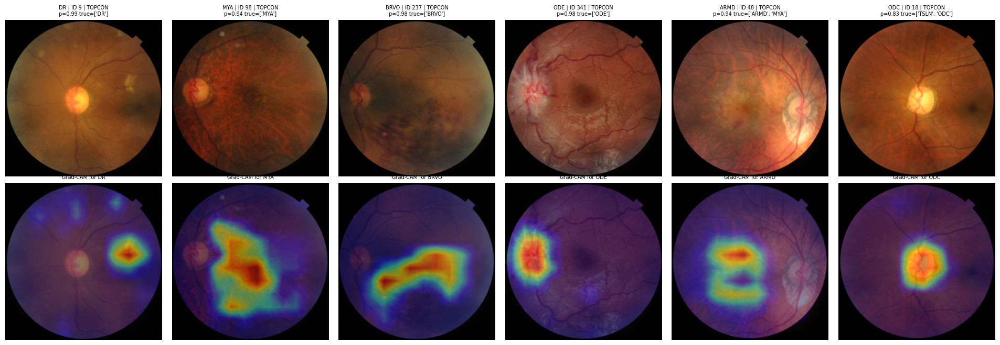


2. MOST CONFIDENT FALSE POSITIVES (core classes, primary thresholds)
  predicted    MH p=0.99 | row 380 (ID 381) | TOPCON_3D_OCT2000 | true labels ['DN']
  predicted    MH p=0.99 | row 28 (ID 29) | TOPCON_3D_OCT2000 | true labels ['CRS']
  predicted  ARMD p=0.99 | row 6 (ID 7) | TOPCON_3D_OCT2000 | true labels ['MS']
  predicted    MH p=0.98 | row 149 (ID 150) | TOPCON_3D_OCT2000 | true labels ['RT']
  predicted   ODE p=0.98 | row 3 (ID 4) | TOPCON_3D_OCT2000 | true labels ['AION']
  predicted    MH p=0.97 | row 607 (ID 608) | Kowa_VX10a | true labels ['LS', 'ODP', 'PRH']


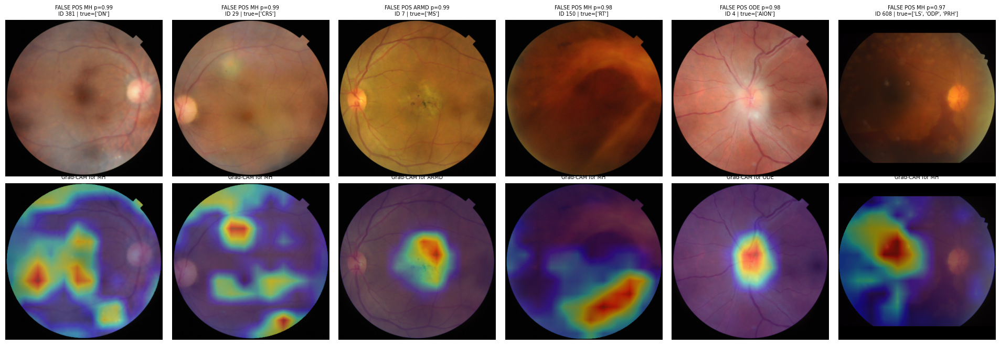


3. SANITY CHECK: Pearson correlation between trained-model CAM and random-init-model CAM (same image, same class)
typical cases: [-0.19, -0.31, 0.21, 0.43, -0.36, 0.69] | mean 0.08
false positives: [-0.29, -0.13, -0.23, -0.34, 0.39, -0.49] | mean -0.18
(Low correlation = the heatmaps depend on the learned weights. A high value would mean they mostly reflect image structure.)

4. BORDER RELIANCE of the Disease_Risk CAM (ratio = CAM mass share on outer rim / rim area share; 1.0 = uniform)
all images: trained mean 1.02 (median 0.99) | random-init control 0.77
                              n  trained_mean  trained_median  trained_p90  random_mean
camera            abnormal                                                             
Kowa_VX10a        0          50          1.13            1.11         1.42         0.57
                  1          78          0.75            0.71         1.30         0.61
TOPCON_3D_OCT2000 0          32          1.59            1.63         1.98         0

In [12]:
# ============================================================
# CELL 12: Grad-CAM (test images; analysis only, nothing is retuned)
# ============================================================
import os, json, gc
import numpy as np, pandas as pd, torch, torch.nn.functional as Fnn
import matplotlib.pyplot as plt

for n_ in ("build_model", "PRIMARY", "CKPT_DIR", "LABEL_COLS", "DISEASE_COLS", "CORE", "Y", "M", "X", "to_float", "norm", "dev", "BG"):
    assert n_ in globals(), f"'{n_}' missing -> re-run Cells 5-7"
TAG, OUT = "convnext_tiny_v1", "/kaggle/working/test_results"
ck = torch.load(f"{CKPT_DIR}/{TAG}_best.pt", map_location="cpu", weights_only=False)
cal = json.load(open("/kaggle/working/calibration_thresholds.json"))
thr_vec = np.full(len(LABEL_COLS), 0.5)
for c in DISEASE_COLS: thr_vec[LABEL_COLS.index(c)] = cal["disease_thr_per_class"].get(c, cal["disease_thr_global"])
yt = Y["test"].numpy(); n = len(yt); cam_name = M["test"]["camera"].values; ids = M["test"]["ID"].values
p1 = np.load(f"{OUT}/test_probs_calibrated.npy"); assert p1.shape == (n, 46)
lab_of = lambda i: [c for c in DISEASE_COLS if yt[i, LABEL_COLS.index(c)] == 1] or ["NORMAL"]

model = build_model(PRIMARY, pretrained=False); model.load_state_dict(ck["state_dict"]); model.eval()
torch.manual_seed(123); rand_model = build_model(PRIMARY, pretrained=False); rand_model.eval()   # randomly initialised control
assert hasattr(model, "stages")

class GradCAM:
    def __init__(self, m):
        self.m, self.act, self.grad = m, None, None
        m.stages[-1].register_forward_hook(self._fwd)                       # last stage output [B,768,12,12]
    def _fwd(self, mod, inp, out):
        self.act = out; out.register_hook(lambda g: setattr(self, "grad", g))
    def __call__(self, x, j):
        self.m.zero_grad(set_to_none=True)
        with torch.enable_grad():
            out = self.m(x.contiguous()); out[:, j].sum().backward()          # LayerNorm model: no cross-sample interaction
        w = self.grad.mean((2, 3), keepdim=True)
        cam = torch.relu((w * self.act).sum(1, keepdim=True)).detach()
        cam = Fnn.interpolate(cam, size=x.shape[-2:], mode="bilinear", align_corners=False)[:, 0]
        self.act = self.grad = None
        return cam
G_tr, G_rn = GradCAM(model), GradCAM(rand_model)

def run_cam(G, idxs, j, bs=8, want_border=False):
    cams, masks, ratios = [], [], []
    for s in range(0, len(idxs), bs):
        ii = torch.as_tensor(idxs[s:s + bs]); x01 = to_float(X["test"][ii])
        cam = G(norm(x01), j); mask = (x01.amax(1) > BG).float(); cam = cam * mask
        if want_border:
            er = 1 - Fnn.max_pool2d(1 - mask.unsqueeze(1), 65, 1, 32); ring = (mask.unsqueeze(1) - er).clamp_min(0)[:, 0]
            frac = (cam * ring).flatten(1).sum(1) / cam.flatten(1).sum(1).clamp_min(1e-8)
            area = ring.flatten(1).sum(1) / mask.flatten(1).sum(1).clamp_min(1)
            ratios.append((frac / area.clamp_min(1e-8)).cpu())
        else:
            cams.append((cam / cam.flatten(1).amax(1).clamp_min(1e-8).view(-1, 1, 1)).cpu()); masks.append(mask.cpu())
    return (torch.cat(ratios).numpy() if want_border else (torch.cat(cams).numpy(), torch.cat(masks).numpy()))
def corr(a, b, m):
    a, b = a[m > 0], b[m > 0]
    return float(np.corrcoef(a, b)[0, 1]) if a.std() > 0 and b.std() > 0 else float("nan")
def img_of(i): return to_float(X["test"][[i]])[0].permute(1, 2, 0).cpu().numpy()
def overlay(ax, img, cam, mask, title):
    ax.imshow(img); ax.imshow(np.ma.masked_where(mask == 0, cam), cmap="jet", alpha=0.45, vmin=0, vmax=1); ax.axis("off"); ax.set_title(title, fontsize=7)

# ---------- 1. typical true positives (closest to the MEDIAN probability among TPs) ----------
print("=" * 80); print("1. TYPICAL TRUE POSITIVES (median-probability TP per class, primary thresholds)"); print("=" * 80)
CLS = ["DR", "MYA", "BRVO", "ODE", "ARMD", "ODC"]; typ = []
for c in CLS:
    j = LABEL_COLS.index(c); tp = np.where((yt[:, j] == 1) & (p1[:, j] >= thr_vec[j]))[0]
    if len(tp) == 0: print(f"{c}: no true positives at the frozen threshold"); continue
    i = int(tp[np.argsort(np.abs(p1[tp, j] - np.median(p1[tp, j])))[0]]); typ.append((c, j, i))
    print(f"{c:>5}: n_TP={len(tp):>3} | test row {i} (ID {int(ids[i])}) | {cam_name[i]} | p={p1[i, j]:.2f} | labels {lab_of(i)}")
fig, ax = plt.subplots(2, len(typ), figsize=(3.2 * len(typ), 6.6), squeeze=False); rc_typ = []
for k, (c, j, i) in enumerate(typ):
    cam, mk = run_cam(G_tr, [i], j); crn, _ = run_cam(G_rn, [i], j); rc_typ.append(corr(cam[0], crn[0], mk[0]))
    ax[0, k].imshow(img_of(i)); ax[0, k].axis("off"); ax[0, k].set_title(f"{c} | ID {int(ids[i])} | {cam_name[i][:6]}\np={p1[i, j]:.2f} true={lab_of(i)}", fontsize=7)
    overlay(ax[1, k], img_of(i), cam[0], mk[0], f"Grad-CAM for {c}")
plt.tight_layout(); plt.savefig(f"{OUT}/fig_gradcam_typical.png", dpi=120); plt.show()

# ---------- 2. most confident false positives (distinct images) ----------
print("\n" + "=" * 80); print("2. MOST CONFIDENT FALSE POSITIVES (core classes, primary thresholds)"); print("=" * 80)
cj = [LABEL_COLS.index(c) for c in CORE]
cand = sorted([(float(p1[i, j]), i, j) for i in range(n) for j in cj if yt[i, j] == 0 and p1[i, j] >= thr_vec[j]], reverse=True)
fps, used = [], set()
for p_, i, j in cand:
    if i in used: continue
    used.add(i); fps.append((LABEL_COLS[j], j, i, p_))
    if len(fps) == 6: break
for c, j, i, p_ in fps: print(f"  predicted {c:>5} p={p_:.2f} | row {i} (ID {int(ids[i])}) | {cam_name[i]} | true labels {lab_of(i)}")
fig, ax = plt.subplots(2, len(fps), figsize=(3.2 * len(fps), 6.6), squeeze=False); rc_fp = []
for k, (c, j, i, p_) in enumerate(fps):
    cam, mk = run_cam(G_tr, [i], j); crn, _ = run_cam(G_rn, [i], j); rc_fp.append(corr(cam[0], crn[0], mk[0]))
    ax[0, k].imshow(img_of(i)); ax[0, k].axis("off"); ax[0, k].set_title(f"FALSE POS {c} p={p_:.2f}\nID {int(ids[i])} | true={lab_of(i)}", fontsize=7)
    overlay(ax[1, k], img_of(i), cam[0], mk[0], f"Grad-CAM for {c}")
plt.tight_layout(); plt.savefig(f"{OUT}/fig_gradcam_failures.png", dpi=120); plt.show()

# ---------- 3. randomisation sanity check ----------
print("\n" + "=" * 80); print("3. SANITY CHECK: Pearson correlation between trained-model CAM and random-init-model CAM (same image, same class)"); print("=" * 80)
print(f"typical cases: {np.round(rc_typ, 2).tolist()} | mean {np.nanmean(rc_typ):.2f}")
print(f"false positives: {np.round(rc_fp, 2).tolist()} | mean {np.nanmean(rc_fp):.2f}")
print("(Low correlation = the heatmaps depend on the learned weights. A high value would mean they mostly reflect image structure.)")

# ---------- 4. border / artifact reliance, all 640 test images, target = Disease_Risk logit ----------
print("\n" + "=" * 80); print("4. BORDER RELIANCE of the Disease_Risk CAM (ratio = CAM mass share on outer rim / rim area share; 1.0 = uniform)"); print("=" * 80)
allidx = list(range(n)); r_tr = run_cam(G_tr, allidx, 0, want_border=True); r_rn = run_cam(G_rn, allidx, 0, want_border=True)
df = pd.DataFrame(dict(camera=cam_name, abnormal=yt[:, 0].astype(int), ratio_trained=r_tr, ratio_random=r_rn))
print(f"all images: trained mean {np.nanmean(r_tr):.2f} (median {np.nanmedian(r_tr):.2f}) | random-init control {np.nanmean(r_rn):.2f}")
print(df.groupby(["camera", "abnormal"]).agg(n=("ratio_trained", "size"), trained_mean=("ratio_trained", "mean"), trained_median=("ratio_trained", "median"),
                                             trained_p90=("ratio_trained", lambda s: s.quantile(.9)), random_mean=("ratio_random", "mean")).round(2).to_string())
hi = df.ratio_trained > 2.0
print(f"\nimages with ratio > 2.0 (strong rim focus): {int(hi.sum())}/{n}  by camera: {df[hi].camera.value_counts().to_dict()}")
df.assign(ID=ids).to_csv(f"{OUT}/gradcam_border_ratio.csv", index=False)

json.dump(dict(layer="stages[-1] (12x12 at 384px)", target="raw logit", typical=[dict(cls=c, row=int(i), ID=int(ids[i])) for c, j, i in typ],
               false_pos=[dict(cls=c, row=int(i), ID=int(ids[i]), p=p_) for c, j, i, p_ in fps],
               random_corr_typical=rc_typ, random_corr_fp=rc_fp, border_ratio_trained_mean=float(np.nanmean(r_tr)), border_ratio_random_mean=float(np.nanmean(r_rn))),
          open(f"{OUT}/gradcam_summary.json", "w"), indent=2, default=float)
del model, rand_model, G_tr, G_rn; gc.collect(); torch.cuda.empty_cache()
print(f"\nSaved to {OUT}: fig_gradcam_typical.png, fig_gradcam_failures.png, gradcam_border_ratio.csv, gradcam_summary.json")
print("Cell 12 complete. No thresholds, models or hyperparameters were changed.")

1. Disease_Risk MISSES (abnormal images below threshold): maxF1 thr 0.475 | sens95 thr 0.108
                   n_abnormal  missed_maxF1  missed_sens95  sens_maxF1  sens_sens95
camera                                                                             
Kowa_VX10a                 78            10              4       0.872        0.949
TOPCON_3D_OCT2000         407            17              6       0.958        0.985
TOPCON_TRC_NW300           21            12              7       0.429        0.667

                       n_abnormal  missed_maxF1  missed_sens95  sens_maxF1  sens_sens95
group                                                                                  
has >=1 core disease          490            37             16       0.924        0.967
non-core (rarer) only          16             2              1       0.875        0.938

           n_abnormal  missed_maxF1  missed_sens95  sens_maxF1  sens_sens95
n_dis_bin                                                

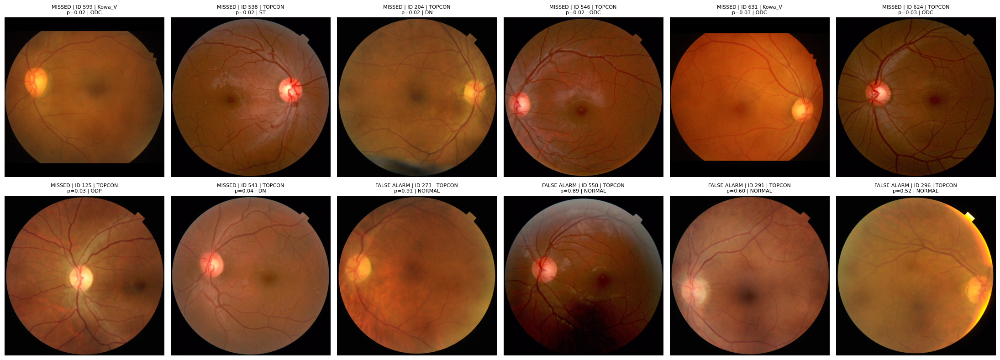


Saved to /kaggle/working/test_results: error_risk_cases.csv, error_core_taxonomy.csv, error_confusion_pairs.csv, fig_error_gallery.png, error_analysis_summary.json
Cell 13 complete. No thresholds, models or hyperparameters were changed.


In [13]:
# ============================================================
# CELL 13: Error analysis on TEST (analysis only; nothing is retuned)
# ============================================================
import os, json
import numpy as np, pandas as pd, torch, torch.nn.functional as Fnn
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", 100); pd.set_option("display.width", 250); pd.set_option("display.max_rows", 200)
for n_ in ("LABEL_COLS", "DISEASE_COLS", "DIS_IDX", "CORE", "Y", "M", "X", "dev"):
    assert n_ in globals(), f"'{n_}' missing -> re-run Cells 5-7"
OUT = "/kaggle/working/test_results"
cal = json.load(open("/kaggle/working/calibration_thresholds.json"))
t_f1, t_s95 = cal["risk_thr_maxF1"], cal["risk_thr_sens95"]
thr_vec = np.full(len(LABEL_COLS), 0.5)
for c in DISEASE_COLS: thr_vec[LABEL_COLS.index(c)] = cal["disease_thr_per_class"].get(c, cal["disease_thr_global"])
p1 = np.load(f"{OUT}/test_probs_calibrated.npy"); yt = Y["test"].numpy(); n = len(yt); assert p1.shape == (n, 46)
cam = M["test"]["camera"].values; ids = M["test"]["ID"].values
CJ = [LABEL_COLS.index(c) for c in CORE]; CORE_SET = set(CORE)
tr_pos = {c: int(Y["train"].numpy()[:, LABEL_COLS.index(c)].sum()) for c in DISEASE_COLS}
labs = [[c for c in DISEASE_COLS if yt[i, LABEL_COLS.index(c)] == 1] for i in range(n)]
lab_s = lambda i: ",".join(labs[i]) if labs[i] else "NORMAL"
PRED = p1 >= thr_vec; risk = p1[:, 0]; yr = yt[:, 0] == 1
TRC = "TOPCON_TRC_NW300"

# ---------- 1. Disease_Risk errors ----------
print("=" * 80); print(f"1. Disease_Risk MISSES (abnormal images below threshold): maxF1 thr {t_f1:.3f} | sens95 thr {t_s95:.3f}"); print("=" * 80)
ab = np.where(yr)[0]
D = pd.DataFrame(dict(idx=ab, ID=ids[ab], camera=cam[ab], n_dis=[len(labs[i]) for i in ab], p=risk[ab], labels=[lab_s(i) for i in ab],
                      group=["has >=1 core disease" if any(c in CORE_SET for c in labs[i]) else "non-core (rarer) only" for i in ab]))
D["n_dis_bin"] = D.n_dis.clip(upper=3); D["miss_maxF1"] = D.p < t_f1; D["miss_s95"] = D.p < t_s95
for key in ("camera", "group", "n_dis_bin"):
    g = D.groupby(key).agg(n_abnormal=("p", "size"), missed_maxF1=("miss_maxF1", "sum"), missed_sens95=("miss_s95", "sum"))
    g["sens_maxF1"] = 1 - g.missed_maxF1 / g.n_abnormal; g["sens_sens95"] = 1 - g.missed_sens95 / g.n_abnormal
    print(g.round(3).to_string()); print()
S = D[D.n_dis == 1].copy()
g = S.groupby("labels").agg(n=("p", "size"), median_p=("p", "median"), sens_maxF1=("miss_maxF1", lambda s: 1 - s.mean()), sens_sens95=("miss_s95", lambda s: 1 - s.mean()))
g["train_pos"] = [tr_pos[c] for c in g.index]
print("Single-label abnormal images: risk-head sensitivity by disease (classes with >=3 such test images):")
print(g[g.n >= 3].sort_values("sens_maxF1").round(3).to_string()); print()
M1 = D[D.miss_maxF1].sort_values("p")
print(f"{len(M1)} missed abnormals at maxF1 thr. Lowest-p (most confident) 15:")
print(M1[["ID", "camera", "p", "labels"]].head(15).round(3).to_string(index=False))
FA = np.where(~yr & (risk >= t_f1))[0]; FA = FA[np.argsort(-risk[FA])]
print(f"\nFalse alarms at maxF1 thr ({len(FA)}), and {int((~yr & (risk >= t_s95)).sum())} at the sens95 thr:")
print(pd.DataFrame(dict(ID=ids[FA], camera=cam[FA], p=risk[FA])).round(3).to_string(index=False))
pd.concat([M1.assign(kind="missed_abnormal")[["kind", "ID", "camera", "p", "labels"]],
           pd.DataFrame(dict(kind="false_alarm", ID=ids[FA], camera=cam[FA], p=risk[FA], labels="NORMAL"))]).to_csv(f"{OUT}/error_risk_cases.csv", index=False)

# ---------- 2. disease-level error taxonomy (core classes, PRIMARY thresholds) ----------
print("\n" + "=" * 80); print("2. CORE-CLASS ERROR TAXONOMY"); print("=" * 80)
rows = []
for c in CORE:
    j = LABEL_COLS.index(c); oth = [k for k in CJ if k != j]
    fp = np.where(PRED[:, j] & (yt[:, j] == 0))[0]; fn = np.where(~PRED[:, j] & (yt[:, j] == 1))[0]
    cats = ["normal" if yt[i, 0] == 0 else ("other_core" if yt[i, oth].any() else "noncore_only") for i in fp]
    vc = pd.Series(cats, dtype=object).value_counts()
    rows.append(dict(cls=c, test_pos=int(yt[:, j].sum()), FN=len(fn), FN_but_other_core_flagged=int(sum(PRED[i, oth].any() for i in fn)),
                     FP=len(fp), FP_on_normal=int(vc.get("normal", 0)), FP_on_other_core=int(vc.get("other_core", 0)), FP_on_noncore_only=int(vc.get("noncore_only", 0))))
E = pd.DataFrame(rows); E.to_csv(f"{OUT}/error_core_taxonomy.csv", index=False); print(E.to_string(index=False))
pairs = []
for a in CORE:
    ia = np.where(yt[:, LABEL_COLS.index(a)] == 1)[0]
    for b in CORE:
        if a == b: continue
        jb = LABEL_COLS.index(b); k = int((PRED[ia, jb] & (yt[ia, jb] == 0)).sum())
        if k: pairs.append(dict(true=a, wrongly_flagged=b, n_true=len(ia), count=k, rate=k / len(ia), base_rate_of_b_on_images_without_b=PRED[yt[:, jb] == 0, jb].mean()))
CP = pd.DataFrame(pairs).sort_values("count", ascending=False); CP.to_csv(f"{OUT}/error_confusion_pairs.csv", index=False)
print("\nTop 15 (true class -> wrongly flagged class); 'rate' well above the base rate = systematic confusion:")
print(CP.head(15).round(3).to_string(index=False))

# ---------- 3. image quality vs errors ----------
print("\n" + "=" * 80); print("3. IMAGE QUALITY PROXIES vs ERRORS (tertiles ranked WITHIN camera)"); print("=" * 80)
kern = torch.tensor([[0, 1, 0], [1, -4, 1], [0, 1, 0]], dtype=torch.float32, device=dev).view(1, 1, 3, 3); sh = []
for i in range(0, n, 64):
    g_ = Fnn.avg_pool2d(X["test"][i:i + 64][..., 1].to(dev).float().unsqueeze(1), 2)
    m_ = (g_ > 15).float(); me = 1 - Fnn.max_pool2d(1 - m_, 9, 1, 4)
    sh.append((((Fnn.conv2d(g_, kern, padding=1)) ** 2 * me).sum((1, 2, 3)) / me.sum((1, 2, 3)).clamp_min(1)).cpu())
Q = pd.DataFrame(dict(camera=cam, sharpness=torch.cat(sh).numpy(), brightness=M["test"]["mean_g"].values,
                      risk_error=(risk >= t_f1) != yr, core_wrong_cols=(PRED[:, CJ] != (yt[:, CJ] == 1)).sum(1), MH_true=yt[:, LABEL_COLS.index("MH")]))
for col in ("sharpness", "brightness"):
    pct = Q.groupby("camera")[col].rank(pct=True)
    Q[col + "_bin"] = pd.cut(pct, [0, 1 / 3, 2 / 3, 1.0], labels=["low", "mid", "high"], include_lowest=True)
    print(f"\nby {col} tertile:")
    print(Q.groupby(col + "_bin", observed=True).agg(n=("risk_error", "size"), risk_error_rate=("risk_error", "mean"),
                                                     mean_core_wrong_cols=("core_wrong_cols", "mean"), MH_share=("MH_true", "mean")).round(3).to_string())
print("(MH is a quality/haze LABEL, so low sharpness and MH overlap by construction.)")

# ---------- 4. TRC-NW300 investigation ----------
print("\n" + "=" * 80); print(f"4. {TRC} INVESTIGATION"); print("=" * 80)
mt = M["train"]
print("TRAIN abnormal rate by camera:"); print(mt.groupby("camera").Disease_Risk.agg(n="size", abnormal_rate="mean").round(3).to_string())
ab_tr = mt[mt.Disease_Risk == 1]
comp = pd.DataFrame({"TRC train abnormal (n=%d)" % int((ab_tr.camera == TRC).sum()): ab_tr[ab_tr.camera == TRC][DISEASE_COLS].sum() / max((ab_tr.camera == TRC).sum(), 1),
                     "other cameras train abnormal (n=%d)" % int((ab_tr.camera != TRC).sum()): ab_tr[ab_tr.camera != TRC][DISEASE_COLS].sum() / max((ab_tr.camera != TRC).sum(), 1)})
print("\nShare of abnormal TRAIN images carrying each disease (top 10 by TRC share):"); print(comp.sort_values(comp.columns[0], ascending=False).head(10).round(3).to_string())
lg = lambda p: np.log(np.clip(p, 1e-6, 1 - 1e-6) / (1 - np.clip(p, 1e-6, 1 - 1e-6)))
rows = []
for c in sorted(set(cam)):
    for lab in (0, 1):
        m = (cam == c) & (yt[:, 0] == lab)
        rows.append(dict(camera=c, label="abnormal" if lab else "normal", n=int(m.sum()), median_p=np.median(risk[m]), mean_logit=lg(risk[m]).mean(), share_above_maxF1_thr=(risk[m] >= t_f1).mean()))
print("\nTEST Disease_Risk score by camera x true label:"); print(pd.DataFrame(rows).round(3).to_string(index=False))
print("\nTEST abnormal-image group by camera:"); print(pd.crosstab(D.camera, D.group).to_string())
t_ab = np.where((cam == TRC) & yr)[0]
print(f"\nAll {len(t_ab)} TEST abnormal images on {TRC} (sorted by p):")
print(pd.DataFrame(dict(ID=ids[t_ab], p=risk[t_ab], detected_maxF1=risk[t_ab] >= t_f1, labels=[lab_s(i) for i in t_ab])).sort_values("p").round(3).to_string(index=False))

# ---------- 5. discoverability of rare labels ----------
print("\n" + "=" * 80); print("5. RANK OF THE TRUE LABEL among the 45 disease scores, by training frequency of that label"); print("=" * 80)
rk = (-p1[:, DIS_IDX]).argsort(1).argsort(1) + 1
R = pd.DataFrame([dict(cls=c, train_pos=tr_pos[c], rank=int(rk[i, DISEASE_COLS.index(c)]), flagged=bool(PRED[i, LABEL_COLS.index(c)])) for i in range(n) for c in labs[i]])
R["tier"] = pd.cut(R.train_pos, [-1, 4, 19, 10 ** 6], labels=["0-4 train pos", "5-19 train pos", "20+ train pos"])
print(R.groupby("tier", observed=True).agg(n_true_labels=("rank", "size"), n_classes=("cls", "nunique"), top1=("rank", lambda s: (s == 1).mean()),
                                            top3=("rank", lambda s: (s <= 3).mean()), flagged_at_frozen_thr=("flagged", "mean")).round(3).to_string())
print("(Images with several true labels cannot all be top-1. Thresholds for non-core classes are the global one.)")

# ---------- 6. gallery ----------
show = [(i, "MISSED") for i in M1.idx.head(8)] + [(i, "FALSE ALARM") for i in FA[:4]]
fig, ax = plt.subplots(2, 6, figsize=(22, 8.2))
for a, (i, tg) in zip(ax.flatten(), show):
    a.imshow(X["test"][int(i)].numpy()); a.axis("off"); a.set_title(f"{tg} | ID {int(ids[i])} | {cam[i][:6]}\np={risk[i]:.2f} | {lab_s(i)}", fontsize=8)
for a in ax.flatten()[len(show):]: a.axis("off")
plt.tight_layout(); plt.savefig(f"{OUT}/fig_error_gallery.png", dpi=110); plt.show()
json.dump(dict(risk_missed_maxF1=int(len(M1)), risk_false_alarms_maxF1=int(len(FA)),
               rare_tier_top3=R.groupby("tier", observed=True)["rank"].apply(lambda s: float((s <= 3).mean())).to_dict()),
          open(f"{OUT}/error_analysis_summary.json", "w"), indent=2, default=float)
print(f"\nSaved to {OUT}: error_risk_cases.csv, error_core_taxonomy.csv, error_confusion_pairs.csv, fig_error_gallery.png, error_analysis_summary.json")
print("Cell 13 complete. No thresholds, models or hyperparameters were changed.")

In [14]:
# ============================================================
# CELL 14: Export deployable package + standalone inference test (no retuning)
# ============================================================
import os, json, gc, hashlib, importlib.util, time, shutil
import numpy as np, pandas as pd, torch, timm, torchvision

for n_ in ("predict", "build_model", "PRIMARY", "CKPT_DIR", "LABEL_COLS", "DISEASE_COLS", "CORE", "Y", "X", "M", "IMG", "IMAGENET_MEAN", "IMAGENET_STD"):
    assert n_ in globals(), f"'{n_}' missing -> re-run Cells 5-7"
TAG = "convnext_tiny_v1"
EXP = f"/kaggle/working/export/fundus_{TAG}"; os.makedirs(EXP, exist_ok=True)
OUT = "/kaggle/working/test_results"

ck = torch.load(f"{CKPT_DIR}/{TAG}_best.pt", map_location="cpu", weights_only=False)
cal = json.load(open("/kaggle/working/calibration_thresholds.json"))
cc = json.load(open("/kaggle/working/cache_config.json"))          # S is re-read here on purpose (notebook variable S was reused)
assert cal["epoch"] == ck["epoch"] and cal["core_classes"] == CORE
TEMP, t_f1 = cal["temperature"], cal["risk_thr_maxF1"]
lg = lambda p: np.log(np.clip(p, 1e-6, 1 - 1e-6) / (1 - np.clip(p, 1e-6, 1 - 1e-6)))

# ---------- 1. review-confidence cutoff from VAL only ----------
print("=" * 80); print("1. REVIEW CUTOFF (VAL-derived rule: flag the least-confident 20% of Disease_Risk decisions)"); print("=" * 80)
model = build_model(PRIMARY, pretrained=False); model.load_state_dict(ck["state_dict"])
lv = predict(model, "val"); del model; gc.collect(); torch.cuda.empty_cache()
pv = torch.sigmoid(lv / TEMP).numpy()[:, 0]; yv = Y["val"].numpy()[:, 0] == 1
conf_v = np.abs(lg(pv) - lg(t_f1)); REVIEW = float(np.percentile(conf_v, 20)); err_v = (pv >= t_f1) != yv; rv = conf_v < REVIEW
print(f"cutoff (|logit(p)-logit(thr)|) = {REVIEW:.3f}")
print(f"VAL : flagged {rv.mean():.1%} | error rate retained {err_v[~rv].mean():.3f} vs flagged {err_v[rv].mean():.3f} | errors caught {int((err_v & rv).sum())}/{int(err_v.sum())}")
pt_ = np.load(f"{OUT}/test_probs_calibrated.npy"); yt_ = Y["test"].numpy()[:, 0] == 1
conf_t = np.abs(lg(pt_[:, 0]) - lg(t_f1)); err_t = (pt_[:, 0] >= t_f1) != yt_; rt = conf_t < REVIEW
print(f"TEST (rule fixed from val, applied once): flagged {rt.mean():.1%} | error rate retained {err_t[~rt].mean():.3f} vs flagged {err_t[rt].mean():.3f} | errors caught {int((err_t & rt).sum())}/{int(err_t.sum())}")

# ---------- 2. write export files ----------
torch.save({k: v.detach().cpu() for k, v in ck["state_dict"].items()}, f"{EXP}/model_weights.pt")
cfg_inf = dict(model_name=PRIMARY, img=int(IMG), cache_size=int(cc["S"]), bg_thr=int(cc["BG_THR"]), reduce=int(cc["REDUCE"]),
               mean=list(IMAGENET_MEAN), std=list(IMAGENET_STD), label_cols=LABEL_COLS, disease_cols=DISEASE_COLS, core_classes=CORE,
               temperature=TEMP, risk_thr_maxF1=t_f1, risk_thr_sens95=cal["risk_thr_sens95"], disease_thr_global=cal["disease_thr_global"],
               disease_thr_per_class=cal["disease_thr_per_class"], review_confidence_cutoff=REVIEW, embedding_dim=768,
               checkpoint_epoch=int(ck["epoch"]),
               notes="Thresholds/temperature/review cutoff fitted on VAL only. Flags are given only for core classes (>=5 val positives); other classes: probabilities only, not validated.")
json.dump(cfg_inf, open(f"{EXP}/inference_config.json", "w"), indent=2)
for f in ("label_map.json", "pipeline_config.json"): shutil.copy(f"/kaggle/working/{f}", f"{EXP}/{f}")
shutil.copy("/kaggle/working/calibration_thresholds.json", f"{EXP}/calibration_thresholds.json")

MODULE = r'''"""Fundus-image component (ConvNeXt-Tiny fine-tuned on RFMiD). Read MODEL_CARD.md for limits.
Usage:
    from fundus_inference import FundusScreener
    s = FundusScreener("/path/to/export_dir")
    out = s.predict(["a.png", "b.jpg"], return_embedding=True)
"""
import json, os
import numpy as np
import torch
import torch.nn.functional as F
import timm
from PIL import Image


def _logit(p, eps=1e-6):
    p = float(np.clip(p, eps, 1 - eps))
    return float(np.log(p / (1 - p)))


class FundusScreener:
    def __init__(self, export_dir, device=None):
        with open(os.path.join(export_dir, "inference_config.json")) as f:
            self.cfg = json.load(f)
        c = self.cfg
        self.device = torch.device(device or ("cuda" if torch.cuda.is_available() else "cpu"))
        self.model = timm.create_model(c["model_name"], pretrained=False, num_classes=len(c["label_cols"]))
        sd = torch.load(os.path.join(export_dir, "model_weights.pt"), map_location="cpu", weights_only=True)
        self.model.load_state_dict(sd)
        self.model = self.model.to(self.device).eval().to(memory_format=torch.channels_last)
        self.mean = torch.tensor(c["mean"], device=self.device).view(1, 3, 1, 1)
        self.std = torch.tensor(c["std"], device=self.device).view(1, 3, 1, 1)
        self.idx = {n: i for i, n in enumerate(c["label_cols"])}

    def preprocess(self, image):
        """path or PIL image -> (uint8 [S,S,3] array, crop_ok). Same crop/pad/resize as training cache."""
        c = self.cfg
        S, thr, red = c["cache_size"], c["bg_thr"], c["reduce"]
        im = Image.open(image) if isinstance(image, (str, os.PathLike)) else image
        im = im.convert("RGB")
        w, h = im.size
        small = np.asarray(im.reduce(red))
        m = small.max(axis=2) > thr
        cols = np.where(m.sum(axis=0) >= 3)[0]
        rows = np.where(m.sum(axis=1) >= 3)[0]
        if len(cols) == 0 or len(rows) == 0:
            x0, y0, x1, y1, ok = 0, 0, w, h, False
        else:
            x0 = max(0, (cols[0] - 1) * red); x1 = min(w, (cols[-1] + 2) * red)
            y0 = max(0, (rows[0] - 1) * red); y1 = min(h, (rows[-1] + 2) * red)
            ok = True
        crop = im.crop((x0, y0, x1, y1))
        cw, ch = crop.size
        sc = S / max(cw, ch)
        nw, nh = max(1, round(cw * sc)), max(1, round(ch * sc))
        crop = crop.resize((nw, nh), Image.LANCZOS, reducing_gap=3.0)
        canvas = Image.new("RGB", (S, S), (0, 0, 0))
        canvas.paste(crop, ((S - nw) // 2, (S - nh) // 2))
        return np.asarray(canvas), ok

    def _to_tensor(self, arrs):
        x = torch.from_numpy(np.stack(arrs)).to(self.device).permute(0, 3, 1, 2).contiguous().float().div_(255.0)
        s = self.cfg["img"]
        if x.shape[-1] != s:
            x = F.interpolate(x, size=(s, s), mode="bilinear", antialias=True, align_corners=False)
        return ((x - self.mean) / self.std).contiguous(memory_format=torch.channels_last)

    @torch.no_grad()
    def _forward(self, x):
        with torch.autocast(self.device.type, dtype=torch.float16, enabled=self.device.type == "cuda"):
            feats = self.model.forward_features(x)
            emb = self.model.forward_head(feats, pre_logits=True)
            logits = self.model.get_classifier()(emb)
        return logits.float().cpu(), emb.float().cpu()

    def _format(self, p, crop_ok, emb):
        c = self.cfg
        risk = float(p[0])
        conf = abs(_logit(risk) - _logit(c["risk_thr_maxF1"]))
        dp = {n: float(p[self.idx[n]]) for n in c["disease_cols"]}
        thr = lambda n: c["disease_thr_per_class"].get(n, c["disease_thr_global"])
        warn = [] if crop_ok else ["no fundus region found by the border-crop step; result unreliable"]
        out = dict(risk_prob=risk,
                   risk_abnormal_maxF1=risk >= c["risk_thr_maxF1"],
                   risk_abnormal_screening=risk >= c["risk_thr_sens95"],
                   risk_confidence=conf,
                   needs_review=bool(conf < c["review_confidence_cutoff"] or not crop_ok),
                   flagged_diseases=[n for n in c["core_classes"] if dp[n] >= thr(n)],
                   disease_probs=dp, crop_ok=crop_ok, warnings=warn)
        if emb is not None:
            out["embedding"] = emb.astype(np.float32)
        return out

    def predict(self, images, batch_size=16, return_embedding=False):
        results = []
        for i in range(0, len(images), batch_size):
            chunk = images[i:i + batch_size]
            pre = [self.preprocess(im) for im in chunk]
            logits, emb = self._forward(self._to_tensor([a for a, _ in pre]))
            probs = torch.sigmoid(logits / self.cfg["temperature"]).numpy()
            for k in range(len(chunk)):
                results.append(self._format(probs[k], pre[k][1], emb[k].numpy() if return_embedding else None))
        return results
'''
open(f"{EXP}/fundus_inference.py", "w").write(MODULE)

# ---------- 3. standalone test: module loaded from disk, own namespace ----------
print("\n" + "=" * 80); print("2. STANDALONE INFERENCE TEST (raw PNGs -> module; compared with cached pipeline + saved Cell-10 probabilities)"); print("=" * 80)
spec = importlib.util.spec_from_file_location("fundus_inference", f"{EXP}/fundus_inference.py")
mod = importlib.util.module_from_spec(spec); spec.loader.exec_module(mod)
scr = mod.FundusScreener(EXP)
rng = np.random.RandomState(7); rows = []
for c_ in sorted(M["test"].camera.unique()):
    rows += [int(r) for r in rng.choice(np.where(M["test"].camera.values == c_)[0], 6, replace=False)]
paths = M["test"]["path"].values[rows].tolist()
exact = [bool(np.array_equal(scr.preprocess(p)[0], X["test"][r].numpy())) for p, r in zip(paths, rows)]
print(f"preprocessing identical to training cache (byte-exact): {sum(exact)}/{len(rows)}")
torch.cuda.synchronize(); t0 = time.time()
outs = scr.predict(paths, return_embedding=True)
torch.cuda.synchronize(); dt = time.time() - t0
p_mod = np.array([[o["risk_prob"]] + [o["disease_probs"][d] for d in DISEASE_COLS] for o in outs]); p_sav = pt_[rows]
d = np.abs(p_mod - p_sav)
print(f"probabilities vs saved Cell-10 (46 outputs x {len(rows)} images): max |diff| {d.max():.5f} | mean {d.mean():.6f}")
print(f"risk flag (max-F1 thr) agreement: {np.mean((p_mod[:, 0] >= t_f1) == (p_sav[:, 0] >= t_f1)):.3f}")
core_j = [LABEL_COLS.index(c) for c in CORE]; thr_v = np.array([cal["disease_thr_per_class"].get(c, cal["disease_thr_global"]) for c in CORE])
print(f"core-class flag agreement: {np.mean((p_mod[:, core_j] >= thr_v) == (p_sav[:, core_j] >= thr_v)):.3f}")
E = np.stack([o["embedding"] for o in outs])
print(f"embeddings: {E.shape} finite={bool(np.isfinite(E).all())}")
print(f"time: {dt:.1f}s for {len(rows)} raw images ({dt / len(rows) * 1000:.0f} ms/image incl. decoding of full-size PNGs)")
ex = outs[0]; print("example output (first image): ", {k: (round(v, 3) if isinstance(v, float) else v) for k, v in ex.items() if k not in ("disease_probs", "embedding")})
from PIL import Image as _I
b = scr.predict([_I.new("RGB", (600, 400))])[0]
print(f"blank-image edge case: crop_ok={b['crop_ok']} needs_review={b['needs_review']} warnings={b['warnings']}")
ok = all(exact) and d.max() < 0.02 and E.shape[1] == 768 and np.isfinite(E).all() and (not b["crop_ok"]) and b["needs_review"]
print("VERDICT:", "PASS" if ok else "CHECK - send me this output")

# ---------- 4. manifest ----------
sha = hashlib.sha256(open(f"{EXP}/model_weights.pt", "rb").read()).hexdigest()
json.dump(dict(tag=TAG, weights_sha256=sha, torch=torch.__version__, timm=timm.__version__, torchvision=torchvision.__version__,
               source_checkpoint=f"{CKPT_DIR}/{TAG}_best.pt", checkpoint_epoch=int(ck["epoch"])), open(f"{EXP}/export_manifest.json", "w"), indent=2)
print("\nExport dir:", EXP)
for f in sorted(os.listdir(EXP)): print(f"  {f:<28} {os.path.getsize(f'{EXP}/{f}') / 1e6:8.2f} MB")
print("Cell 14 complete. No thresholds, models or hyperparameters were changed.")

1. REVIEW CUTOFF (VAL-derived rule: flag the least-confident 20% of Disease_Risk decisions)
cutoff (|logit(p)-logit(thr)|) = 2.570
VAL : flagged 20.0% | error rate retained 0.033 vs flagged 0.312 | errors caught 40/57
TEST (rule fixed from val, applied once): flagged 17.8% | error rate retained 0.019 vs flagged 0.289 | errors caught 33/43

2. STANDALONE INFERENCE TEST (raw PNGs -> module; compared with cached pipeline + saved Cell-10 probabilities)
preprocessing identical to training cache (byte-exact): 18/18
probabilities vs saved Cell-10 (46 outputs x 18 images): max |diff| 0.00017 | mean 0.000006
risk flag (max-F1 thr) agreement: 1.000
core-class flag agreement: 1.000
embeddings: (18, 768) finite=True
time: 15.9s for 18 raw images (884 ms/image incl. decoding of full-size PNGs)
example output (first image):  {'risk_prob': 0.989, 'risk_abnormal_maxF1': True, 'risk_abnormal_screening': True, 'risk_confidence': 4.637, 'needs_review': False, 'flagged_diseases': ['DR', 'TSLN'], 'crop_ok'

In [16]:
# ============================================================
# CELL 15: Model card + consolidated bundle + zip + reload verification (no retuning)
# ============================================================
import os, json, shutil, zipfile, hashlib, sys, platform, time, importlib.util
import numpy as np, pandas as pd, torch, timm, sklearn, torchvision
from sklearn.metrics import roc_auc_score

TAG = "convnext_tiny_v1"; W = "/kaggle/working"
OUT, EXP = f"{W}/test_results", f"{W}/export/fundus_{TAG}"
CKPT = f"{W}/checkpoints/{TAG}_best.pt"
BUNDLE, ZIP = f"{W}/bundle_{TAG}", f"{W}/bundle_{TAG}.zip"

# ---------- 0. required files ----------
critical = [CKPT, f"{EXP}/model_weights.pt", f"{EXP}/inference_config.json", f"{EXP}/fundus_inference.py", f"{EXP}/export_manifest.json",
            f"{OUT}/test_summary.json", f"{OUT}/test_predictions.csv", f"{OUT}/uncertainty_summary.json", f"{OUT}/per_class_test_metrics.csv",
            f"{OUT}/test_probs_calibrated.npy", f"{W}/calibration_thresholds.json", f"{W}/{TAG}_train_config.json", f"{W}/{TAG}_history.csv"]
optional = [f"{W}/{TAG}_curves.png", f"{W}/near_dup_candidates.csv", f"{W}/meta_cached.csv", f"{W}/label_map.json",
            f"{W}/pipeline_config.json", f"{W}/cache_config.json", f"{OUT}/gradcam_summary.json", f"{OUT}/error_analysis_summary.json"]
miss = [p for p in critical if not os.path.exists(p)]
assert not miss, f"Missing critical files (re-run the cell that creates them): {miss}"
print("Missing optional files (skipped):", [os.path.basename(p) for p in optional if not os.path.exists(p)] or "none")

# ---------- 1. numbers for the card (all read from saved artefacts) ----------
ts = json.load(open(f"{OUT}/test_summary.json")); us = json.load(open(f"{OUT}/uncertainty_summary.json"))
cfg = json.load(open(f"{EXP}/inference_config.json")); tc = json.load(open(f"{W}/{TAG}_train_config.json"))
P = pd.read_csv(f"{OUT}/test_predictions.csv"); PC = pd.read_csv(f"{OUT}/per_class_test_metrics.csv")
ci, rp, ag = ts["bootstrap_95ci"], ts["risk_points"], ts["aggregate"]
t_f1, t_s95, DIS = cfg["risk_thr_maxF1"], cfg["risk_thr_sens95"], cfg["disease_cols"]
lg = lambda p: np.log(np.clip(p, 1e-6, 1 - 1e-6) / (1 - np.clip(p, 1e-6, 1 - 1e-6)))
f3 = lambda x: f"{x:.3f}"; pc = lambda x: f"{100 * x:.1f}%"
def md(df):
    cols = list(df.columns); out = ["| " + " | ".join(cols) + " |", "|" + "|".join(["---"] * len(cols)) + "|"]
    for _, r in df.iterrows():
        out.append("| " + " | ".join(("n/a" if isinstance(r[c], (float, np.floating)) and np.isnan(r[c]) else f"{r[c]:.3f}") if isinstance(r[c], (float, np.floating)) else str(r[c]) for c in cols) + " |")
    return "\n".join(out)

rows = []
for c in sorted(P.camera.unique()):
    s = P[P.camera == c]; y, p = s["y_Disease_Risk"].values, s["p_Disease_Risk"].values
    r = dict(camera=c, n=len(s), abnormal=int(y.sum()), AUROC=roc_auc_score(y, p))
    for nm, t in (("maxF1", t_f1), ("screen", t_s95)):
        pr = p >= t; r[f"sens_{nm}"] = float((pr & (y == 1)).sum() / max((y == 1).sum(), 1)); r[f"spec_{nm}"] = float((~pr & (y == 0)).sum() / max((y == 0).sum(), 1))
    rows.append(r)
CAM = pd.DataFrame(rows)

yr, pr_ = P["y_Disease_Risk"].values == 1, P["p_Disease_Risk"].values
conf = np.abs(lg(pr_) - lg(t_f1)); rev = conf < cfg["review_confidence_cutoff"]; err = (pr_ >= t_f1) != yr
REV = dict(flag=rev.mean(), err_kept=err[~rev].mean(), err_flag=err[rev].mean(), caught=int((err & rev).sum()), total=int(err.sum()))

nd = P[[f"y_{c}" for c in DIS]].sum(1).values
def single_label_sens(c):
    m = (P[f"y_{c}"].values == 1) & (nd == 1); p = P["p_Disease_Risk"].values[m]
    return int(m.sum()), float((p >= t_f1).mean()), float((p >= t_s95).mean())
odc, odp = single_label_sens("ODC"), single_label_sens("ODP")

Pp, Yy = P[[f"p_{c}" for c in DIS]].values, P[[f"y_{c}" for c in DIS]].values
thr = np.array([cfg["disease_thr_per_class"].get(c, cfg["disease_thr_global"]) for c in DIS]); rank = (-Pp).argsort(1).argsort(1) + 1
trp = PC.set_index("cls")["train_pos"]
R = pd.DataFrame([(trp[DIS[j]], rank[i, j], Pp[i, j] >= thr[j]) for i, j in zip(*np.where(Yy == 1))], columns=["train_pos", "rank", "flagged"])
R["tier"] = pd.cut(R.train_pos, [-1, 4, 19, 10 ** 6], labels=["0-4 train positives", "5-19 train positives", "20+ train positives"])
TIER = R.groupby("tier", observed=True).agg(true_labels=("rank", "size"), in_top3=("rank", lambda s: (s <= 3).mean()), flagged=("flagged", "mean")).reset_index()

CORE_T = PC[PC.core == True][["cls", "train_pos", "test_pos", "AUROC", "AP", "thr", "prec", "rec", "F1"]].rename(columns={"prec": "precision", "rec": "recall"})
CAM_T = CAM.rename(columns={"sens_maxF1": "sens@maxF1", "spec_maxF1": "spec@maxF1", "sens_screen": "sens@screen", "spec_screen": "spec@screen"})
A = ag["PRIMARY (global+per-class)"]; A5 = ag["thr 0.5"]; RP1, RP2 = rp["maxF1_thr"], rp["screen_sens95_thr"]
ci_s = lambda k: f"{ci[k][0]:.3f} (95% CI {ci[k][1]:.3f}-{ci[k][2]:.3f})"

# ---------- 2. model card ----------
CARD = f"""# Fundus-image component - ConvNeXt-Tiny on RFMiD (`{TAG}`)

**Status: research prototype. Not a medical device, not clinically validated, not for diagnosis or patient care.**
All numbers below are read from the saved result files of this notebook (single training run, single official split, one seed).

## 1. Intended use
* Fundus-image component of a later multimodal ophthalmic screening research system: (a) abnormal-vs-normal screening score, (b) multi-label disease probabilities for the frequent classes, (c) a confidence / review flag, (d) a 768-d image embedding for fusion.
* Not intended: stand-alone diagnosis, use on other camera types or populations without re-validation, detection of rare conditions (see Limitations).

## 2. Data - what was verified in the notebook, and how it compares with the paper
* Dataset: Kaggle `andrewmvd/retinal-disease-classification`. It is the RFMiD dataset described in the uploaded paper (Pachade et al., Data 2021), not MuReD; we never assumed otherwise.
* 3200 PNG images with the official split used unchanged: train 1920 / validation 640 / test 640 (matches the paper). Labels: `Disease_Risk` plus 45 disease columns (multi-label; about 30% of abnormal images carry more than one disease). `Disease_Risk` equals "any disease" on every row.
* Per-class totals (46 incl. normal) match paper Table 3 exactly. Labels were re-read from the original CSVs and matched row by row to the cached arrays.
* **Difference from the paper:** cameras identified from image resolution give TOPCON 3D OCT-2000 = 2427, Kowa VX-10a = 497, TOPCON TRC-NW300 = 276, versus paper Table 2: 2427 / 467 / 306. The reason is unknown.
* Abnormal prevalence is 79.1% in every split. This is a property of the dataset, not of a screening population; precision, accuracy and PPV would be lower at realistic prevalence.
* Abnormal share differs strongly by camera in training (TRC-NW300: 30% abnormal; Kowa: 75%; TOPCON OCT-2000: 85%).
* Classes evaluable (>=1 positive): 43/45 in train, 39/45 in validation, 36/45 in test.
* **Leakage:** IDs restart in each split, but no exact duplicate file exists (MD5 within and across splits). A vessel-structure near-duplicate check was inconclusive: its positive controls re-found only about 30% of moderately perturbed copies. There are no patient IDs, so same-patient (left/right eye, repeat visit) leakage cannot be excluded. "Leakage-free" is therefore claimed only for: official split, no exact duplicates, no evidence of near-duplicates found by a weak check.
* Source: single-centre data collected in India (per the paper), 2009-2020, three cameras.

## 3. Model and training
* Backbone `{cfg['model_name']}` (ImageNet-22k pre-trained, fine-tuned end to end), 46 sigmoid outputs, binary cross-entropy, input {cfg['img']}x{cfg['img']}, ImageNet mean/std.
* Preprocessing: crop black border (threshold {cfg['bg_thr']}), pad to square, Lanczos resize to {cfg['cache_size']}, then bilinear (anti-aliased) resize to {cfg['img']}.
* Augmentation (GPU, train only): horizontal flip, rotation +/-20 deg, scale +/-10%, translation +/-5%, brightness/contrast/gamma/per-channel gain, black background preserved.
* Class imbalance: repeat-factor sampling (T=0.05, cap 8x), train images only.
* Optimiser AdamW (lr backbone {tc['lr_backbone']}, head {tc['lr_head']}, weight decay {tc['weight_decay']}), cosine schedule with {tc['warmup_epochs']} warm-up epoch, {tc['epochs']} epochs, batch {tc['batch']}, fp16 AMP, drop {tc['drop_rate']}, drop-path {tc['drop_path']}, seed {tc['seed']}.
* Checkpoint chosen on validation only: epoch {cfg['checkpoint_epoch']} (score = 0.5 x Disease_Risk AUROC + 0.5 x mAP over the 21 diseases with >=5 validation positives = the "core" classes). Temperature {cfg['temperature']}, all thresholds and the review cutoff were also fitted on validation only. The test set was evaluated once, after freezing everything.

## 4. Decision rules
* Disease_Risk: max-F1 threshold {t_f1:.3f}; screening threshold {t_s95:.3f} (validation sensitivity >= 95%).
* Disease flags only for the 21 core classes: per-class thresholds for 11 classes with >=15 validation positives, otherwise global {cfg['disease_thr_global']}. Other classes: probabilities only, not validated.
* `needs_review` = Disease_Risk confidence |logit(p) - logit(thr)| < {cfg['review_confidence_cutoff']:.3f} (the least-confident 20% on validation) or failed border crop.

## 5. Test results (640 images, frozen)
**Disease_Risk (abnormal vs normal):** AUROC {ci_s('risk_auroc')}; PR-AUC {ci_s('risk_ap')} (constant-predictor AP = 0.791).

| operating point | threshold | accuracy | sensitivity | specificity | precision | F1 |
|---|---|---|---|---|---|---|
| max-F1 | {RP1['thr']:.3f} | {f3(RP1['acc'])} | {f3(RP1['sens'])} | {f3(RP1['spec'])} | {f3(RP1['prec'])} | {f3(RP1['f1'])} |
| screening | {RP2['thr']:.3f} | {f3(RP2['acc'])} | {f3(RP2['sens'])} | {f3(RP2['spec'])} | {f3(RP2['prec'])} | {f3(RP2['f1'])} |

Majority-class accuracy is 0.791. Per camera:

{md(CAM_T)}

**Diseases (21 core classes, chosen on validation):** macro-AUROC {ci_s('core_auroc')}; mAP {ci_s('core_mAP')}; macro-F1 {ci_s('core_macroF1')} at the frozen primary thresholds (macro-precision {f3(A['macro_P'])}, macro-recall {f3(A['macro_R'])}; micro-F1 {f3(A['micro_F1'])}; at a plain 0.5 threshold macro-F1 {f3(A5['macro_F1'])}, micro-F1 {f3(A5['micro_F1'])}). Exact-match accuracy over all 45 disease columns: {f3(ts['subset_accuracy_45'])}. CIs resample images and ignore possible patient clustering.

Per-class test metrics for the core classes (classes with fewer than about 10 test positives are noisy; the full 45-class table is in `results/test/per_class_test_metrics.csv`, 9 classes have no test positive and cannot be evaluated):

{md(CORE_T)}

## 6. Confidence and calibration (test)
* Temperature scaling fitted on validation improves pooled core-disease ECE from {us['ece_core_raw']:.3f} to {us['ece_core_scaled']:.3f}. The Disease_Risk probability stays only roughly calibrated (ECE {us['ece_risk_scaled']:.3f}).
* Distance from the threshold detects Disease_Risk errors with AUROC {us['err_detect_auroc_confidence']:.3f}. TTA disagreement gave no additional information and TTA is not used.
* Review rule (fixed on validation): flags {pc(REV['flag'])} of test images; error rate {pc(REV['err_kept'])} on unflagged vs {pc(REV['err_flag'])} on flagged images; catches {REV['caught']} of {REV['total']} errors.
* Disease-level: {pc(us['core_exact_match'])} of test images have all 21 core columns correct; precision of predicted positives rises from about 0.27 (p 0.25-0.5) to about 0.91 (p >= 0.9).

## 7. Explainability (Grad-CAM, qualitative)
Last-stage Grad-CAM (12x12 map at 384 px, so coarse). Randomised-weights control: mean correlation with trained maps 0.08 (typical cases), -0.18 (false positives), except ODC/ODE, where the map sits on the bright optic disc. Border-mass ratio about 1.0 (random-init 0.77); 13 of 640 images above 2.0. No lesion annotations exist, so localisation is not validated and the maps are not evidence of clinically correct reasoning.

## 8. Known failure modes (test)
* Single-label ODC: {odc[0]} images, caught {pc(odc[1])} at the max-F1 and {pc(odc[2])} at the screening threshold. Single-label ODP: {odp[0]} images, {pc(odp[1])} / {pc(odp[2])}. These two classes account for most Disease_Risk misses.
* TRC-NW300: Disease_Risk sensitivity is lowest on this camera (table above; only 21 abnormal test images). Its abnormal training images are dominated by ODC and MH, so camera effects and the ODC weakness cannot be separated; a camera shortcut is neither confirmed nor excluded.
* Most disease false positives occur on images that truly carry another disease (systematic confusions include MYA->TSLN, CSR->DN, MS->ARMD, DN->MH); whether some reflect incomplete labels cannot be determined here.
* Rare classes are essentially not detected:

{md(TIER)}

## 9. Limitations
* One dataset, one centre, three cameras, one split, one seed; no external validation; thresholds were tuned on a small validation set, so operating points may shift.
* The paper states labels used clinical records and visual fields; some labels (e.g. ODC) may not be fully determinable from a photograph.
* Prevalence (79% abnormal) is unrepresentative of screening populations.
* 9 of 45 classes have no test positive; 15 more have 3 or fewer. Performance on them is unknown or anecdotal.
* Patient-level leakage cannot be excluded (no patient IDs).
* Software: torch {torch.__version__}, timm {timm.__version__}, torchvision {torchvision.__version__}.

## 10. Interface for multimodal fusion
`model/fundus_inference.py` -> `FundusScreener(export_dir).predict(images, return_embedding=True)` returns per image: `risk_prob`, two abnormal flags, `risk_confidence`, `needs_review`, `flagged_diseases` (core classes), `disease_probs` (45), `embedding` (768-d float32, the pre-logit feature). Fuse the calibrated probabilities and/or embedding with other modalities using training data the image model has not been fitted on (otherwise its embeddings on its own training images are over-confident), and carry `needs_review` forward as an uncertainty signal.

## 11. Files
`model/` deployable export (weights, inference_config.json, fundus_inference.py, manifest); `checkpoints/` full checkpoint with validation metrics; `results/` test metrics, predictions, uncertainty, Grad-CAM, error analysis, figures, training history, calibration; `docs/` this card, README, environment, notebook cell source.
"""

README = f"""# Bundle `{TAG}`
Load: put `model/` on the Python path, then
    from fundus_inference import FundusScreener
    s = FundusScreener("model")
    out = s.predict(["image.png"], return_embedding=True)
Requires torch, timm, pillow, numpy. Read `docs/MODEL_CARD.md` first: this is a research prototype with the limitations listed there.
Weights SHA-256 is in `model/export_manifest.json`.
"""

# ---------- 3. assemble bundle ----------
if os.path.exists(BUNDLE): shutil.rmtree(BUNDLE)
if os.path.exists(ZIP): os.remove(ZIP)
for d in ("model", "checkpoints", "results/test", "results/training", "results/data_verification", "docs"): os.makedirs(f"{BUNDLE}/{d}", exist_ok=True)
shutil.copytree(EXP, f"{BUNDLE}/model", dirs_exist_ok=True, ignore=shutil.ignore_patterns("__pycache__"))
shutil.copy(CKPT, f"{BUNDLE}/checkpoints/")
shutil.copytree(OUT, f"{BUNDLE}/results/test", dirs_exist_ok=True)
for f, d in ((f"{W}/{TAG}_history.csv", "training"), (f"{W}/{TAG}_curves.png", "training"), (f"{W}/{TAG}_train_config.json", "training"),
             (f"{W}/calibration_thresholds.json", "training"), (f"{W}/near_dup_candidates.csv", "data_verification"),
             (f"{W}/meta_cached.csv", "data_verification"), (f"{W}/label_map.json", "data_verification"),
             (f"{W}/pipeline_config.json", "data_verification"), (f"{W}/cache_config.json", "data_verification")):
    if os.path.exists(f): shutil.copy(f, f"{BUNDLE}/results/{d}/")
open(f"{BUNDLE}/docs/MODEL_CARD.md", "w").write(CARD); open(f"{BUNDLE}/docs/README.md", "w").write(README)
open(f"{BUNDLE}/docs/environment.txt", "w").write(f"python {sys.version}\nplatform {platform.platform()}\ntorch {torch.__version__}\ntimm {timm.__version__}\n"
                                                  f"torchvision {torchvision.__version__}\nsklearn {sklearn.__version__}\nnumpy {np.__version__}\npandas {pd.__version__}\n")
try:
    src = get_ipython().user_ns.get("In", [])
    open(f"{BUNDLE}/docs/notebook_cells_source.py", "w").write("\n\n# ==== next cell ====\n".join(s for s in src if s.strip()))
    print(f"Captured source of {len([s for s in src if s.strip()])} cells run in this session (cells run before a kernel restart are not included).")
except Exception as e:
    print("Could not capture notebook source:", e)

shutil.make_archive(ZIP[:-4], "zip", BUNDLE)
print(f"\nZip: {ZIP} ({os.path.getsize(ZIP) / 1e6:.0f} MB)")

# ---------- 4. verify the zip: extract, load module from the extracted copy, compare with saved probabilities ----------
VER = "/kaggle/temp/verify_bundle"
if os.path.exists(VER): shutil.rmtree(VER)
zipfile.ZipFile(ZIP).extractall(VER)
spec = importlib.util.spec_from_file_location("fi_verify", f"{VER}/model/fundus_inference.py"); mod = importlib.util.module_from_spec(spec); spec.loader.exec_module(mod)
scr = mod.FundusScreener(f"{VER}/model")
test_paths = pd.read_csv(f"{W}/meta_cached.csv").query("split == 'test'").sort_values("cache_idx")["path"].values[:3].tolist()
o = scr.predict(test_paths, return_embedding=True)
pm = np.array([[x["risk_prob"]] + [x["disease_probs"][d] for d in DIS] for x in o]); ps = np.load(f"{OUT}/test_probs_calibrated.npy")[:3]
print(f"Zip reload test on 3 test images: max |prob diff| vs saved = {np.abs(pm - ps).max():.5f} | embedding {o[0]['embedding'].shape}")
assert np.abs(pm - ps).max() < 0.02, "reloaded bundle does not reproduce saved probabilities"
sha = hashlib.sha256(open(ZIP, "rb").read()).hexdigest(); print("Zip SHA-256:", sha)

# ---------- 5. headline numbers + deliverables checklist ----------
print("\n" + "=" * 80); print("HEADLINE NUMBERS WRITTEN INTO THE MODEL CARD"); print("=" * 80)
print(f"Disease_Risk AUROC {ci_s('risk_auroc')} | PR-AUC {ci_s('risk_ap')}")
print(f"  max-F1 thr: acc {f3(RP1['acc'])} sens {f3(RP1['sens'])} spec {f3(RP1['spec'])} | screening thr: acc {f3(RP2['acc'])} sens {f3(RP2['sens'])} spec {f3(RP2['spec'])}")
print(f"Core diseases: AUROC {ci_s('core_auroc')} | mAP {ci_s('core_mAP')} | macro-F1 {ci_s('core_macroF1')}")
print(f"Review rule on test: flags {pc(REV['flag'])} | error kept {pc(REV['err_kept'])} vs flagged {pc(REV['err_flag'])} | catches {REV['caught']}/{REV['total']}")
print(f"Single-label ODC sens {pc(odc[1])}/{pc(odc[2])} (n={odc[0]}) | ODP {pc(odp[1])}/{pc(odp[2])} (n={odp[0]})")
print(CAM_T.round(3).to_string(index=False)); print(TIER.round(3).to_string(index=False))
print("\n" + "=" * 80); print("DELIVERABLES CHECKLIST"); print("=" * 80)
for name, path in [("verified dataset/labels + split checks", f"{BUNDLE}/results/data_verification/"), ("preprocessing + augmentation config", f"{BUNDLE}/results/data_verification/pipeline_config.json"),
                   ("trained model + best checkpoint", f"{BUNDLE}/checkpoints/{TAG}_best.pt"), ("deployable export", f"{BUNDLE}/model/fundus_inference.py"),
                   ("test metrics / per-class / confusion / ROC-PR", f"{BUNDLE}/results/test/per_class_test_metrics.csv"),
                   ("uncertainty analysis", f"{BUNDLE}/results/test/uncertainty_summary.json"), ("Grad-CAM", f"{BUNDLE}/results/test/fig_gradcam_typical.png"),
                   ("error analysis", f"{BUNDLE}/results/test/error_risk_cases.csv"), ("model card", f"{BUNDLE}/docs/MODEL_CARD.md"), ("zip", ZIP)]:
    print(f"  [{'OK' if os.path.exists(path) else 'MISSING'}] {name:<48} {path.replace(W + '/', '')}")
print("\nCell 15 complete. Download the zip from the Kaggle Output panel. No thresholds, models or hyperparameters were changed.")

Missing optional files (skipped): none
Captured source of 16 cells run in this session (cells run before a kernel restart are not included).

Zip: /kaggle/working/bundle_convnext_tiny_v1.zip (213 MB)
Zip reload test on 3 test images: max |prob diff| vs saved = 0.00022 | embedding (768,)
Zip SHA-256: bdfe32458acbc99b0d0077dd4dc41f2b30fae3b684622aaf5675ee30004e67bc

HEADLINE NUMBERS WRITTEN INTO THE MODEL CARD
Disease_Risk AUROC 0.984 (95% CI 0.976-0.991) | PR-AUC 0.996 (95% CI 0.994-0.998)
  max-F1 thr: acc 0.933 sens 0.923 spec 0.970 | screening thr: acc 0.950 sens 0.966 spec 0.888
Core diseases: AUROC 0.949 (95% CI 0.935-0.961) | mAP 0.597 (95% CI 0.567-0.662) | macro-F1 0.524 (95% CI 0.469-0.571)
Review rule on test: flags 17.8% | error kept 1.9% vs flagged 28.9% | catches 33/43
Single-label ODC sens 22.2%/55.6% (n=18) | ODP 50.0%/83.3% (n=12)
           camera   n  abnormal  AUROC  sens@maxF1  spec@maxF1  sens@screen  spec@screen
       Kowa_VX10a 128        78  0.992       0.872   